In [1]:
from vqca import vqca
from vqca import ca_patterns
from vqca.optimizers import base, cobyla, cma, ga, grid

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch

dispositivo = 'GPU' if torch.cuda.is_available() else 'CPU'

In [2]:
#DIRETORIO_PADRAO = 'D:\\Dropbox\\Projetos\\pessoal\\VQCA\\results\\'
DIRETORIO_PADRAO = 'C:\\Users\\petro\\Dropbox\\Projetos\\pessoal\\VQCA\\results\\'
print(dispositivo)

GPU


# General Results

In [3]:
from itertools import combinations

setups = ['', 'reset']

optimizers = { 'cobyla' : cobyla.VQCAOptimizerCOBYLA, 'GA' : ga.VQCAOptimizerGA }


def process_results(optim_ideal : base.VQCAGlobalOptimizer, optim_noise : base.VQCAGlobalOptimizer):
    for pattern in optim_ideal.finetunning.keys():
        for operator in [k for k in optim_ideal.finetunning[pattern].keys() if k not in ['11','34']]:
            videal = optim_ideal.finetunning[pattern][operator]['min_loss']
            if pattern in optim_noise.finetunning and operator in optim_noise.finetunning[pattern]:
                vnoise = optim_noise.finetunning[pattern][operator]['min_loss']
            else:
                vnoise = np.nan
            yield [pattern, operator, videal, vnoise]


results = []

for opt in optimizers.keys():
    optimizer = optimizers[opt]
    
    for params in setups:
        kwargs_ideal = {params : True} if params != '' else {}
        kwargs_noise = {params : True, 'noise' : True} if params != '' else {'noise' : True}
        experiments_ideal = base.VQCAGlobalOptimizer(ca_patterns.rules, optimizer, path = DIRETORIO_PADRAO, **kwargs_ideal)
        experiments_noise = base.VQCAGlobalOptimizer(ca_patterns.rules, optimizer, path = DIRETORIO_PADRAO, **kwargs_noise)
        for result in process_results(experiments_ideal, experiments_noise):
            row = [opt, params]
            row.extend(result)
            results.append(row)
        

df = pd.DataFrame(results, columns=['Optimizer','Params','Pattern','Operator','MinLossIdeal','MinLossNoise'])

df.to_csv(DIRETORIO_PADRAO + 'results.csv')


## Avergage results by pattern and param

In [4]:
patterns = df['Pattern'].unique()

values = []

for pattern in patterns:
    for param in setups:
        df2 = df[(df['Pattern'] == pattern) & (df['Params'] == param)]
        min_loss = df2['MinLossIdeal'].min()
        max_loss = df2['MinLossIdeal'].max()
        avg_loss = df2['MinLossIdeal'].mean()
        std_loss = df2['MinLossIdeal'].std()

        values.append([pattern + " " + param, min_loss, avg_loss, std_loss, max_loss])
        
        values = sorted(values, key = lambda v: v[0])
        
pattern_avg = pd.DataFrame(values, columns=['Pattern', 'Min Loss', 'Avg Loss', 'Std Loss', 'Max Loss'])

pattern_avg

,Pattern,Min Loss,Avg Loss,Std Loss,Max Loss
0,1,0.132538,1.717541,1.770972,5.151515
1,1 reset,0.133806,1.822006,1.818683,4.940312
2,102,0.122694,1.435480,1.419683,4.555556
3,102 reset,0.109874,1.221693,1.676261,7.224059
4,28,0.110951,1.555827,1.604674,5.282828
5,28 reset,0.019600,1.602491,1.759601,5.804408
6,30,0.154750,1.863562,1.805923,5.587695
7,30 reset,0.140156,2.011018,1.959917,6.734619
8,50,0.175691,2.101509,2.307148,7.907254
9,50 reset,0.117797,1.739067,1.959805,5.322314


<Axes: title={'center': 'MinLossIdeal'}, xlabel='[Pattern, Params]'>

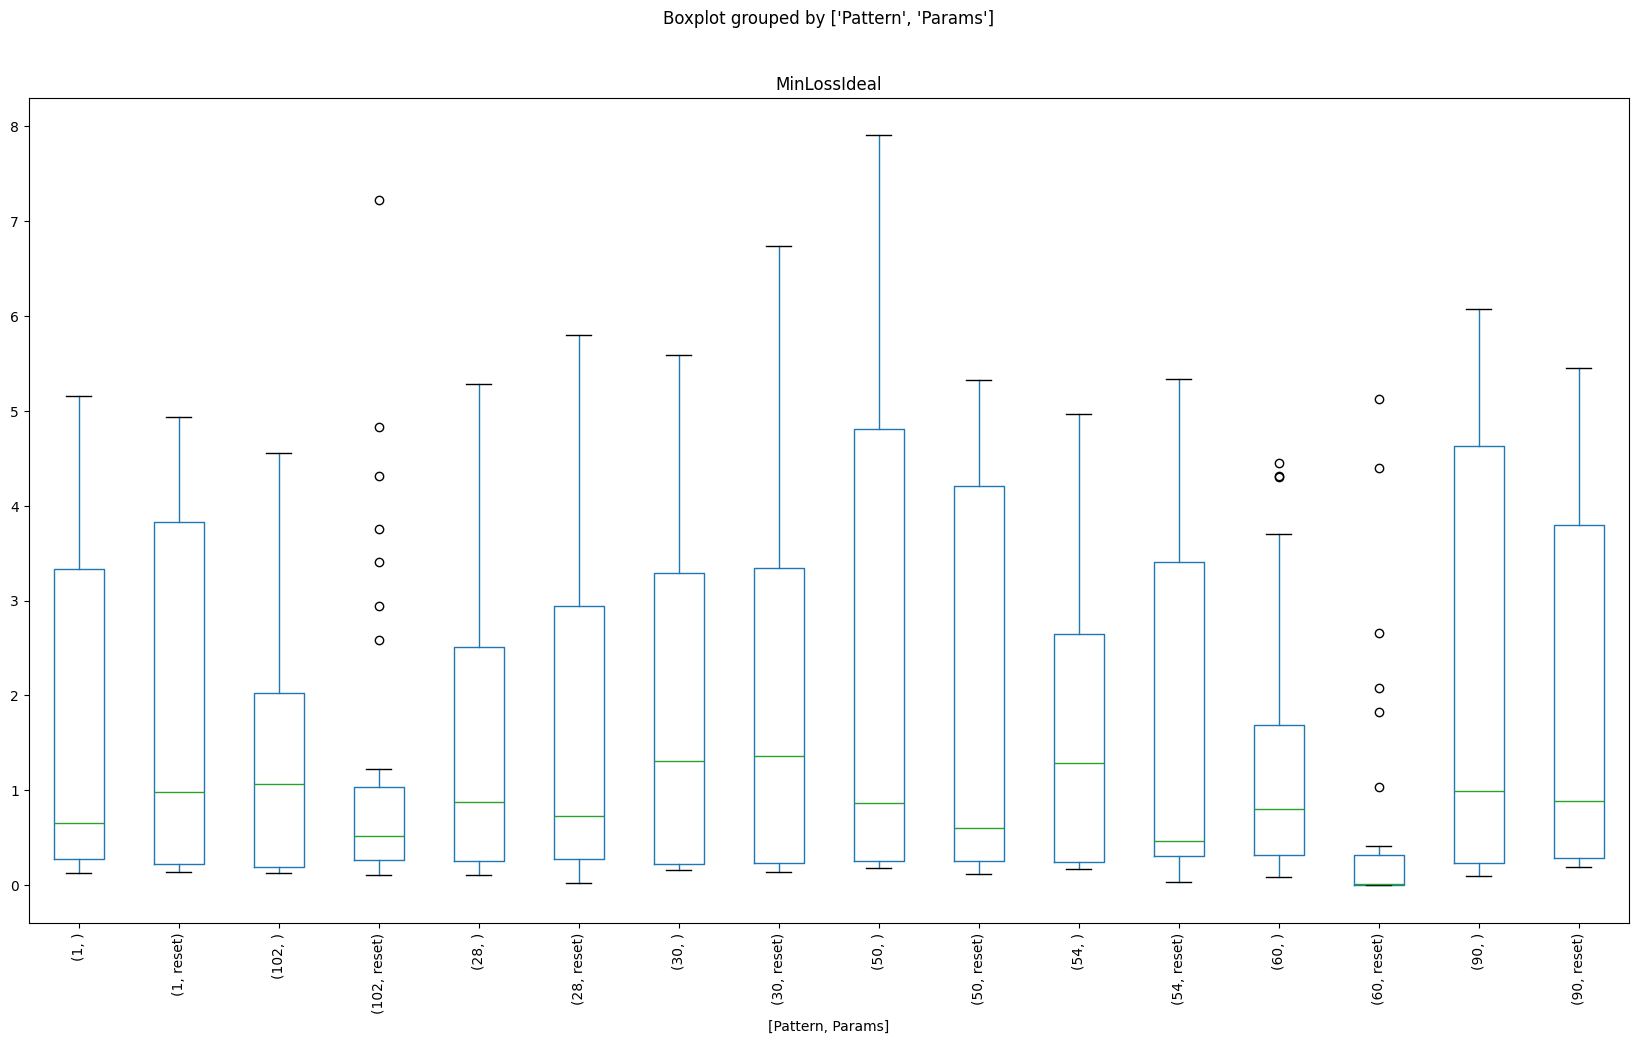

In [5]:
fig, ax = plt.subplots(1, 1, figsize=(20,11))
df.boxplot(by = ['Pattern','Params'], column = 'MinLossIdeal', rot = 90, grid=False, ax = ax)

<Axes: title={'center': 'MinLossNoise'}, xlabel='[Pattern, Params]'>

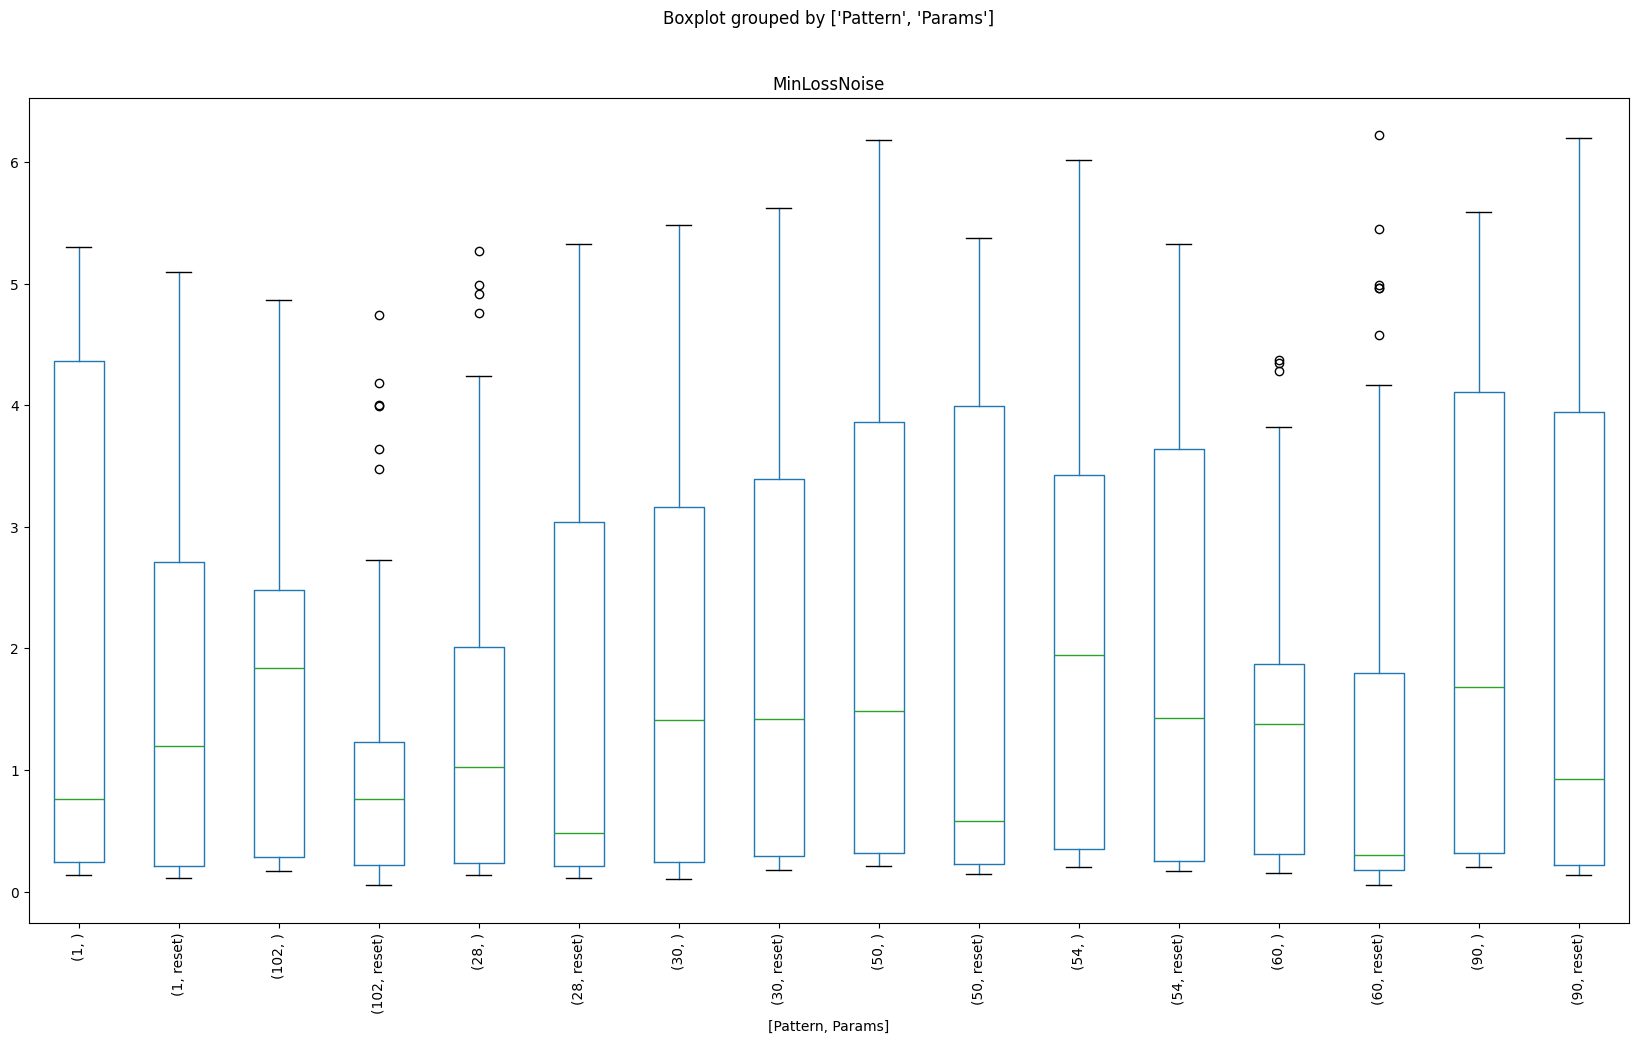

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(20,11))
df.boxplot(by = ['Pattern','Params'], column = 'MinLossNoise', rot = 90, grid=False, ax = ax)

## Best result by pattern

In [7]:
patterns = df['Pattern'].unique()

values = []

for pattern in patterns:
    df2 = df[(df['Pattern'] == pattern)]
    min_loss = df2['MinLossIdeal'].min()

    df3 = df2[df2['MinLossIdeal'] == min_loss]
    values.append(df3.values[0])


pattern_ranking = pd.DataFrame(values, columns=['Optimizer','Param', 'Pattern', 'Operator', 'MinLossIdeal', 'MinLossNoise'])

pattern_ranking

,Optimizer,Param,Pattern,Operator,MinLossIdeal,MinLossNoise
0,GA,,1,32,0.132538,0.135412
1,GA,reset,28,180,0.019600,0.346533
2,GA,reset,30,150,0.140156,0.291704
3,GA,reset,50,33,0.117797,0.192378
4,cobyla,reset,54,150,0.033976,2.296602
5,cobyla,reset,60,22,0.000000,0.121212
6,GA,,90,33,0.100639,0.284199
7,GA,reset,102,21,0.109874,0.120637


## Average performance by Operator

In [8]:
operators = df['Operator'].unique()

values = []

for operator in operators:
    df2 = df[(df['Operator'] == operator)]
    min_loss = df2['MinLossIdeal'].min()
    max_loss = df2['MinLossIdeal'].max()
    avg_loss = df2['MinLossIdeal'].mean()
    std_loss = df2['MinLossIdeal'].std()

    values.append([operator, min_loss, avg_loss, std_loss, max_loss])

values = sorted(values, key = lambda v: v[2])

operator_ranking = pd.DataFrame(values, columns=['Operator', 'Min Loss', 'Avg Loss', 'Std Loss', 'Max Loss'])

operator_ranking

,Operator,Min Loss,Avg Loss,Std Loss,Max Loss
0,32,0.001200,0.953924,1.117939,4.777778
1,33,0.000000,1.126951,1.181457,4.586777
2,180,0.012856,1.350041,1.653661,7.224059
3,92,0.006100,1.394696,1.761206,6.734619
4,22,0.000000,1.480552,1.797402,5.286501
5,42,0.005200,1.503494,1.524873,5.202938
6,21,0.000000,1.506090,1.785248,5.210285
7,120,0.000700,1.535467,1.665425,5.282828
8,60,0.000000,1.577394,1.755180,4.876951
9,43,0.013774,1.642012,1.623450,4.945822


<Axes: title={'center': 'MinLossIdeal'}, xlabel='[Operator, Params]'>

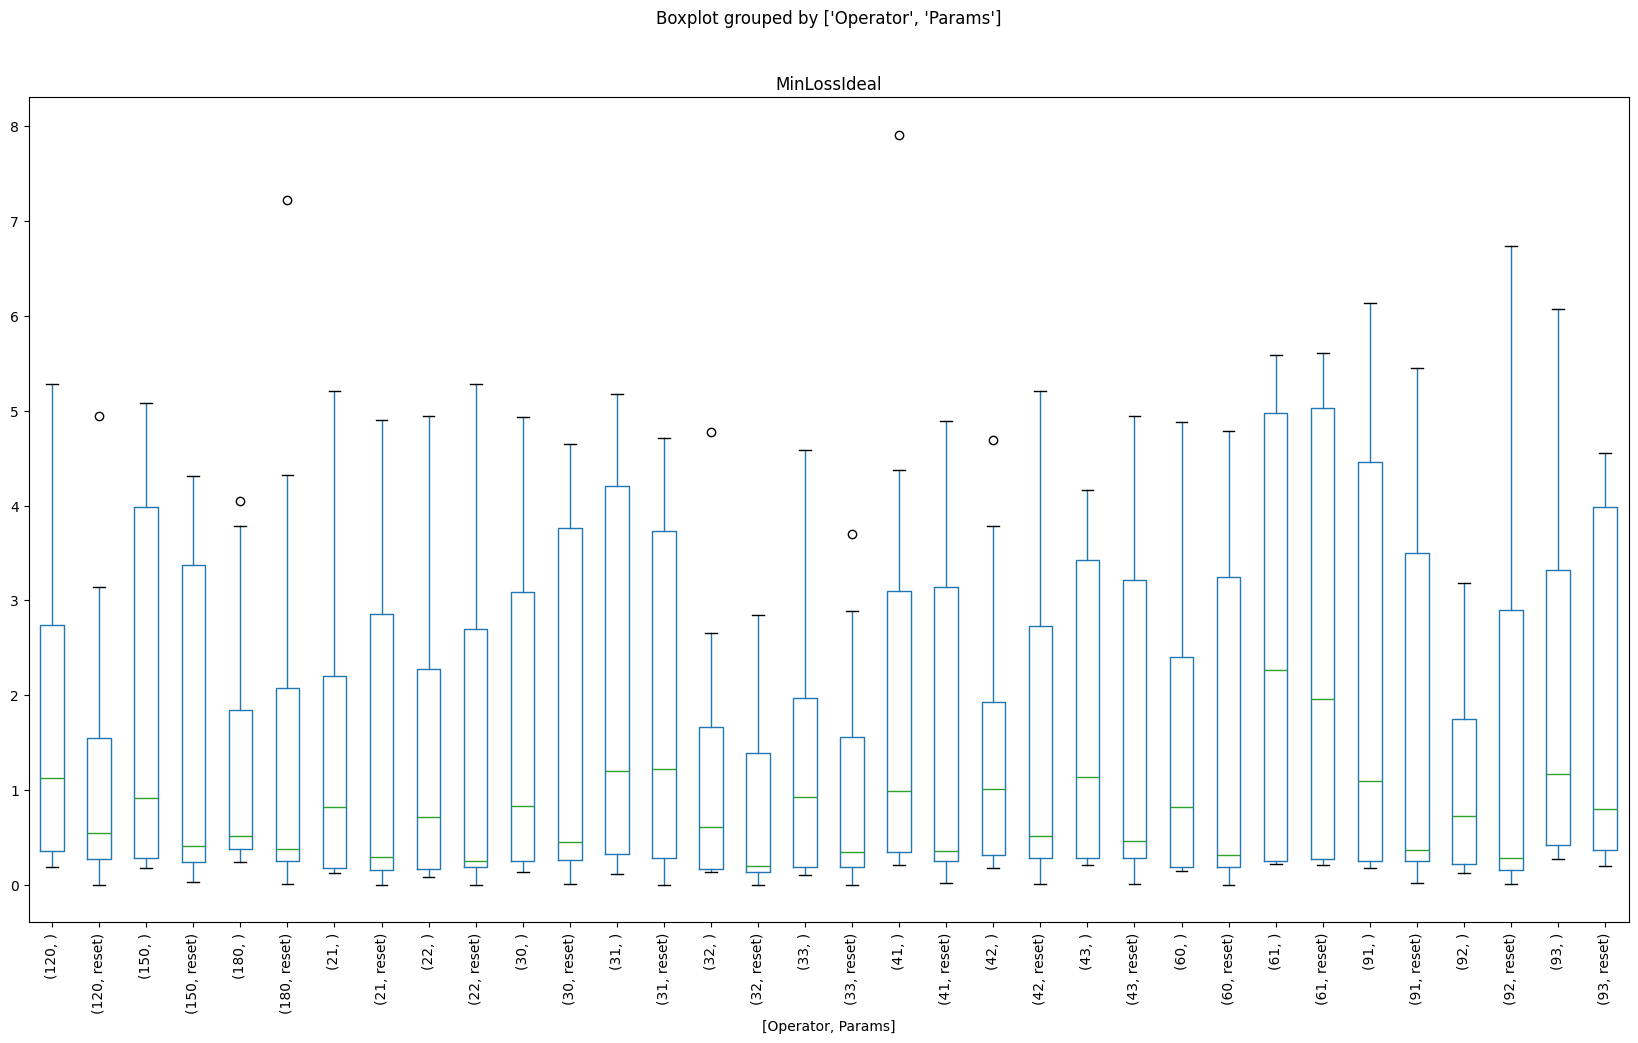

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(20,11))
df.boxplot(by = ['Operator','Params'], column = 'MinLossIdeal', rot = 90, grid=False, ax=ax)

<Axes: title={'center': 'MinLossNoise'}, xlabel='[Operator, Params]'>

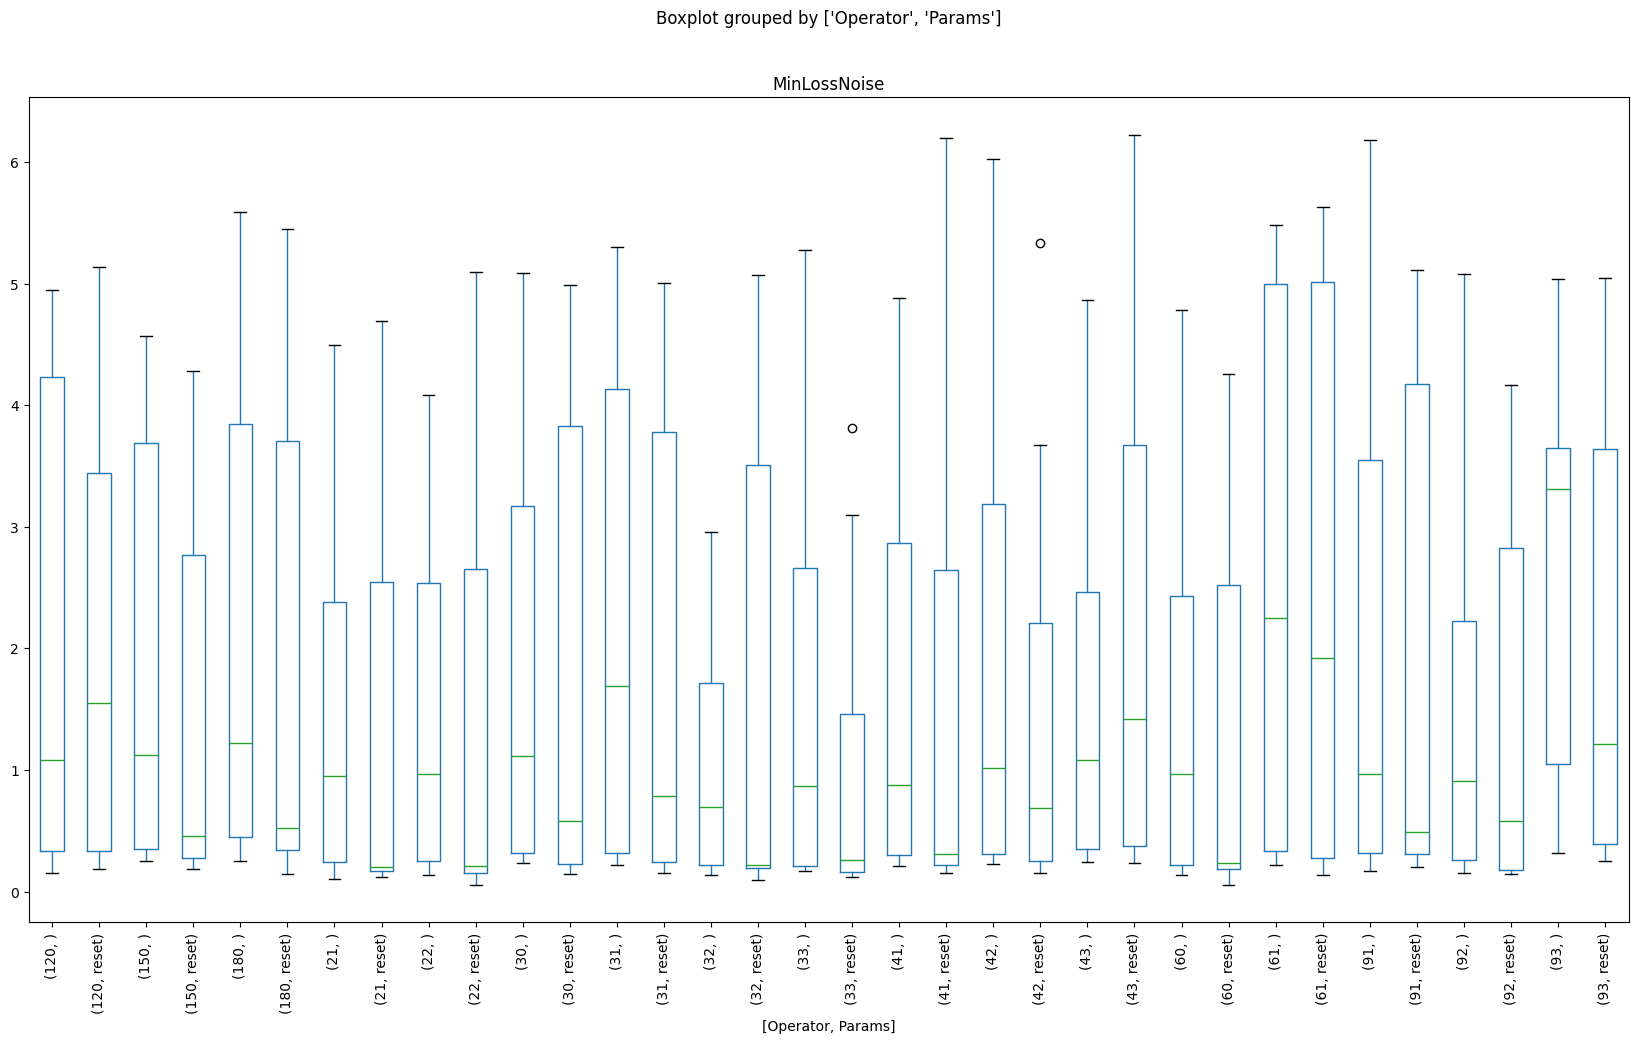

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(20,11))
df.boxplot(by = ['Operator','Params'], column = 'MinLossNoise', rot = 90, grid=False, ax=ax)

# Cobyla Results for VQCA Training

## Reversible (No Reset)

#### Ideal

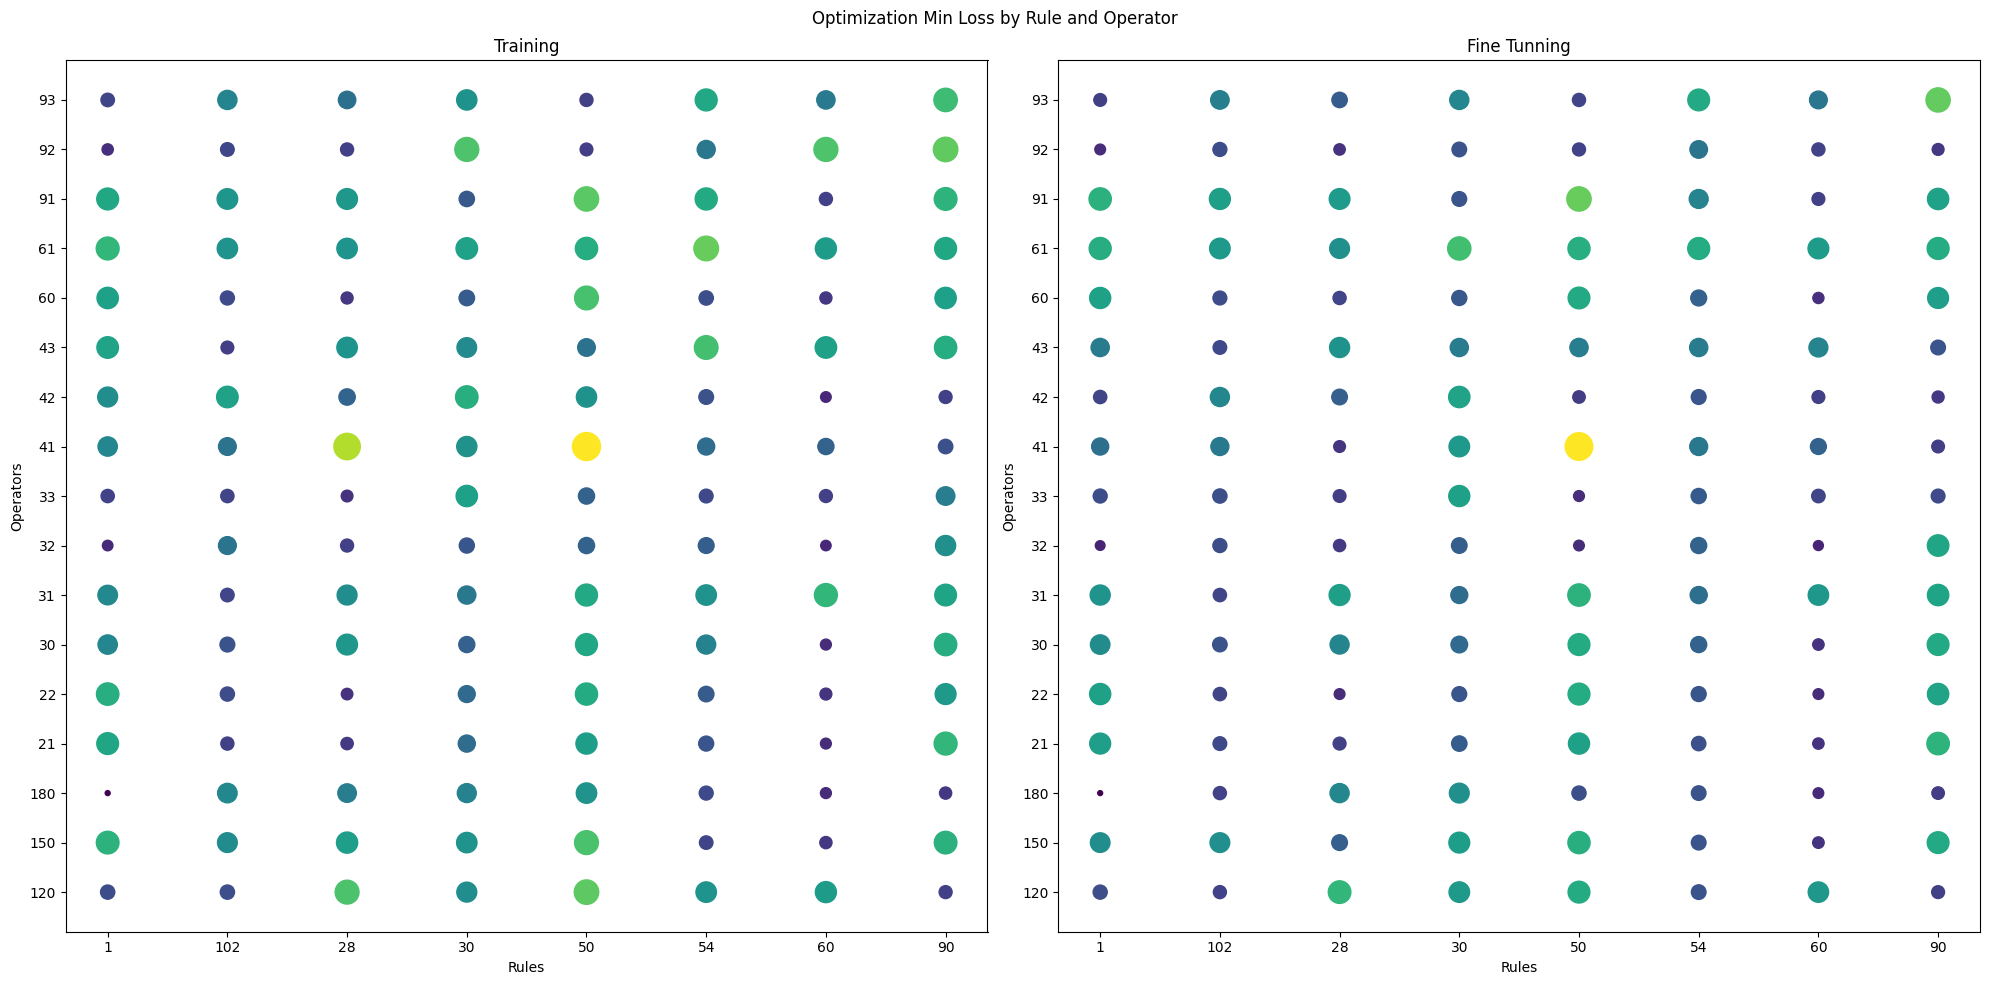

In [11]:
experiments = base.VQCAGlobalOptimizer(ca_patterns.rules, cobyla.VQCAOptimizerCOBYLA, path = DIRETORIO_PADRAO)
experiments.plot_results()

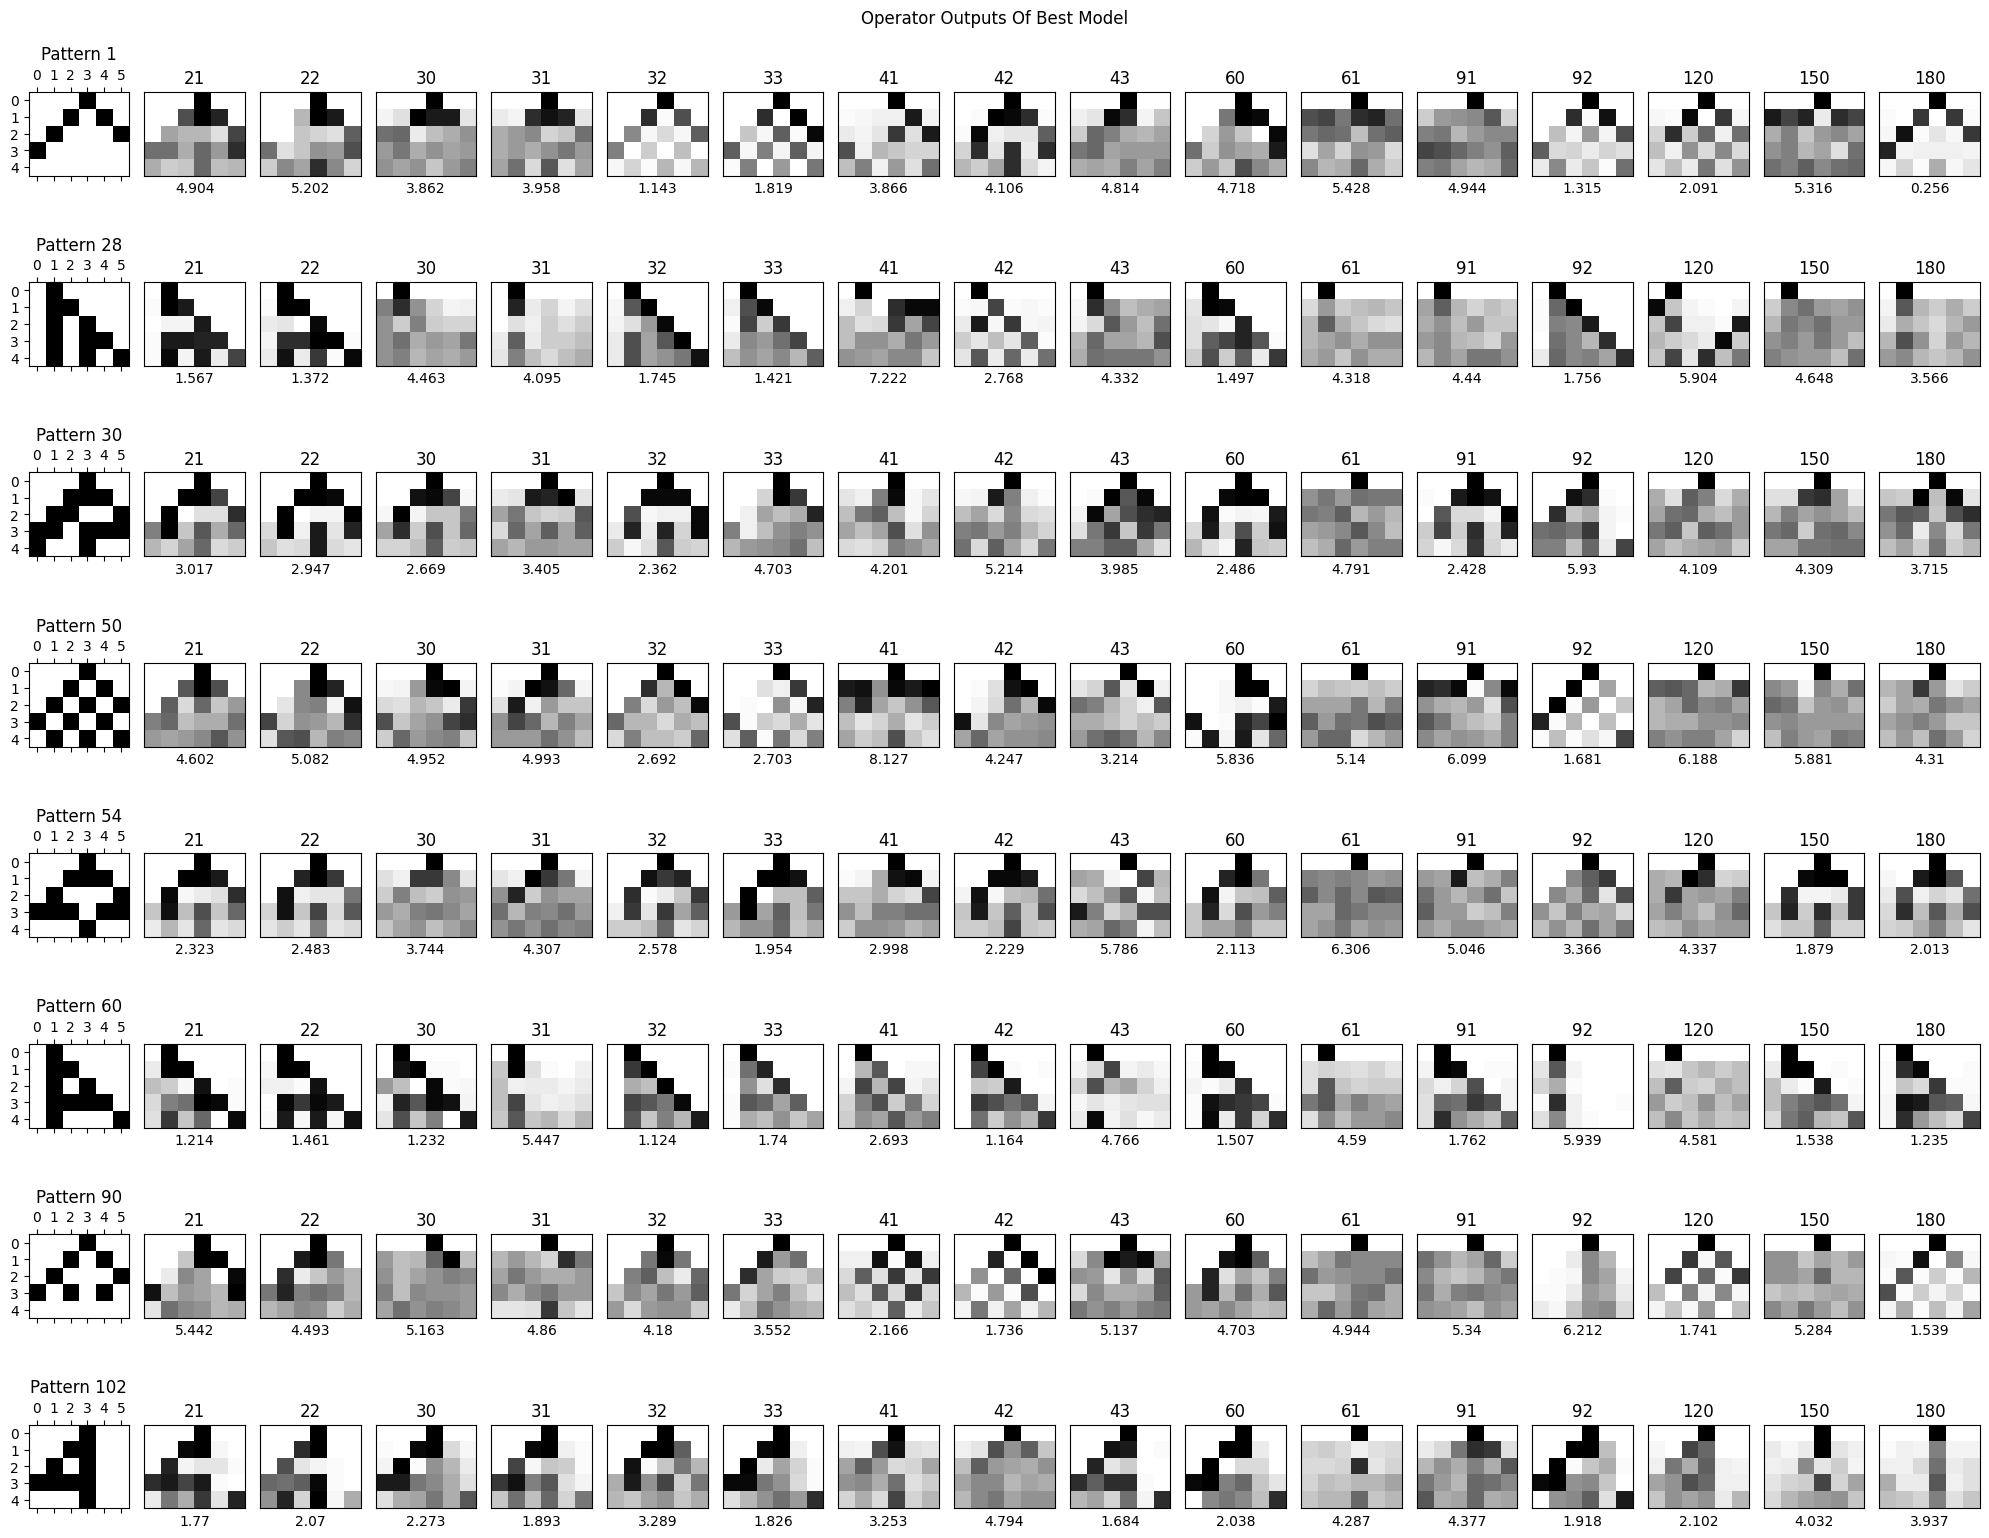

In [12]:
experiments.plot_outputs()

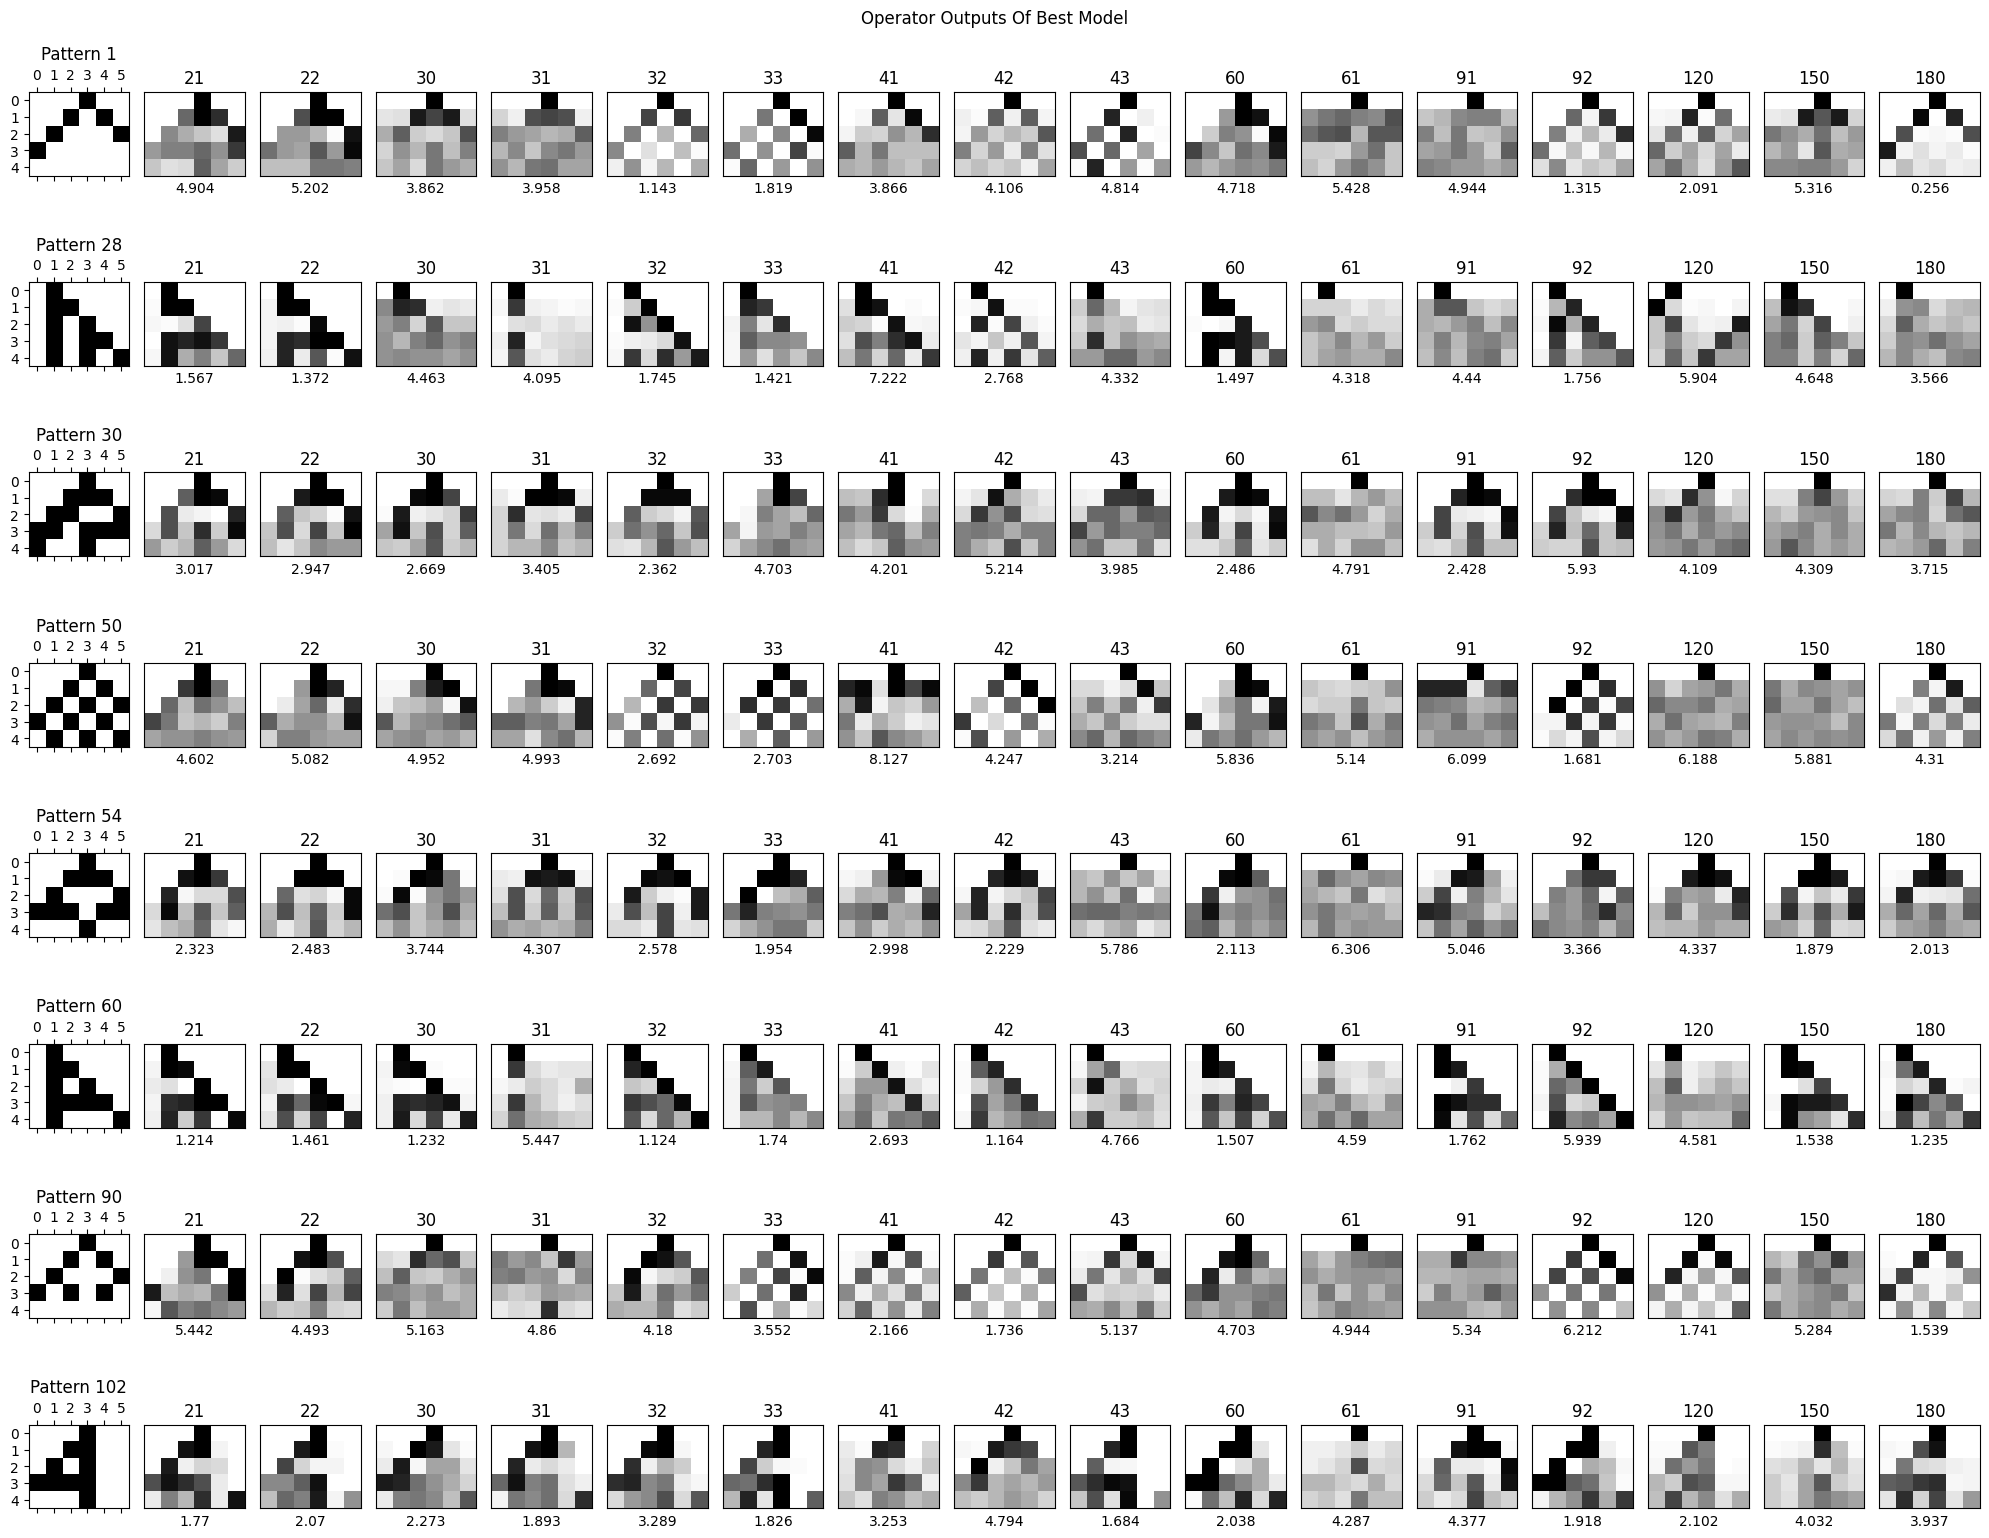

In [13]:
experiments.plot_outputs(finetunning=True)

#### Noisy

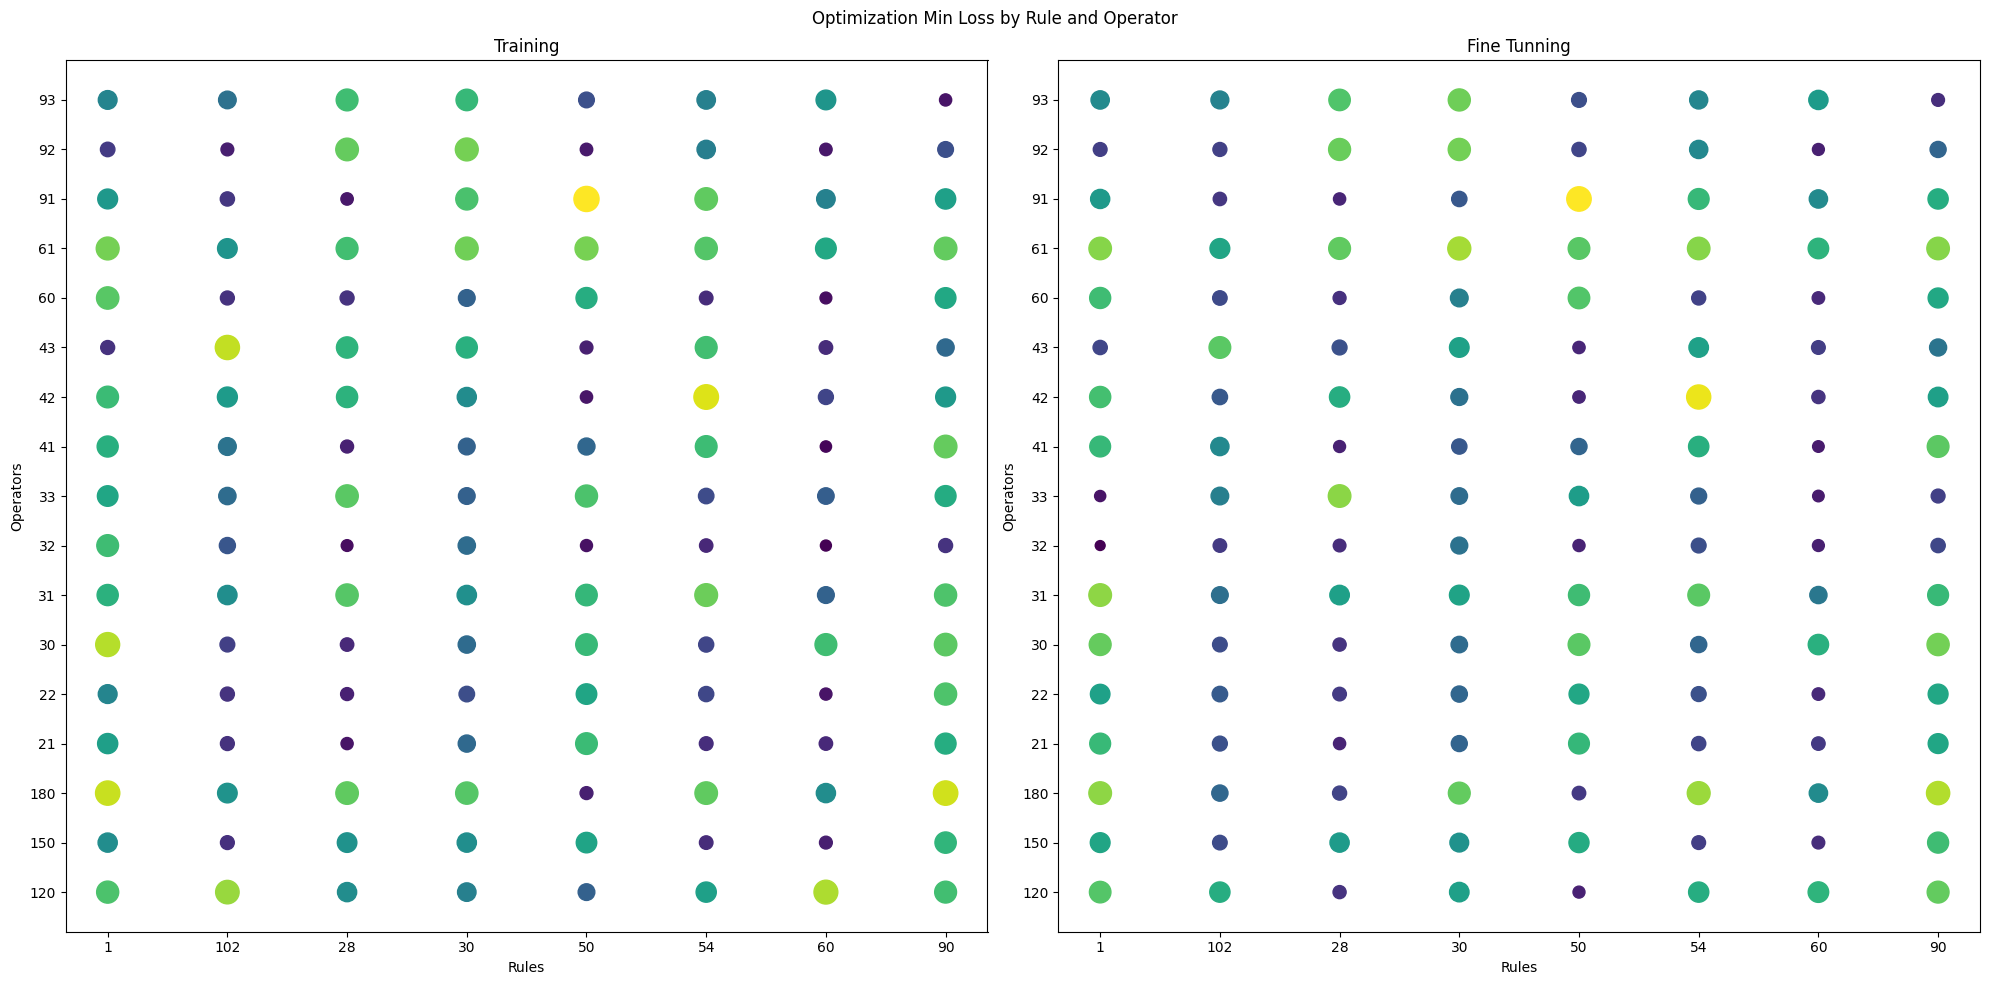

In [14]:
experiments = base.VQCAGlobalOptimizer(ca_patterns.rules, cobyla.VQCAOptimizerCOBYLA, path = DIRETORIO_PADRAO, noise = True)
experiments.plot_results()

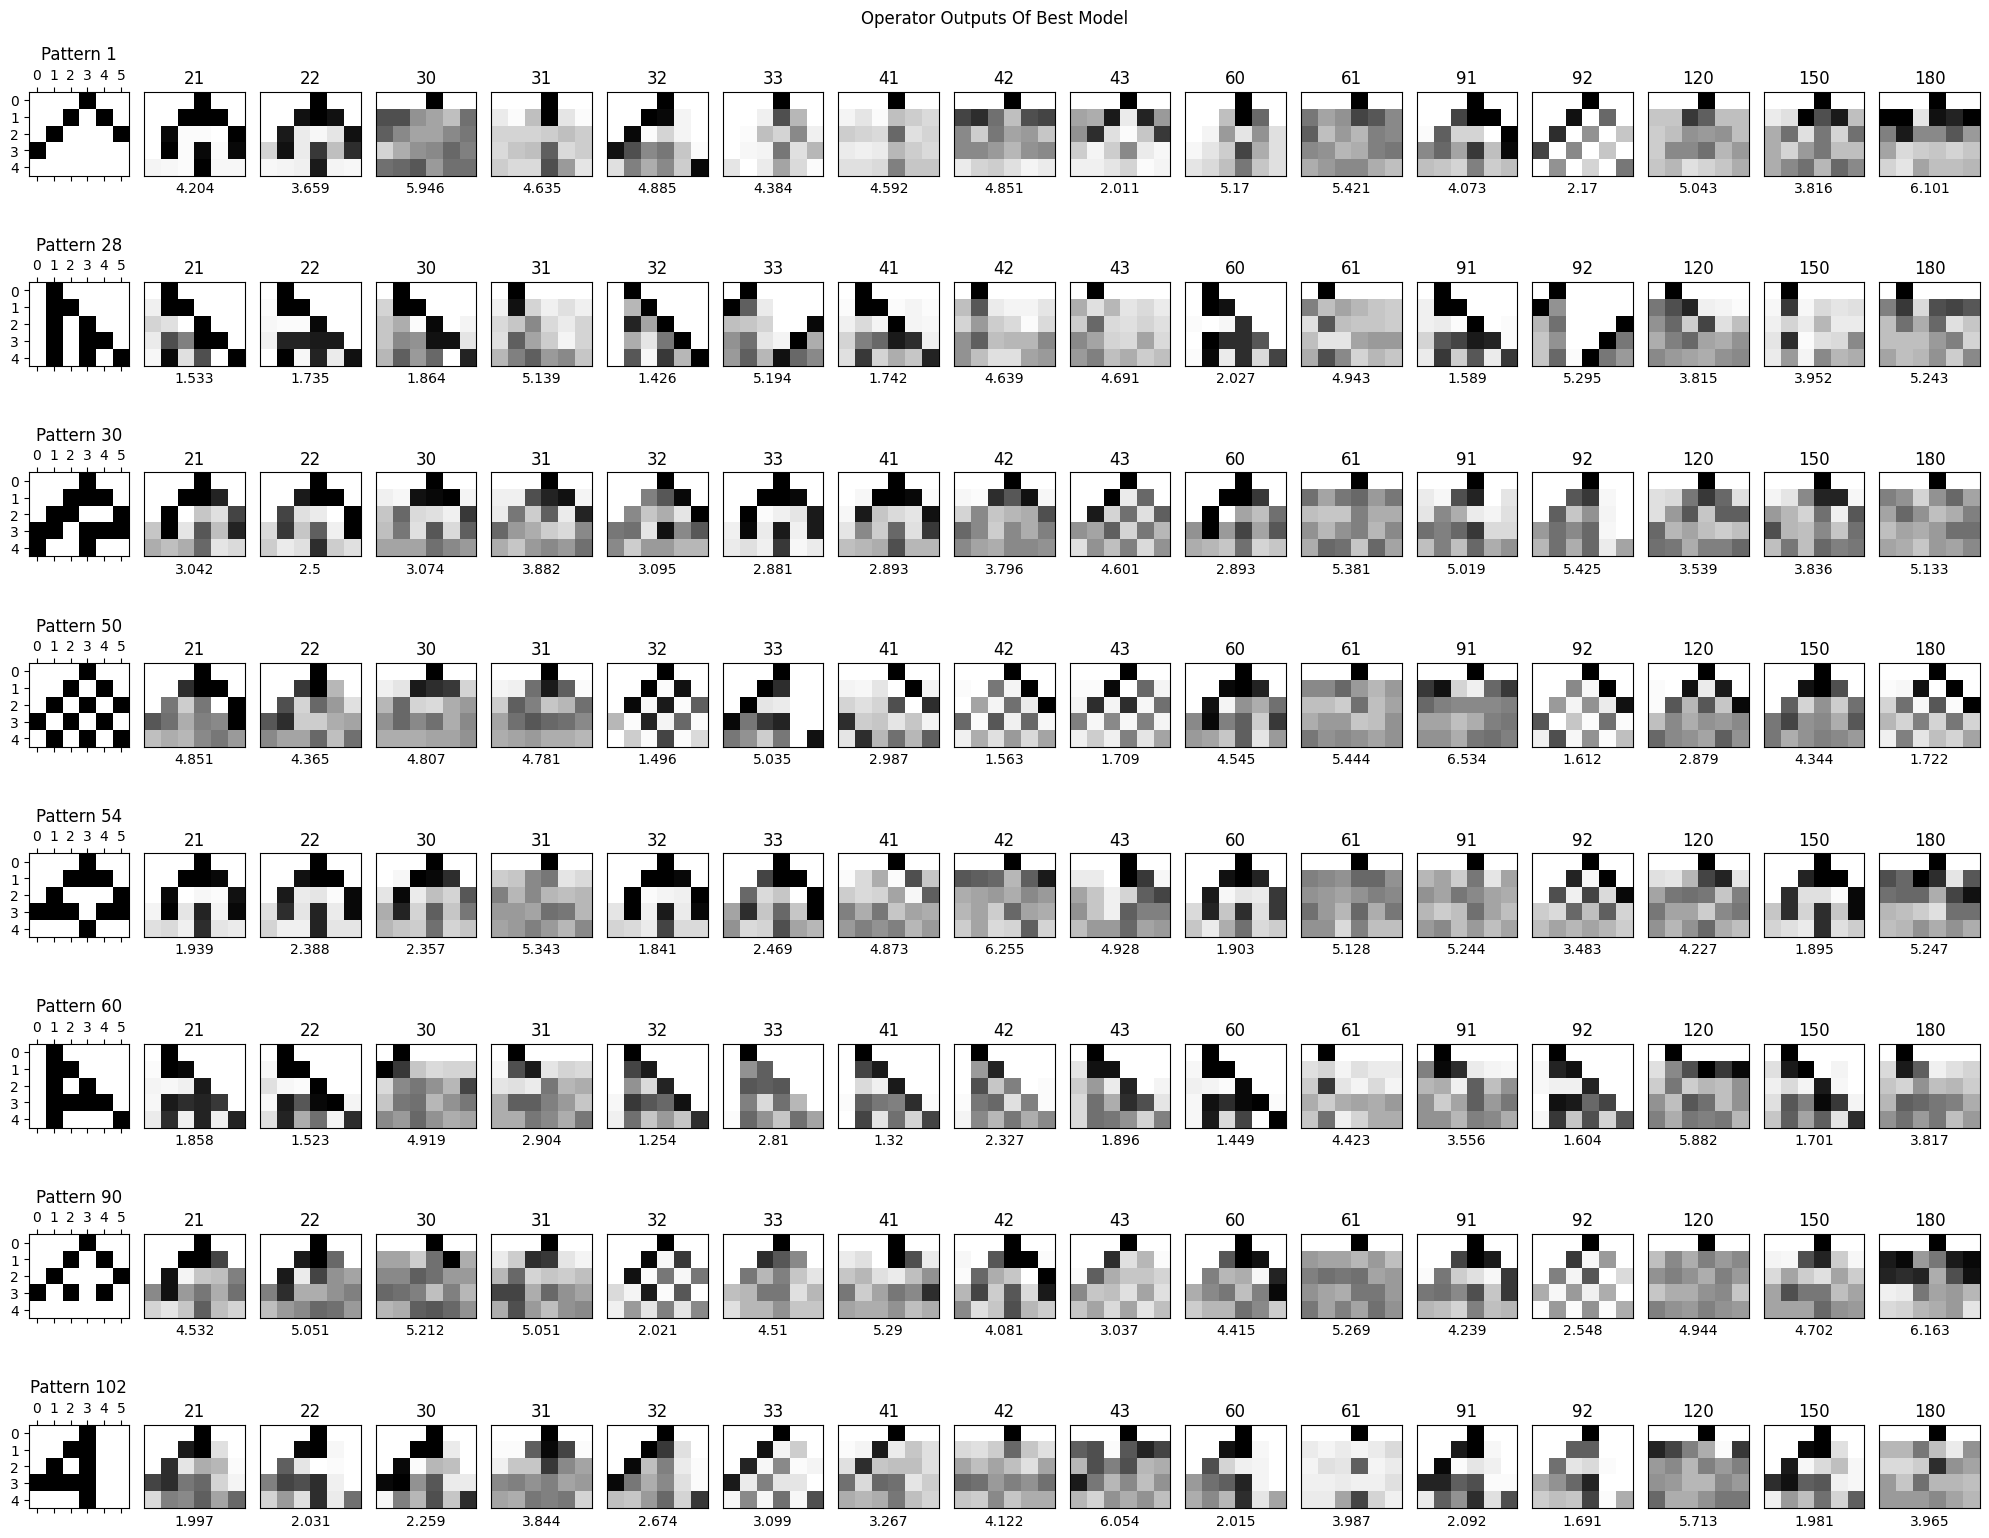

In [15]:
experiments.plot_outputs()

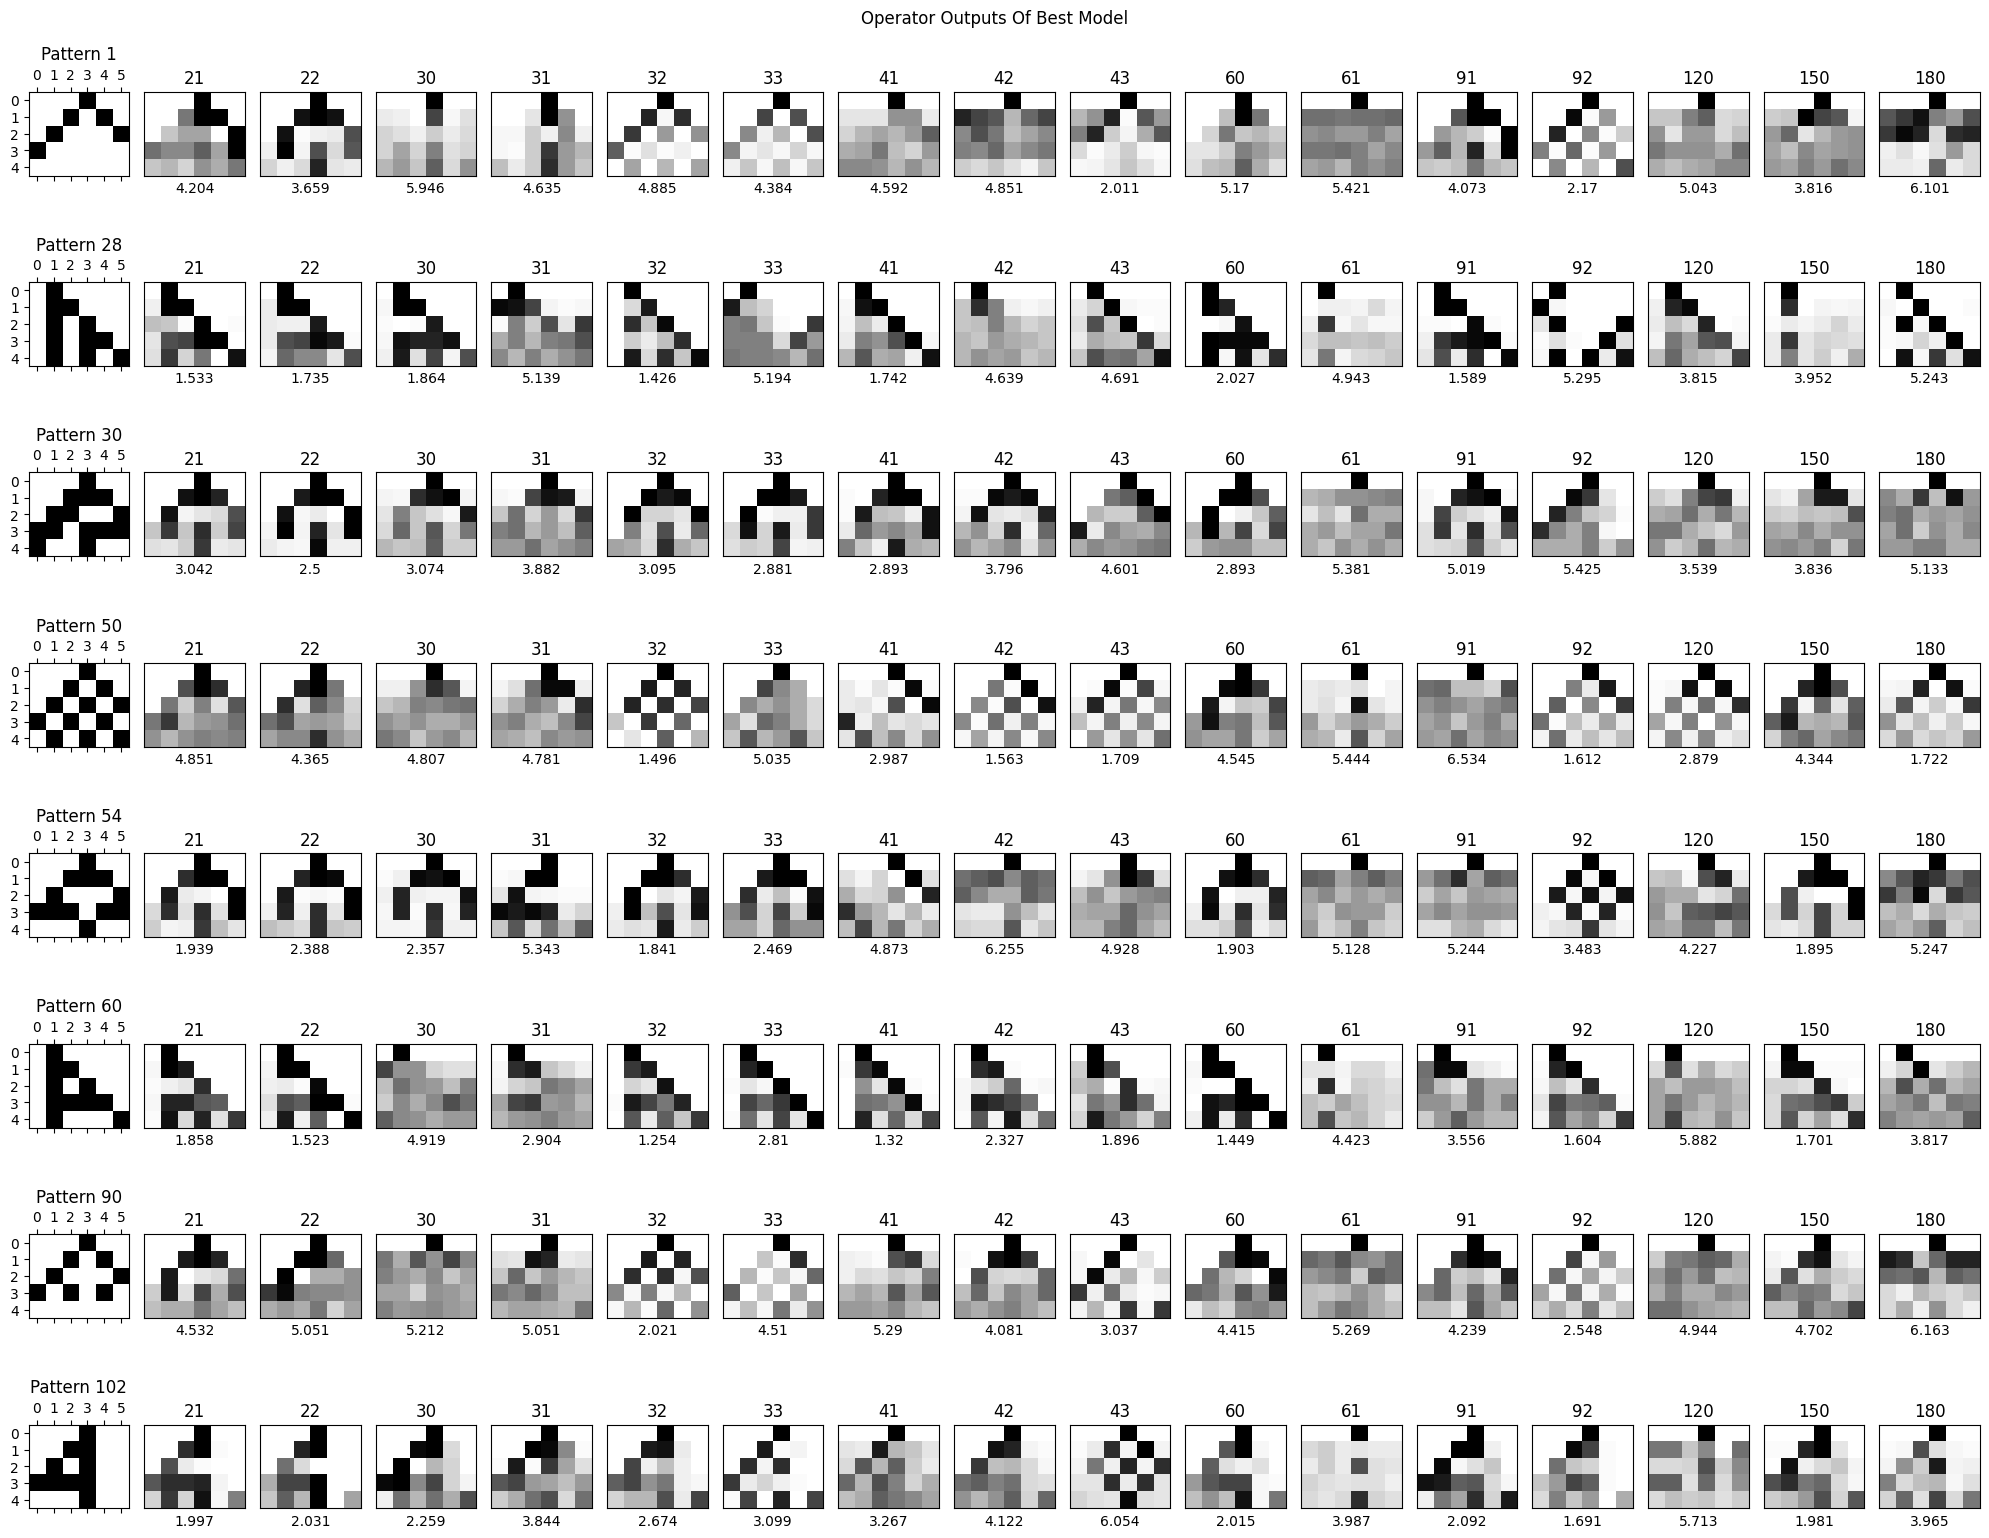

In [16]:
experiments.plot_outputs(finetunning=True)

## Irreversible (with Reset)

#### Ideal

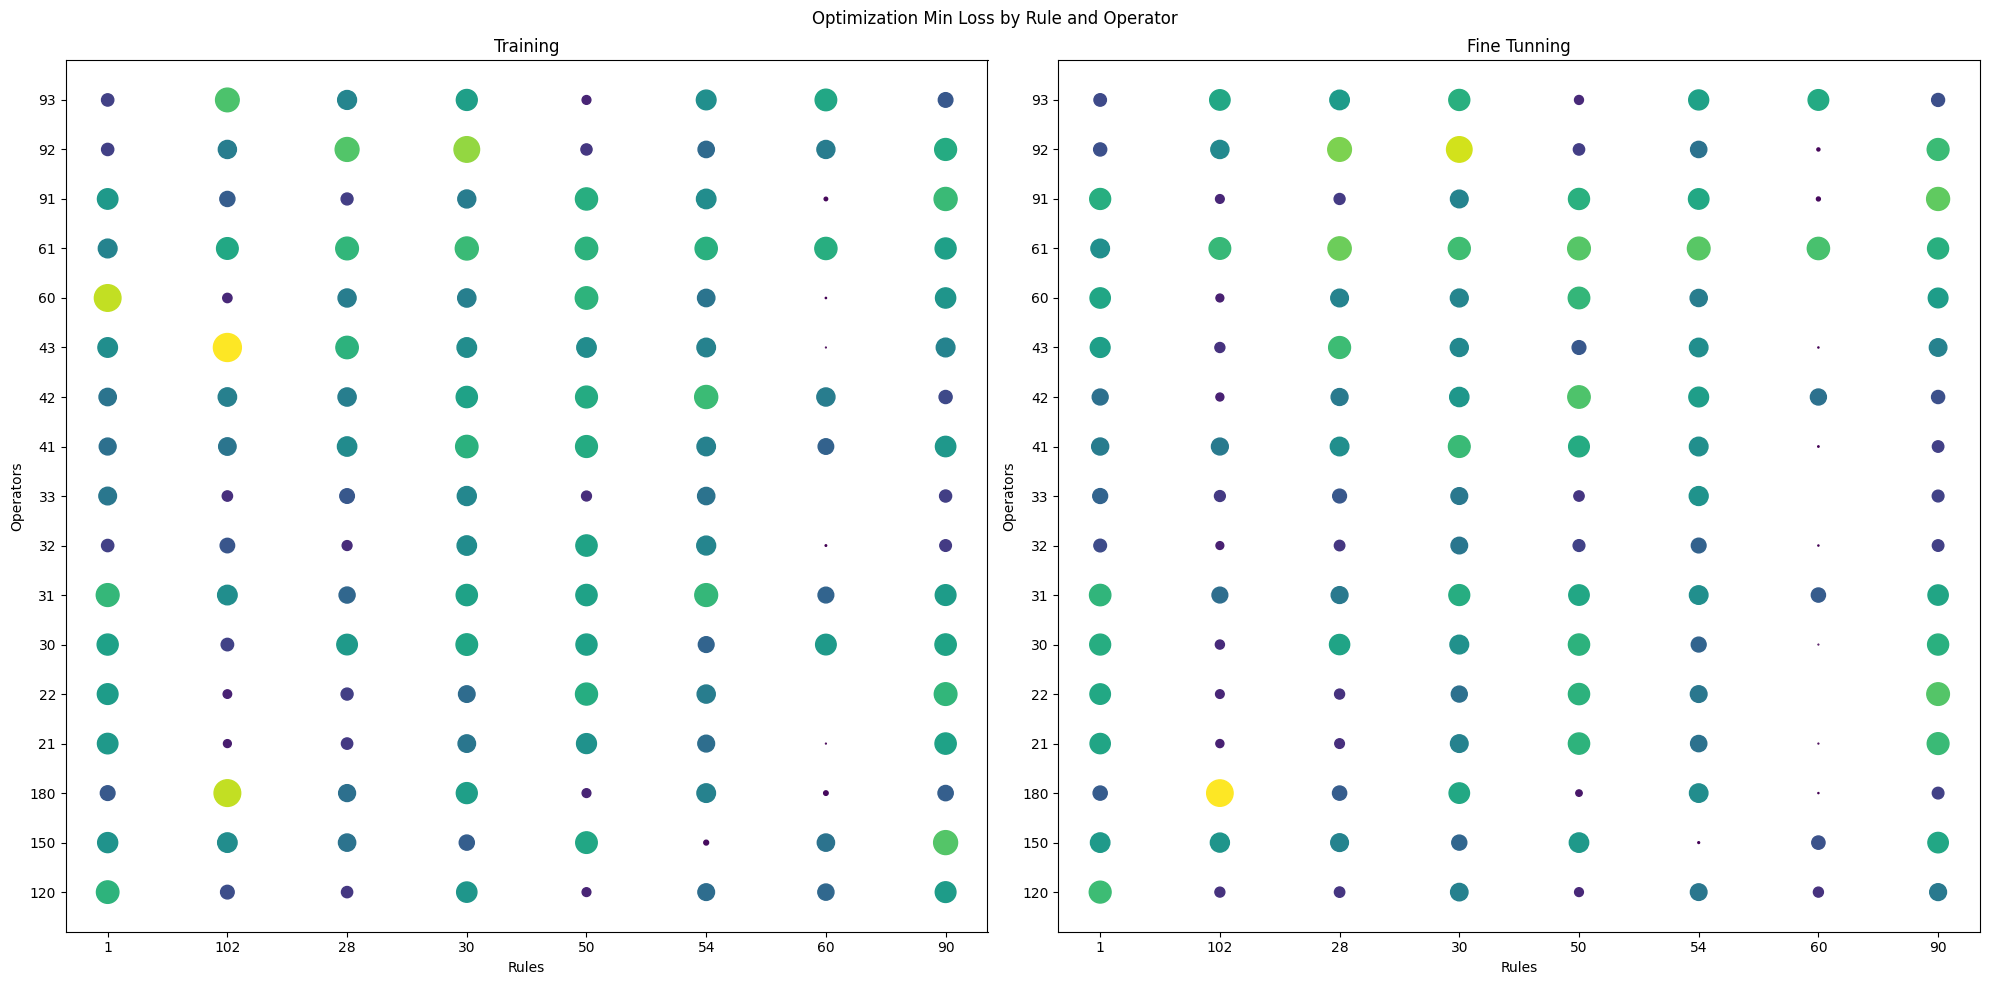

In [17]:
experiments = base.VQCAGlobalOptimizer(ca_patterns.rules, cobyla.VQCAOptimizerCOBYLA, \
                                       path = DIRETORIO_PADRAO, reset = True)
experiments.plot_results()

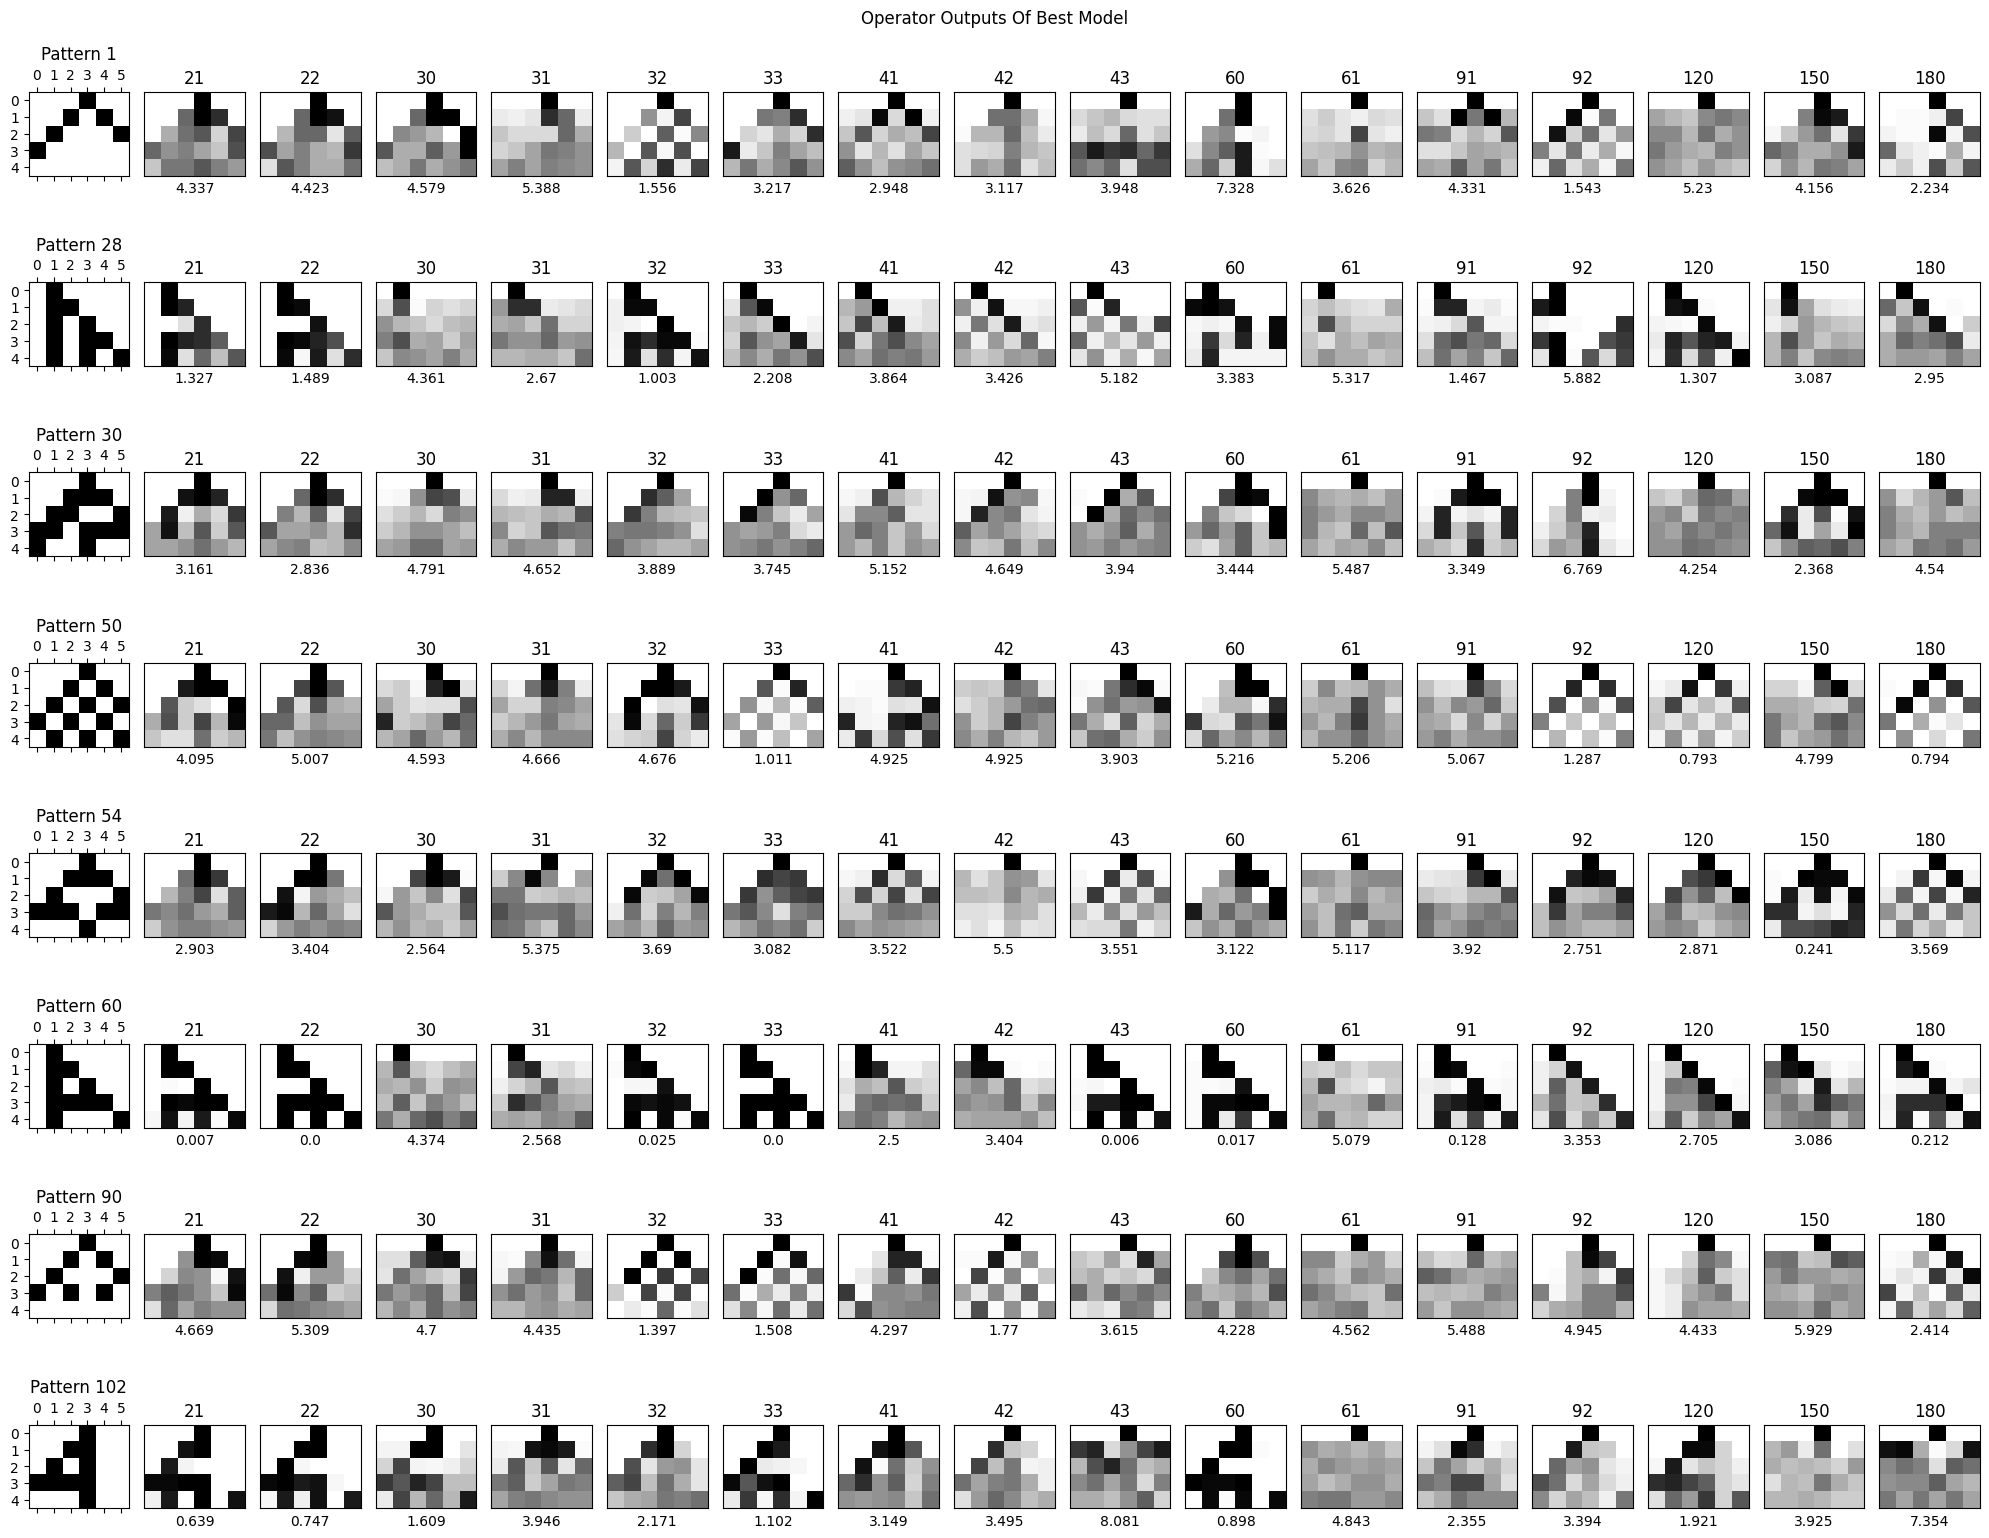

In [18]:
experiments.plot_outputs()

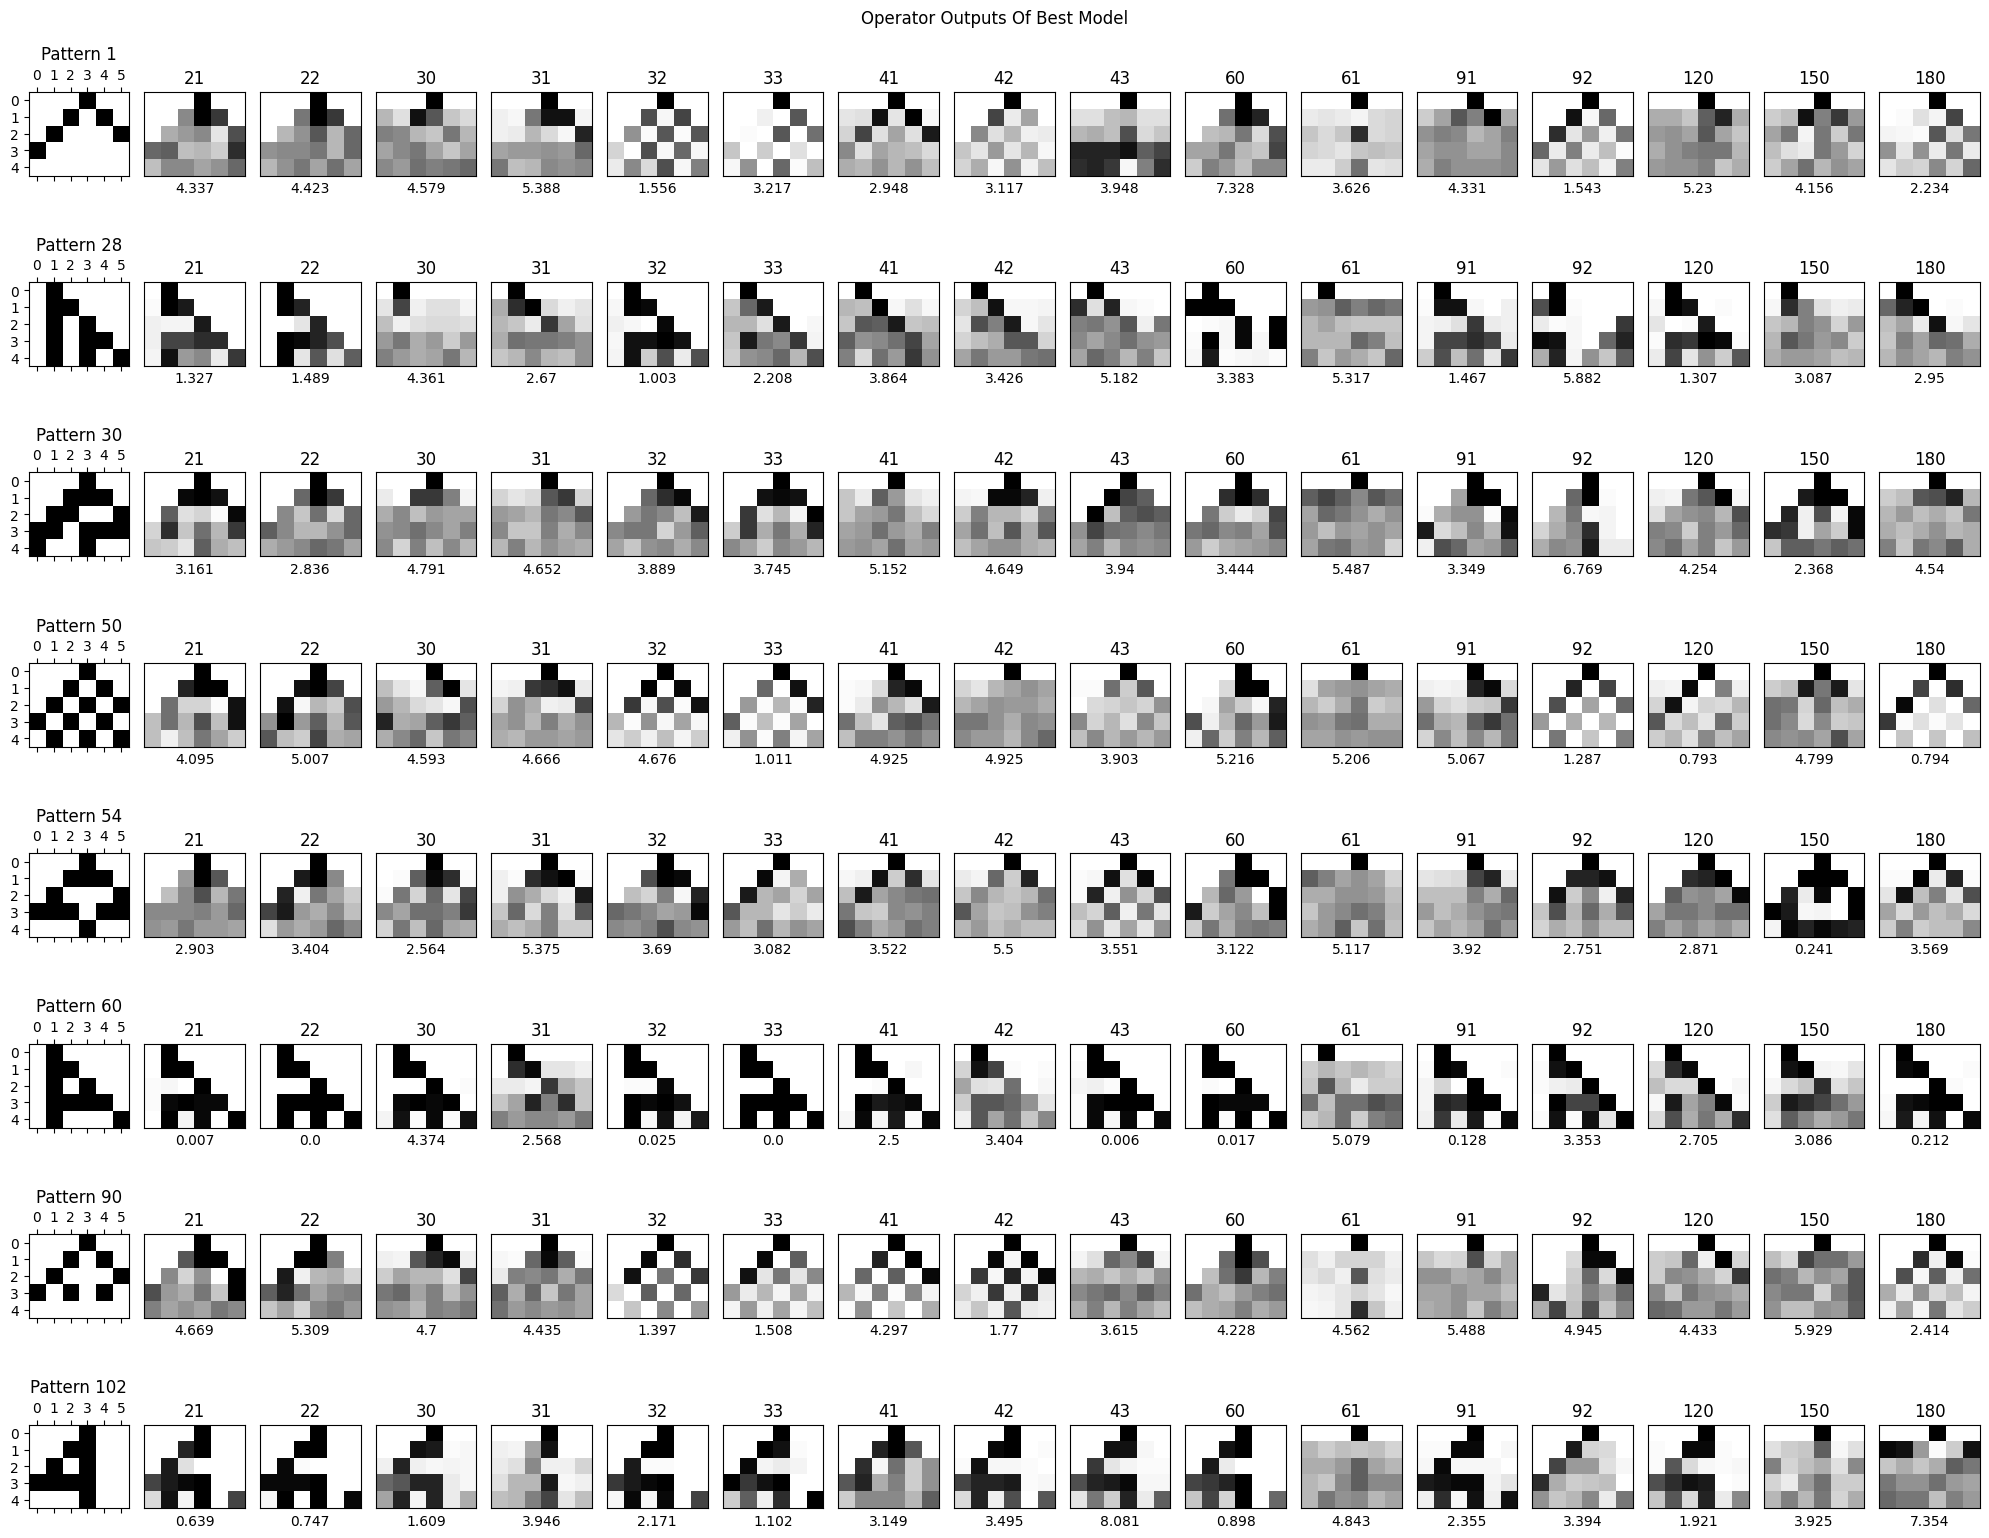

In [19]:
experiments.plot_outputs(finetunning=True)

#### Noisy

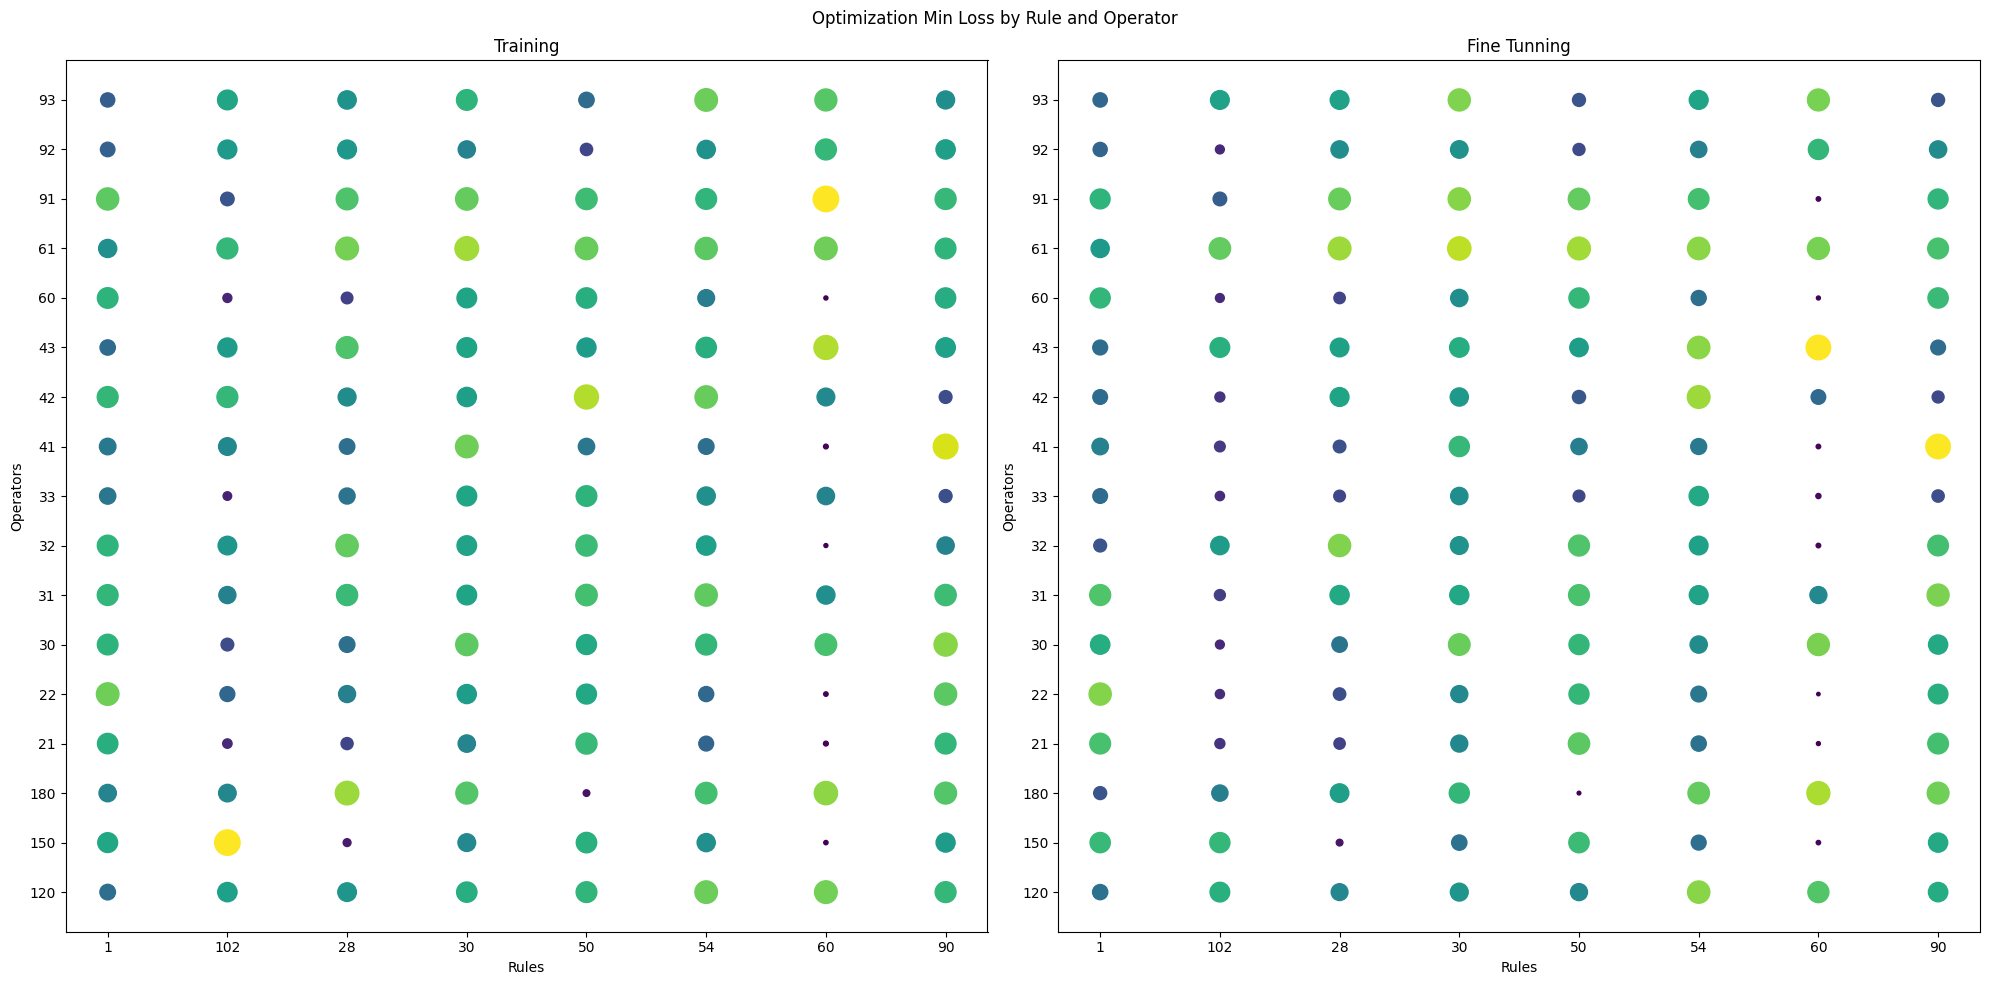

In [20]:
experiments = base.VQCAGlobalOptimizer(ca_patterns.rules, cobyla.VQCAOptimizerCOBYLA, \
                                       path = DIRETORIO_PADRAO, reset = True, noise = True)
experiments.plot_results()

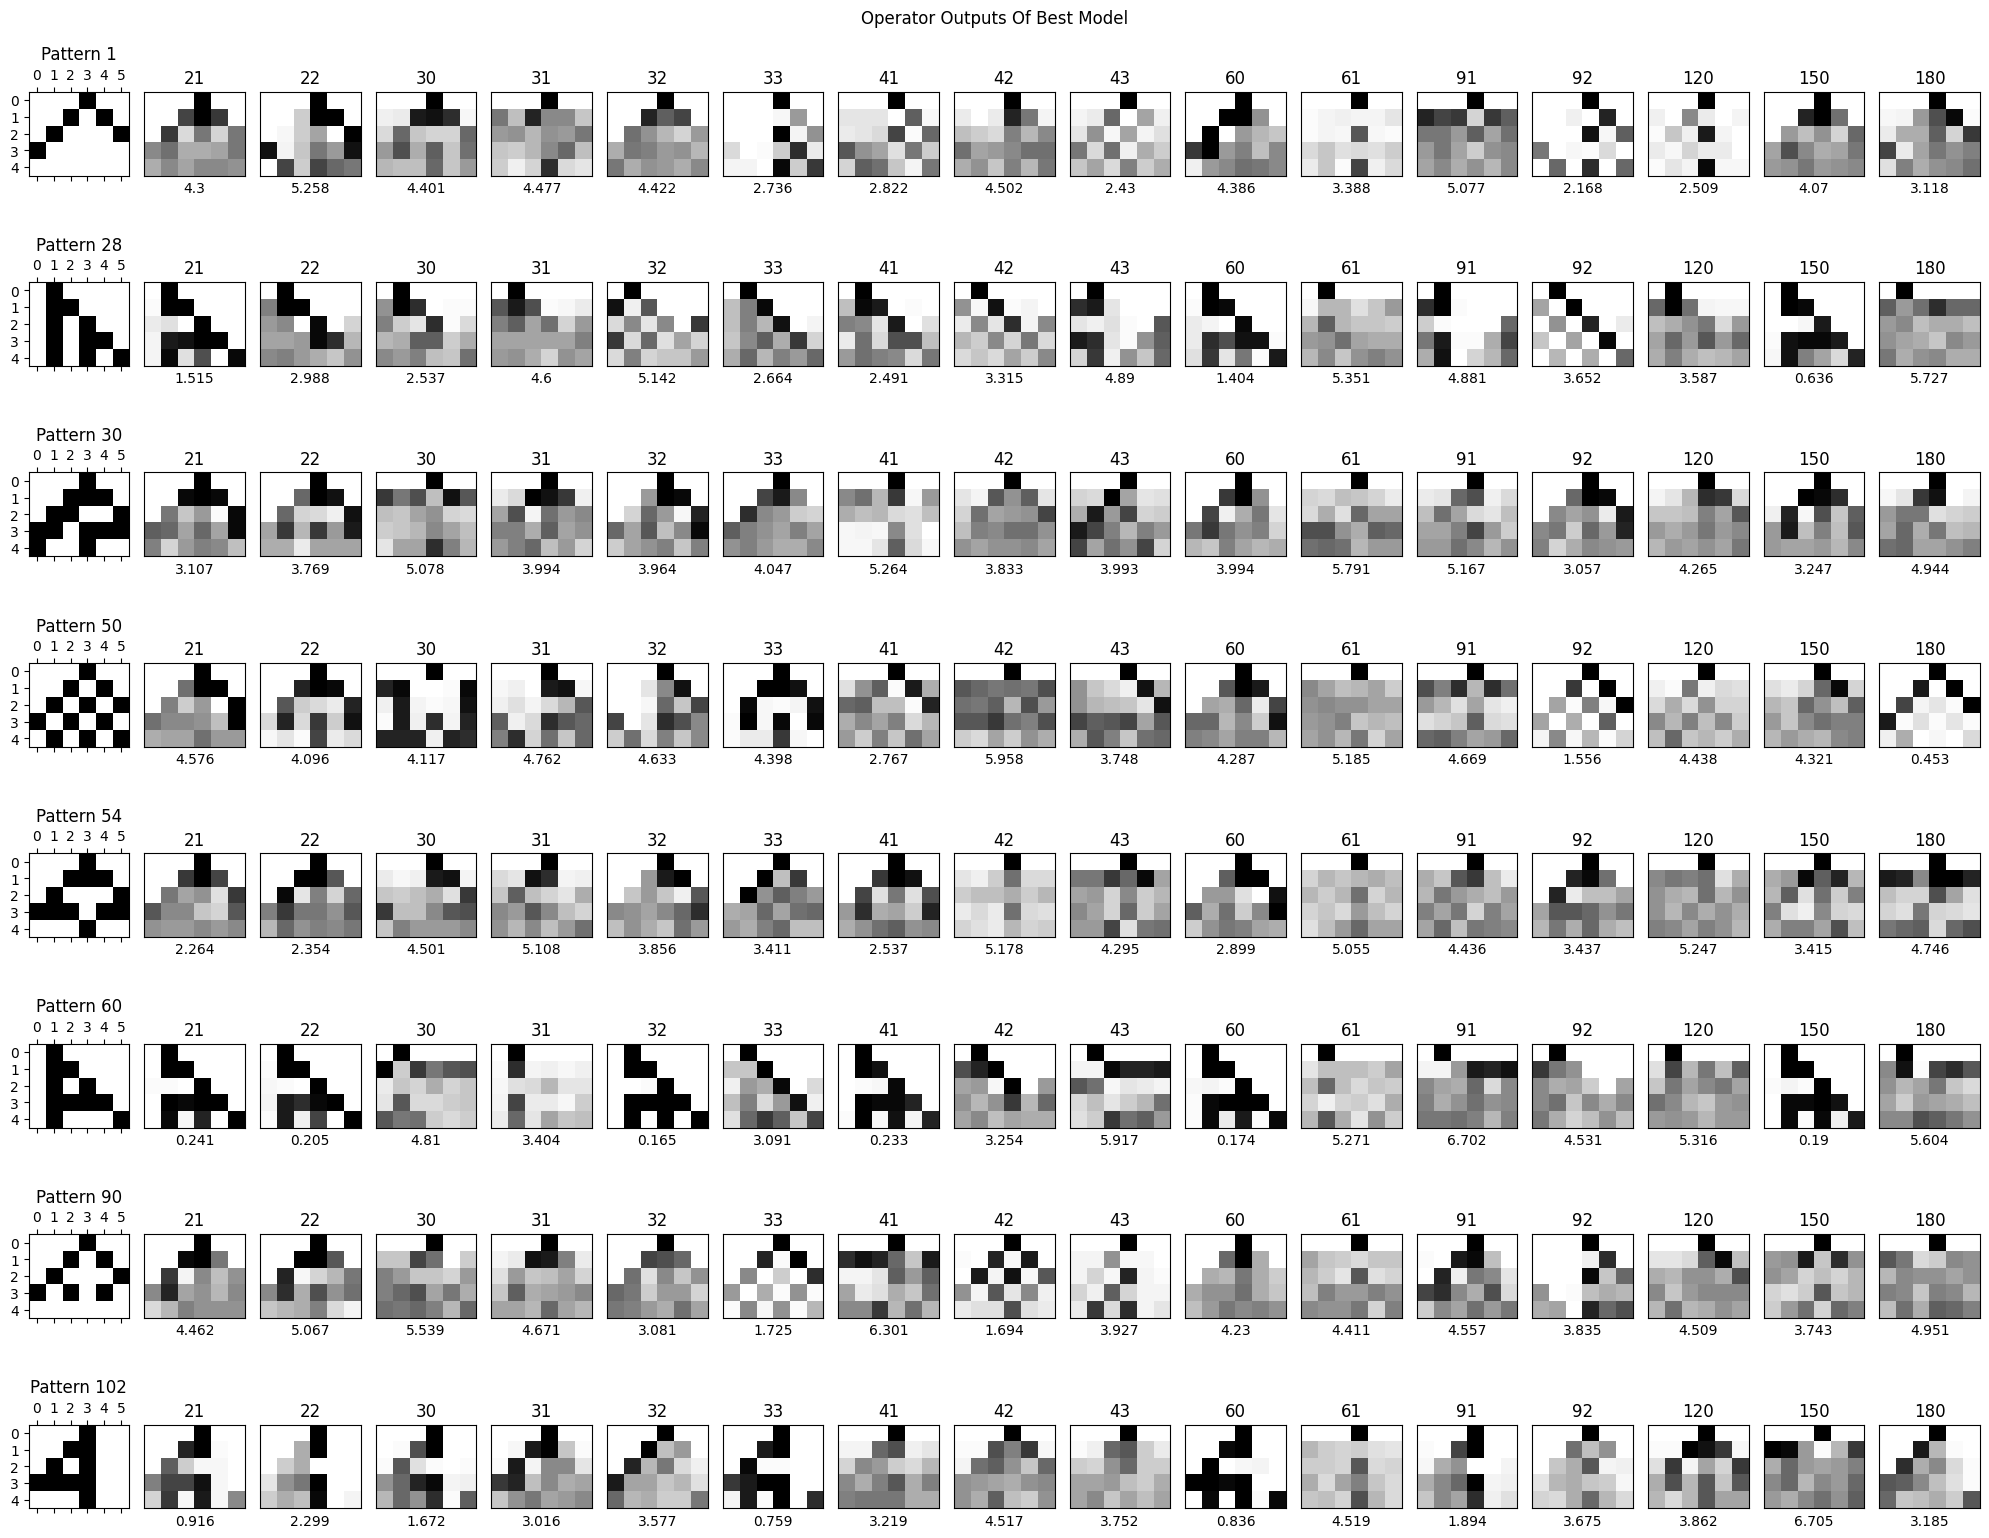

In [21]:
experiments.plot_outputs()

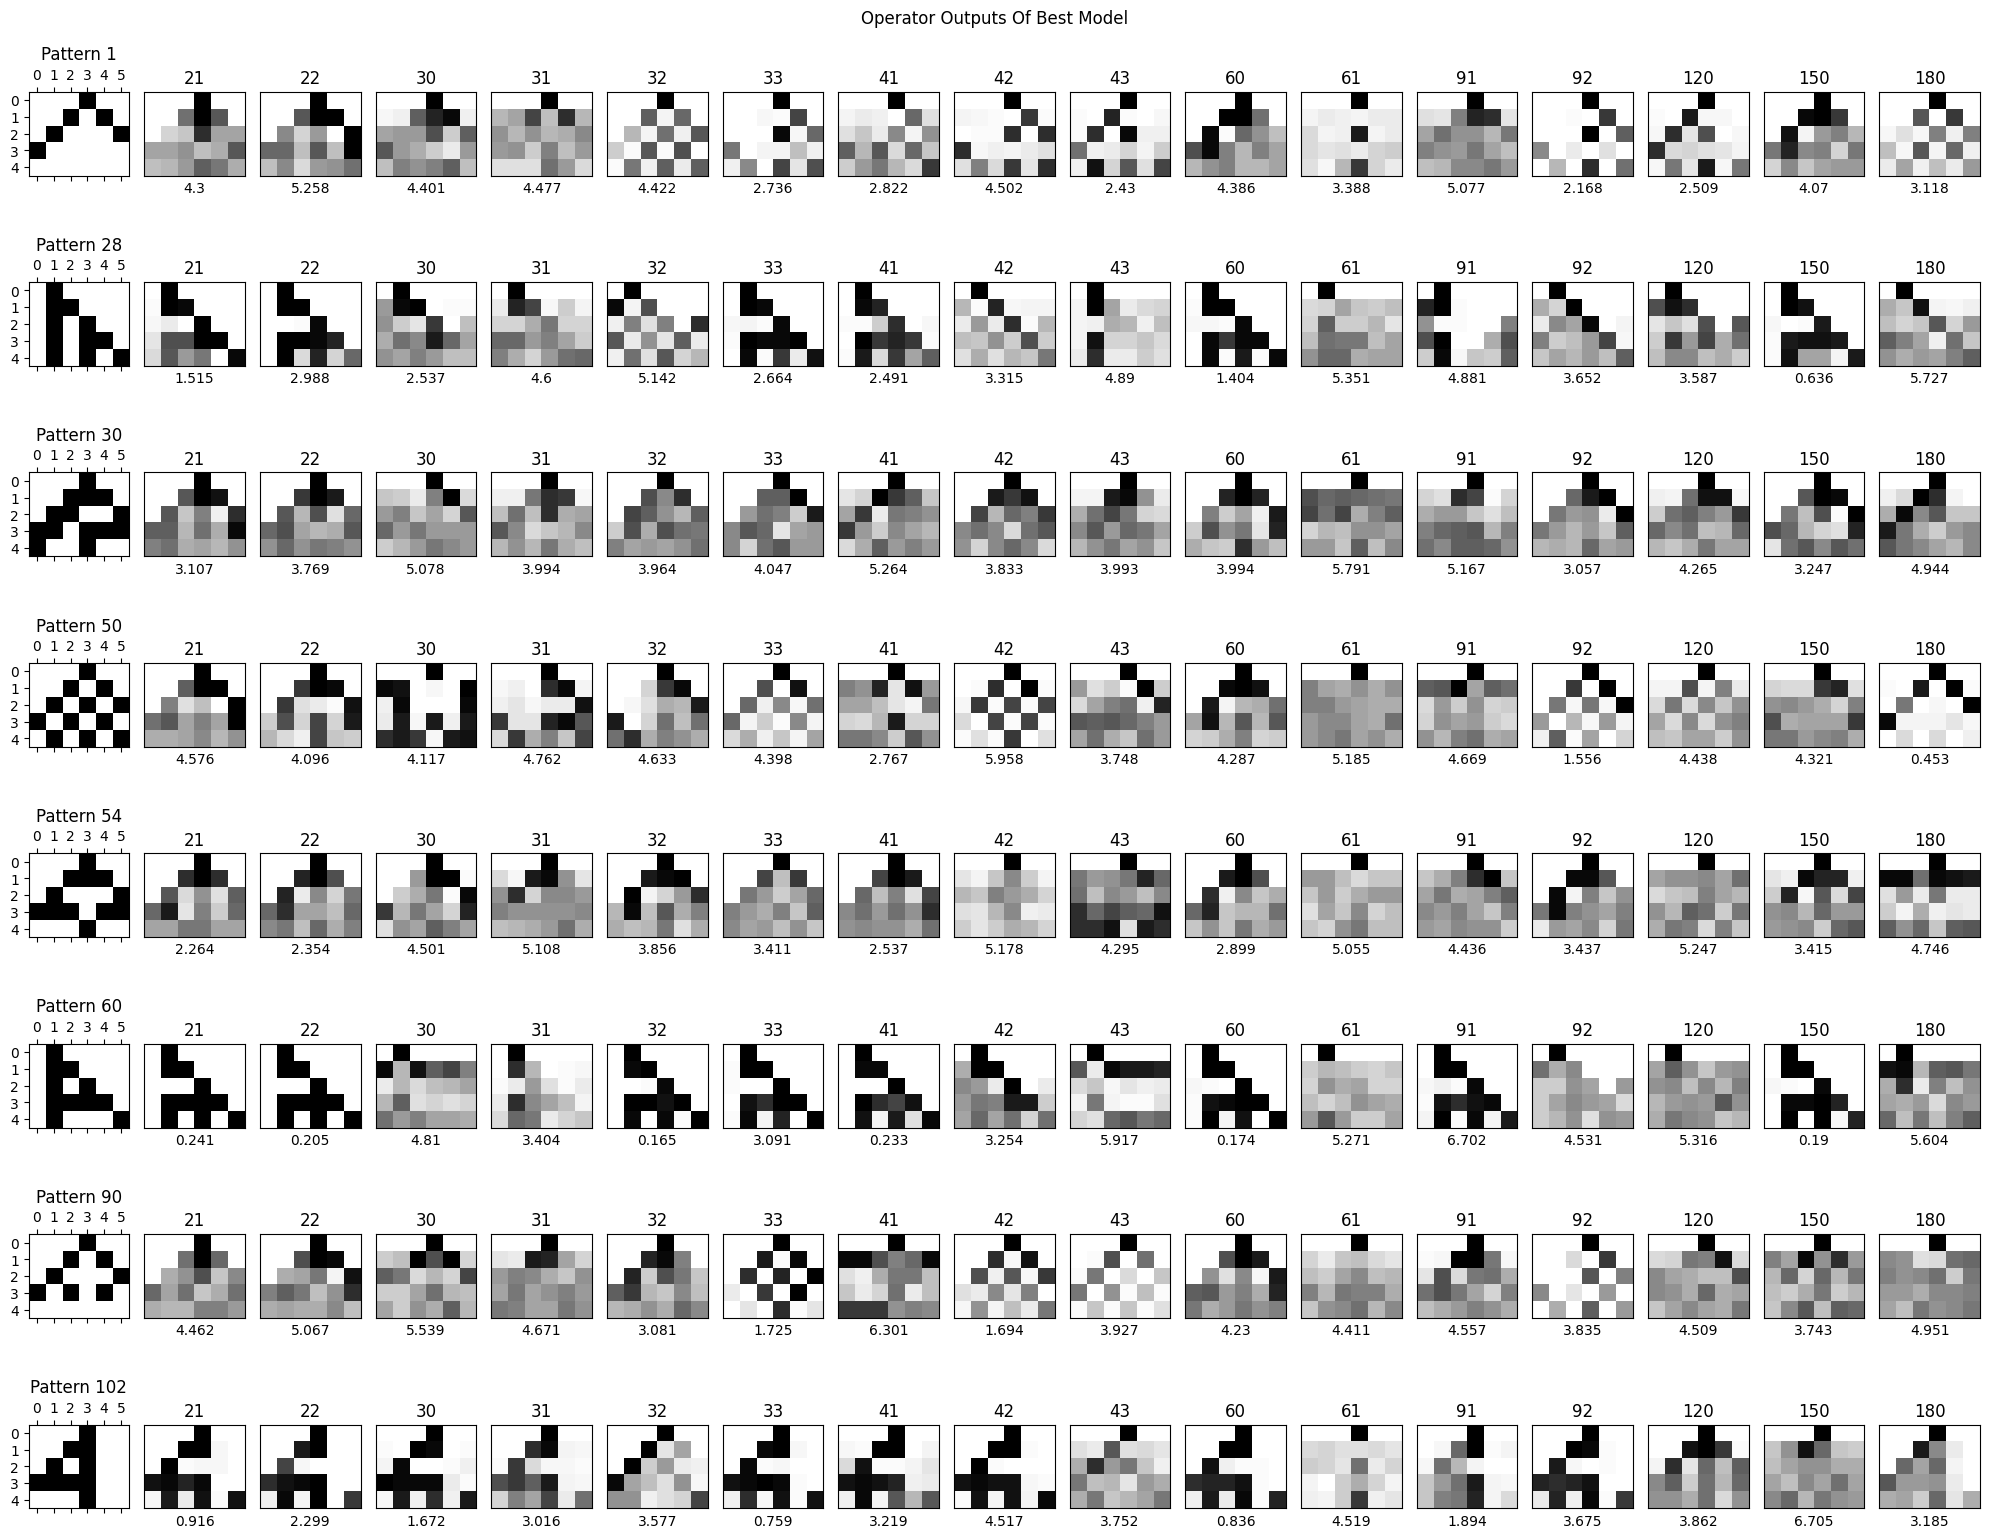

In [22]:
experiments.plot_outputs(finetunning=True)

# GA Results

## Reversible

#### Ideal

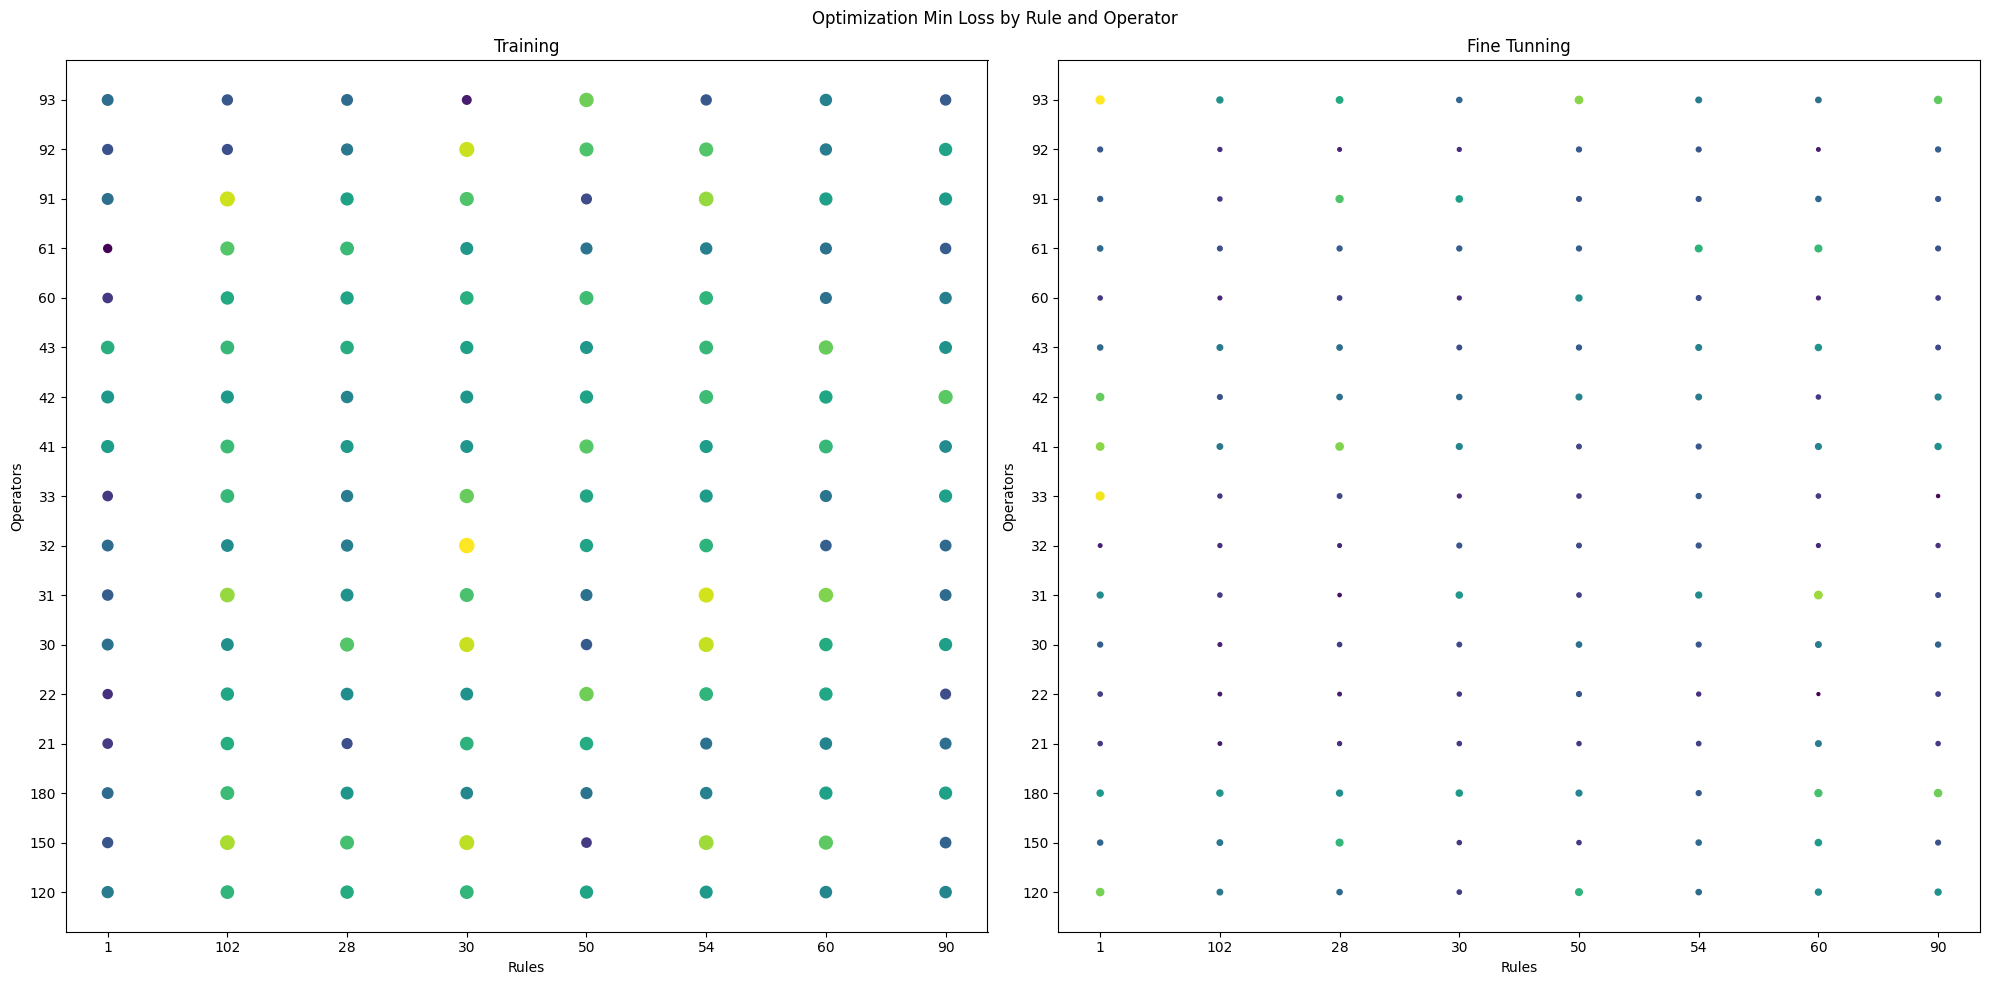

In [23]:
experiments = base.VQCAGlobalOptimizer(ca_patterns.rules, ga.VQCAOptimizerGA, path = DIRETORIO_PADRAO)
experiments.plot_results()

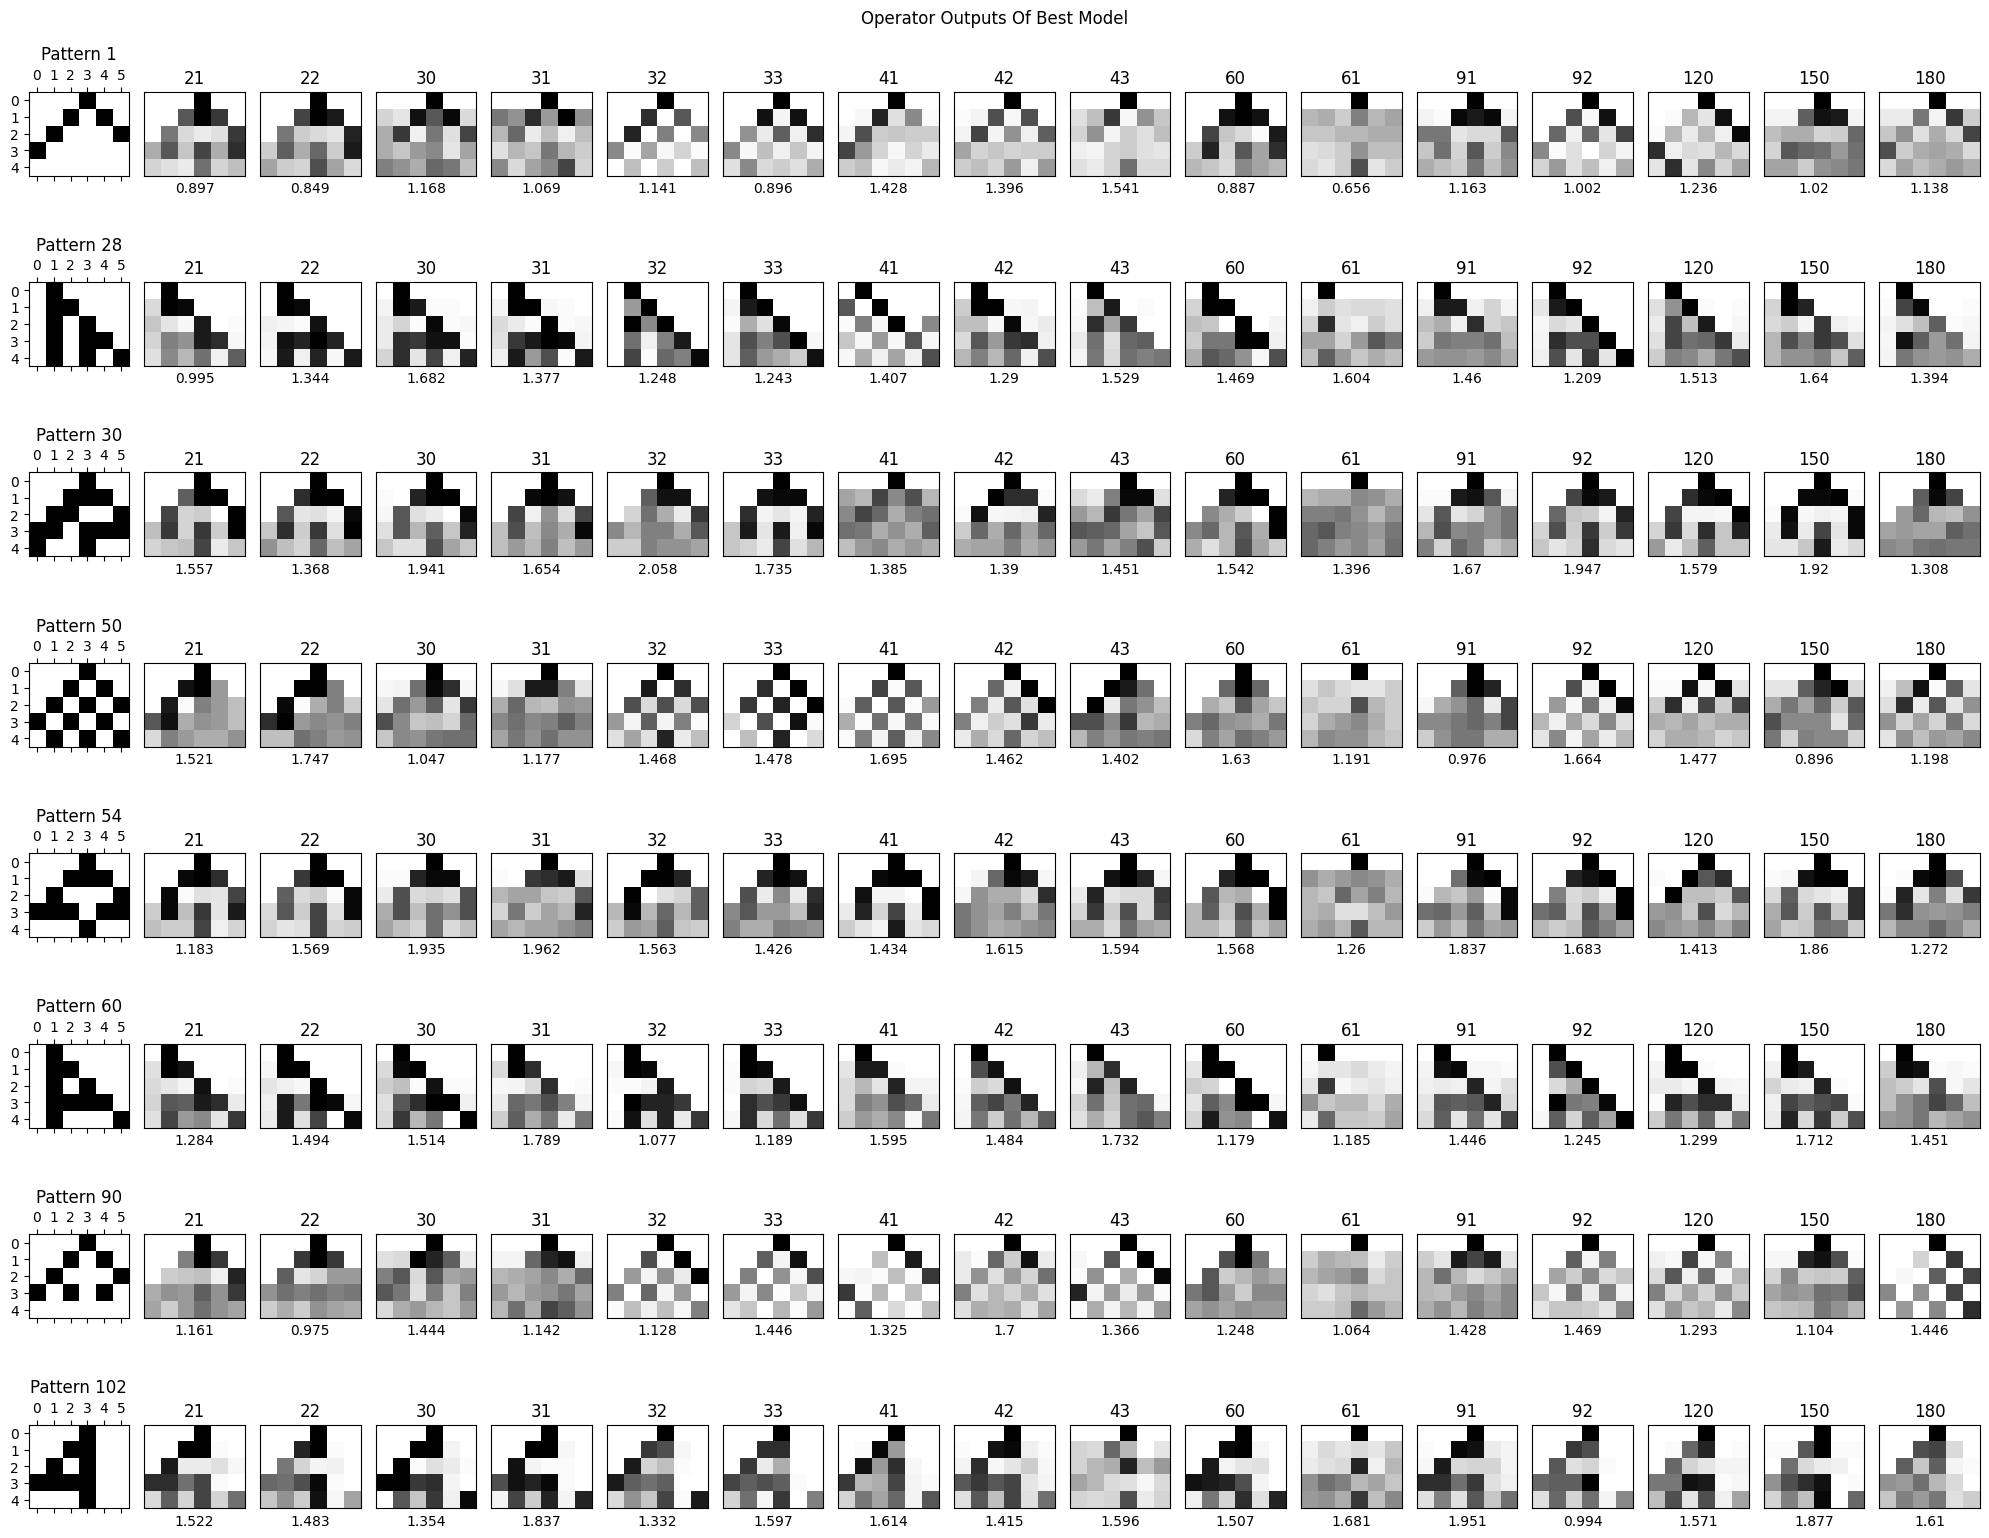

In [24]:
experiments.plot_outputs()

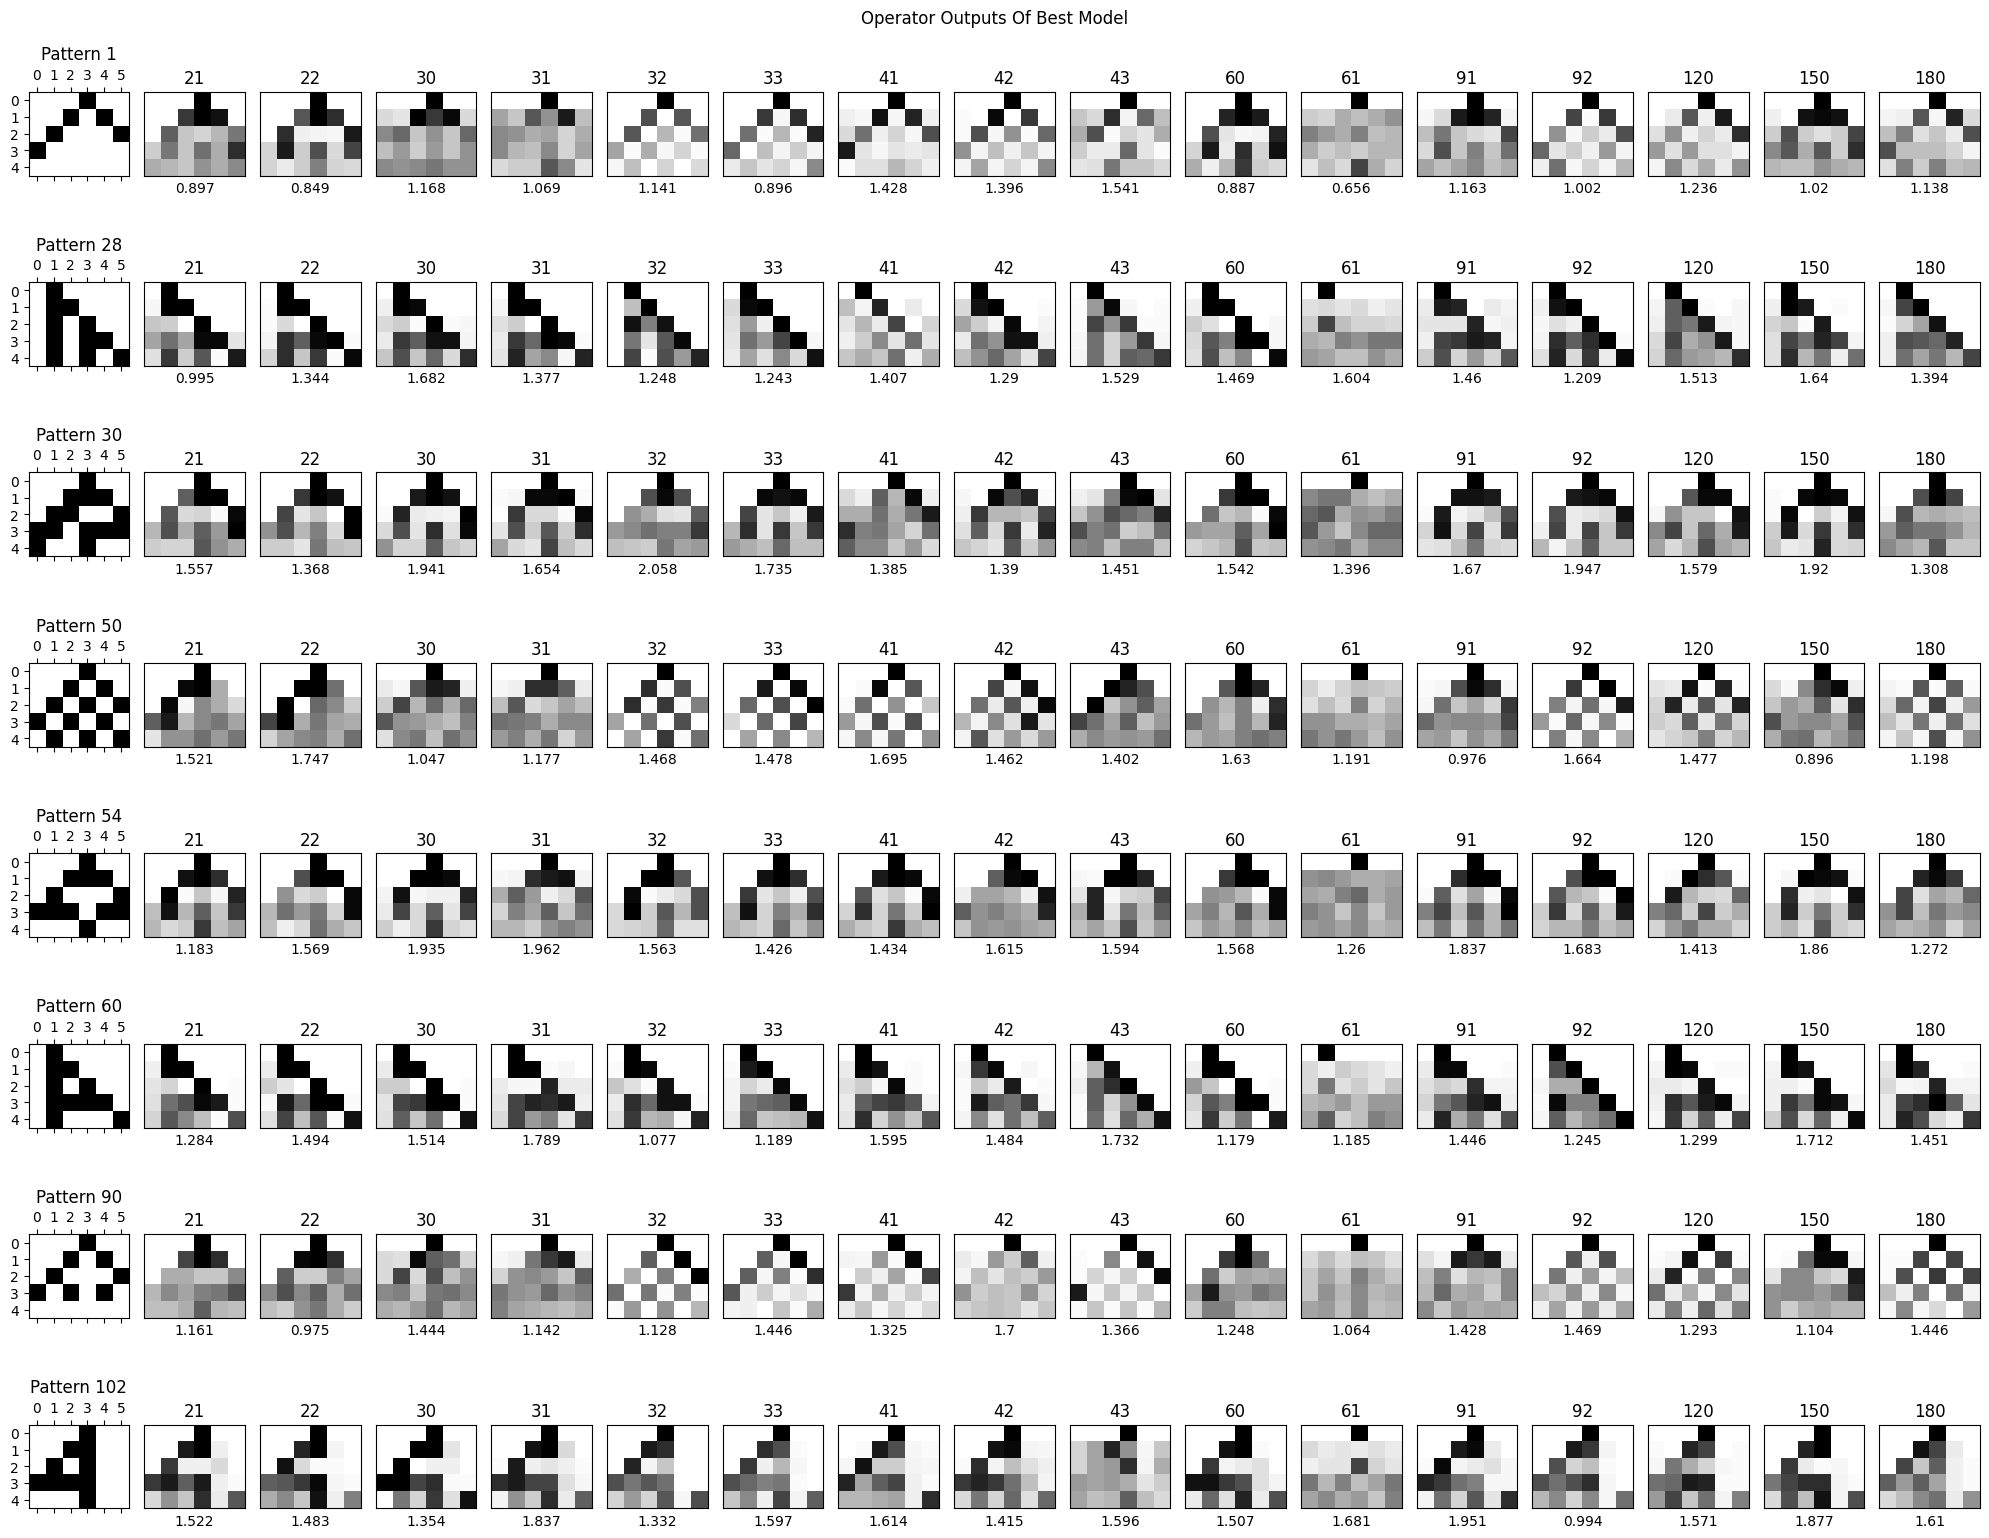

In [25]:
experiments.plot_outputs(finetunning=True)

#### Noisy

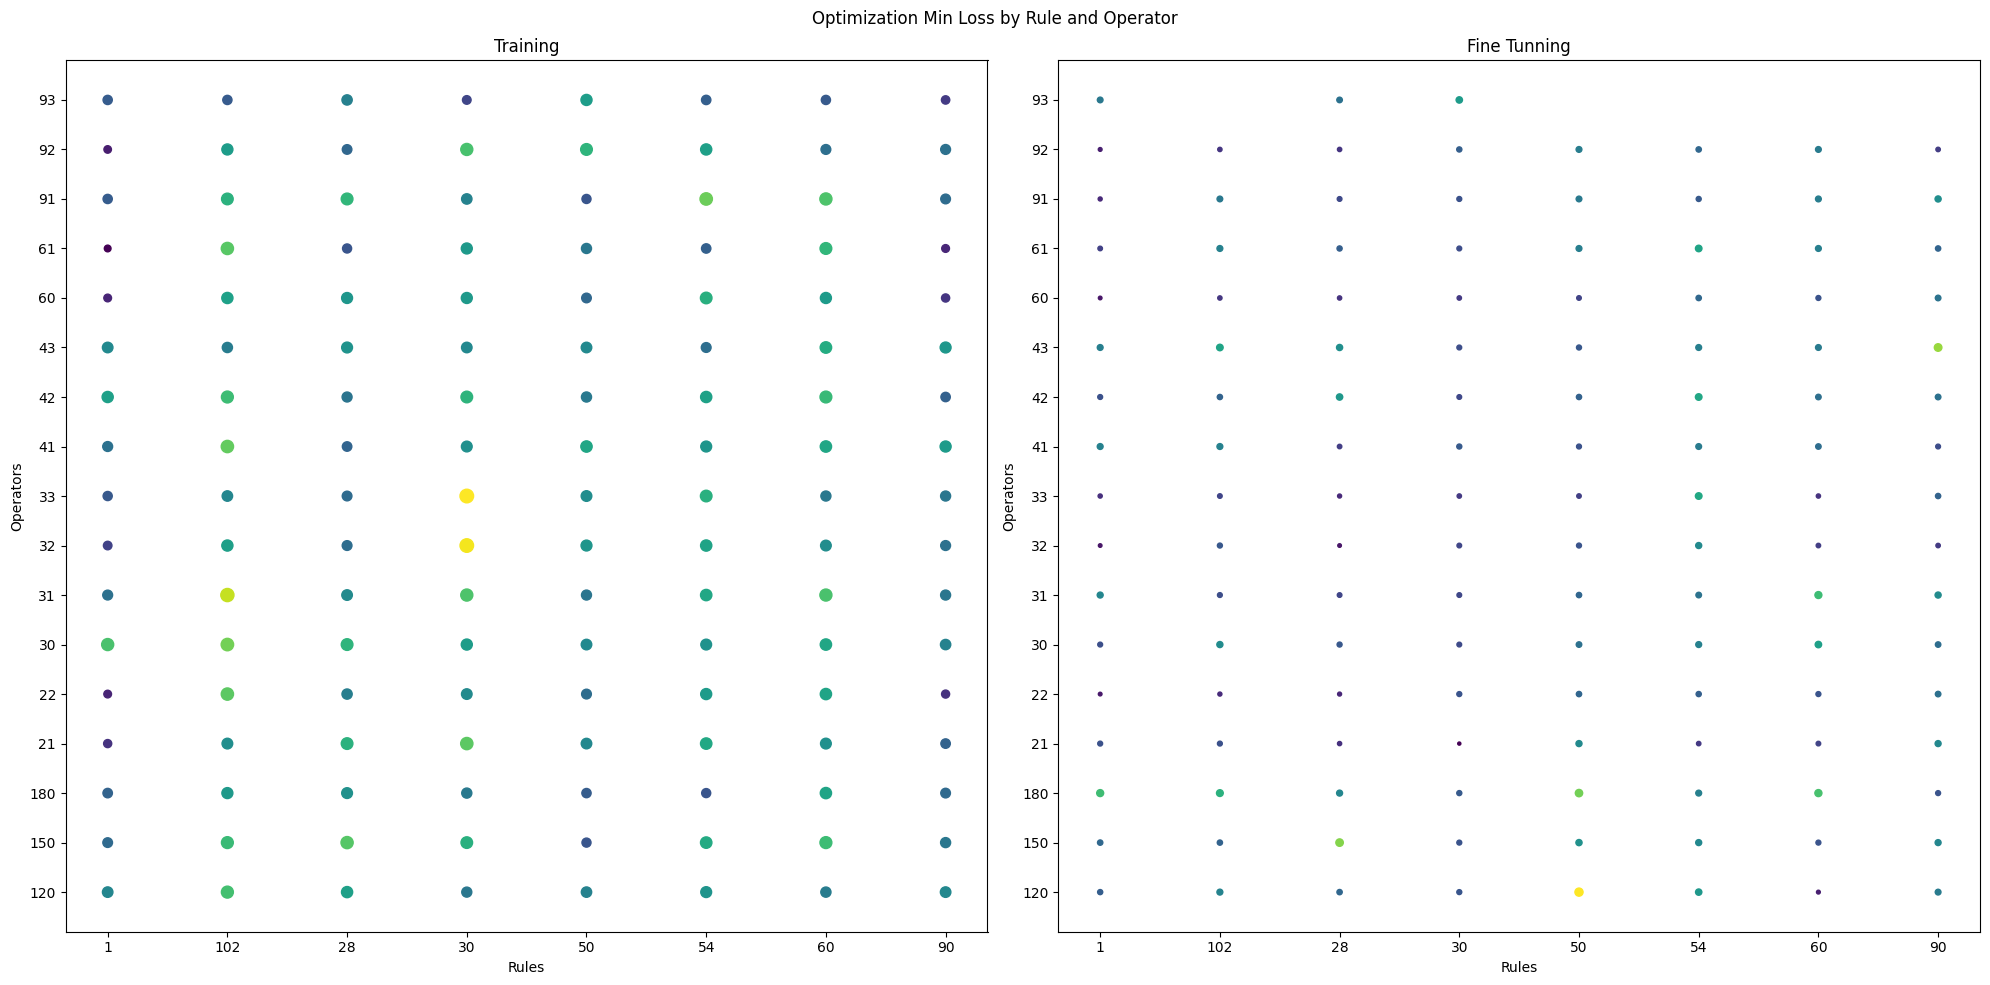

In [26]:
experiments = base.VQCAGlobalOptimizer(ca_patterns.rules, ga.VQCAOptimizerGA, path = DIRETORIO_PADRAO, noise = True)
experiments.plot_results()

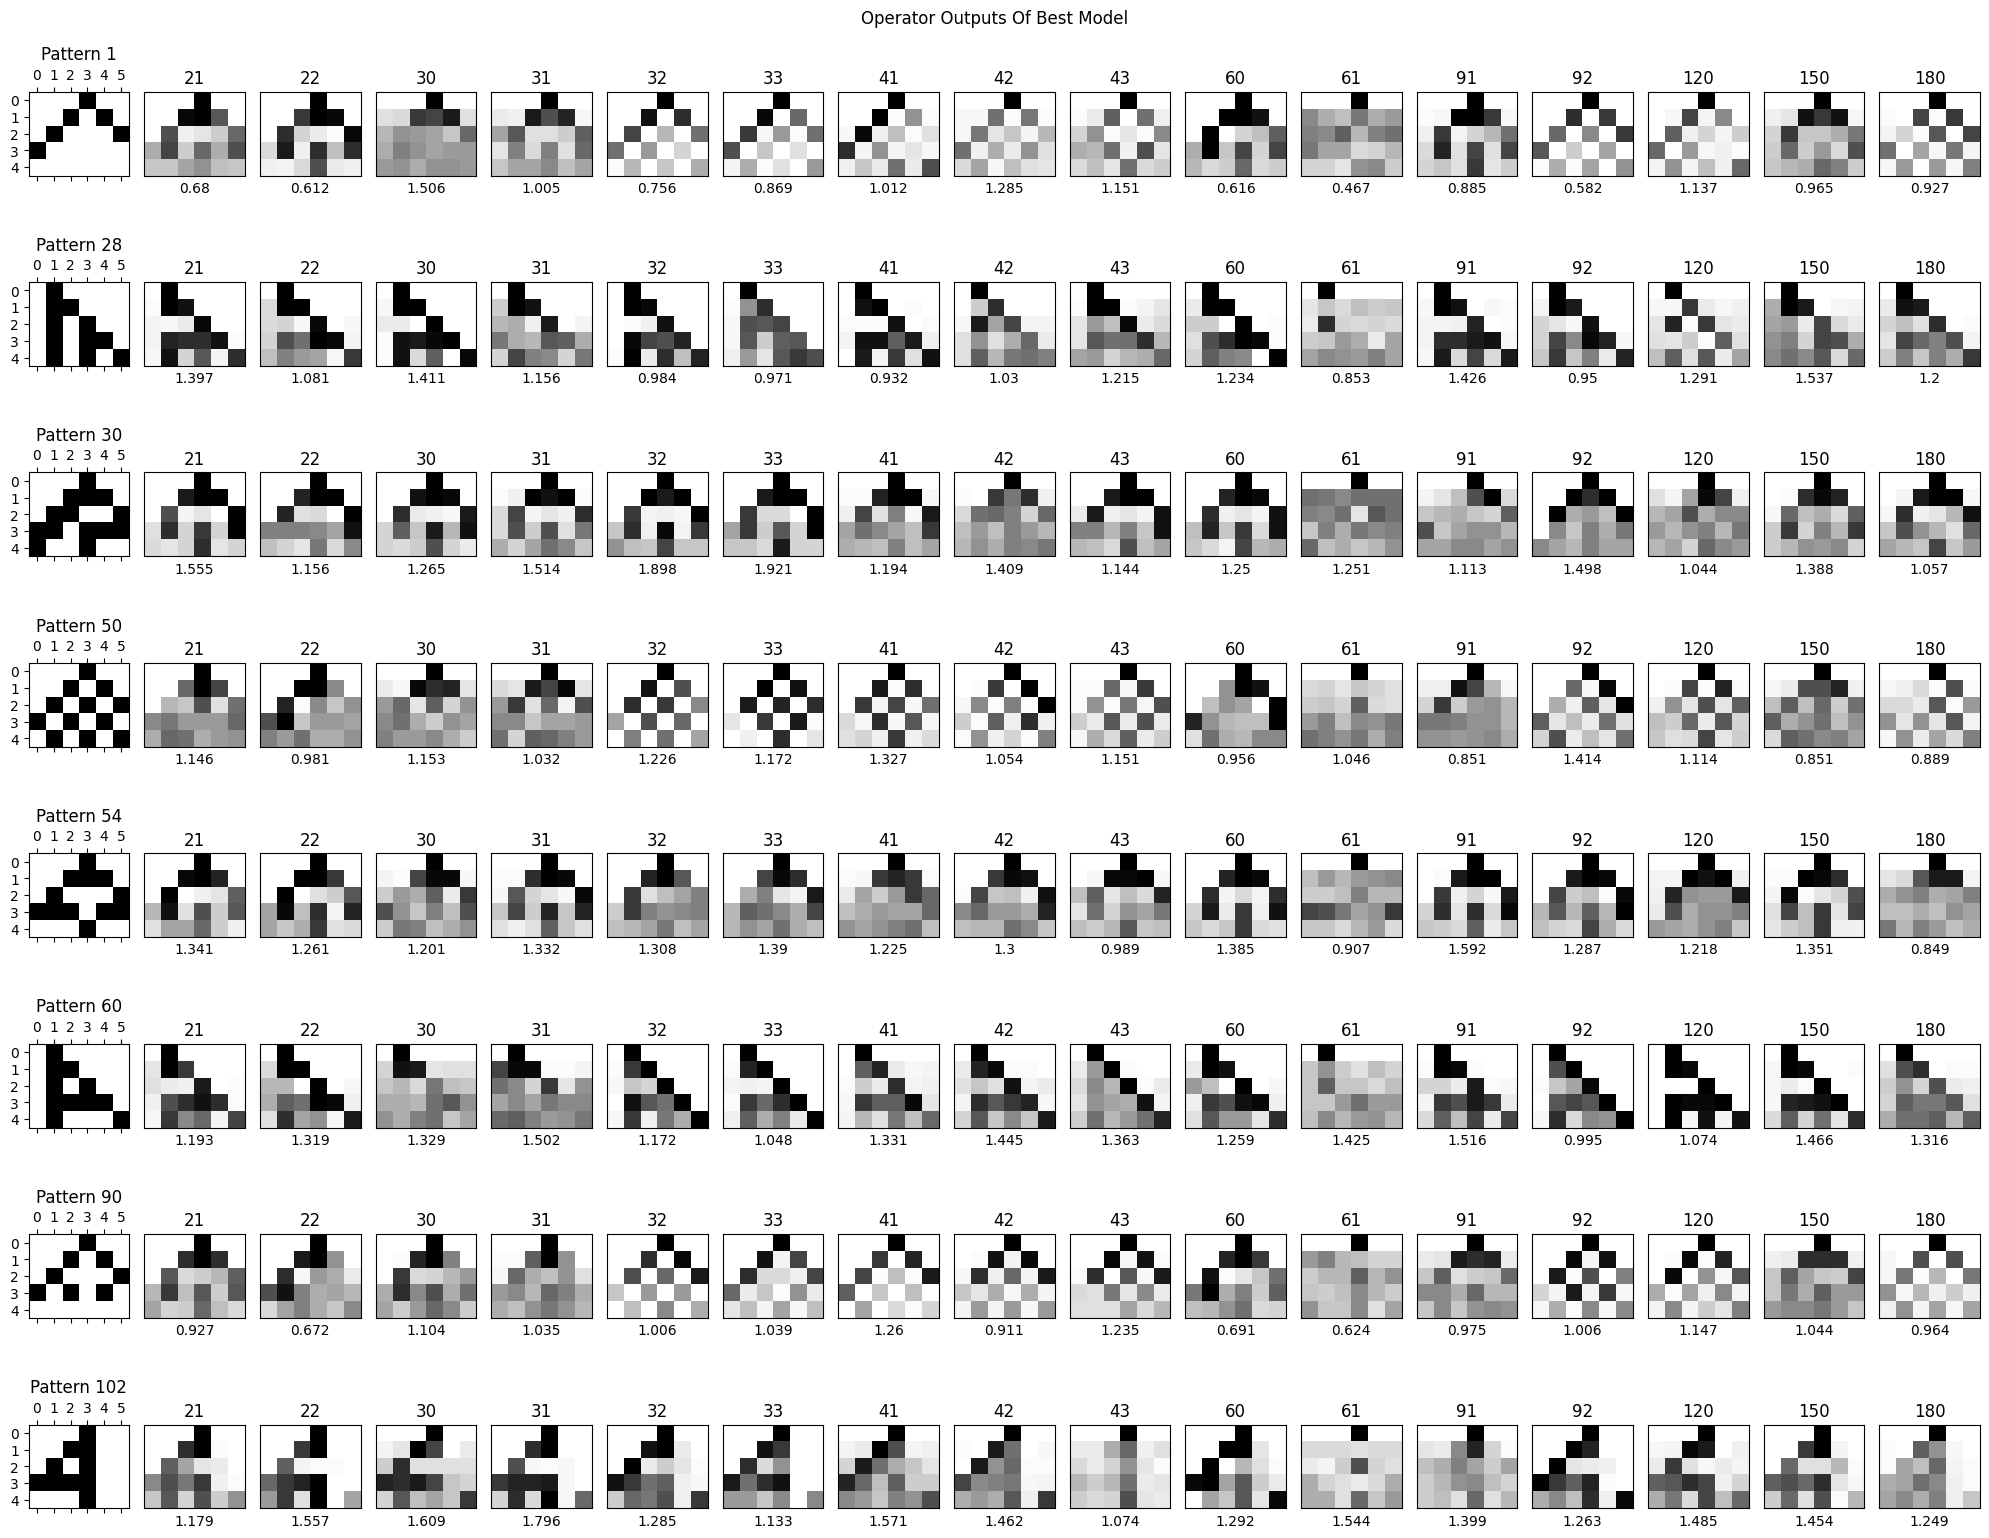

In [27]:
experiments.plot_outputs()

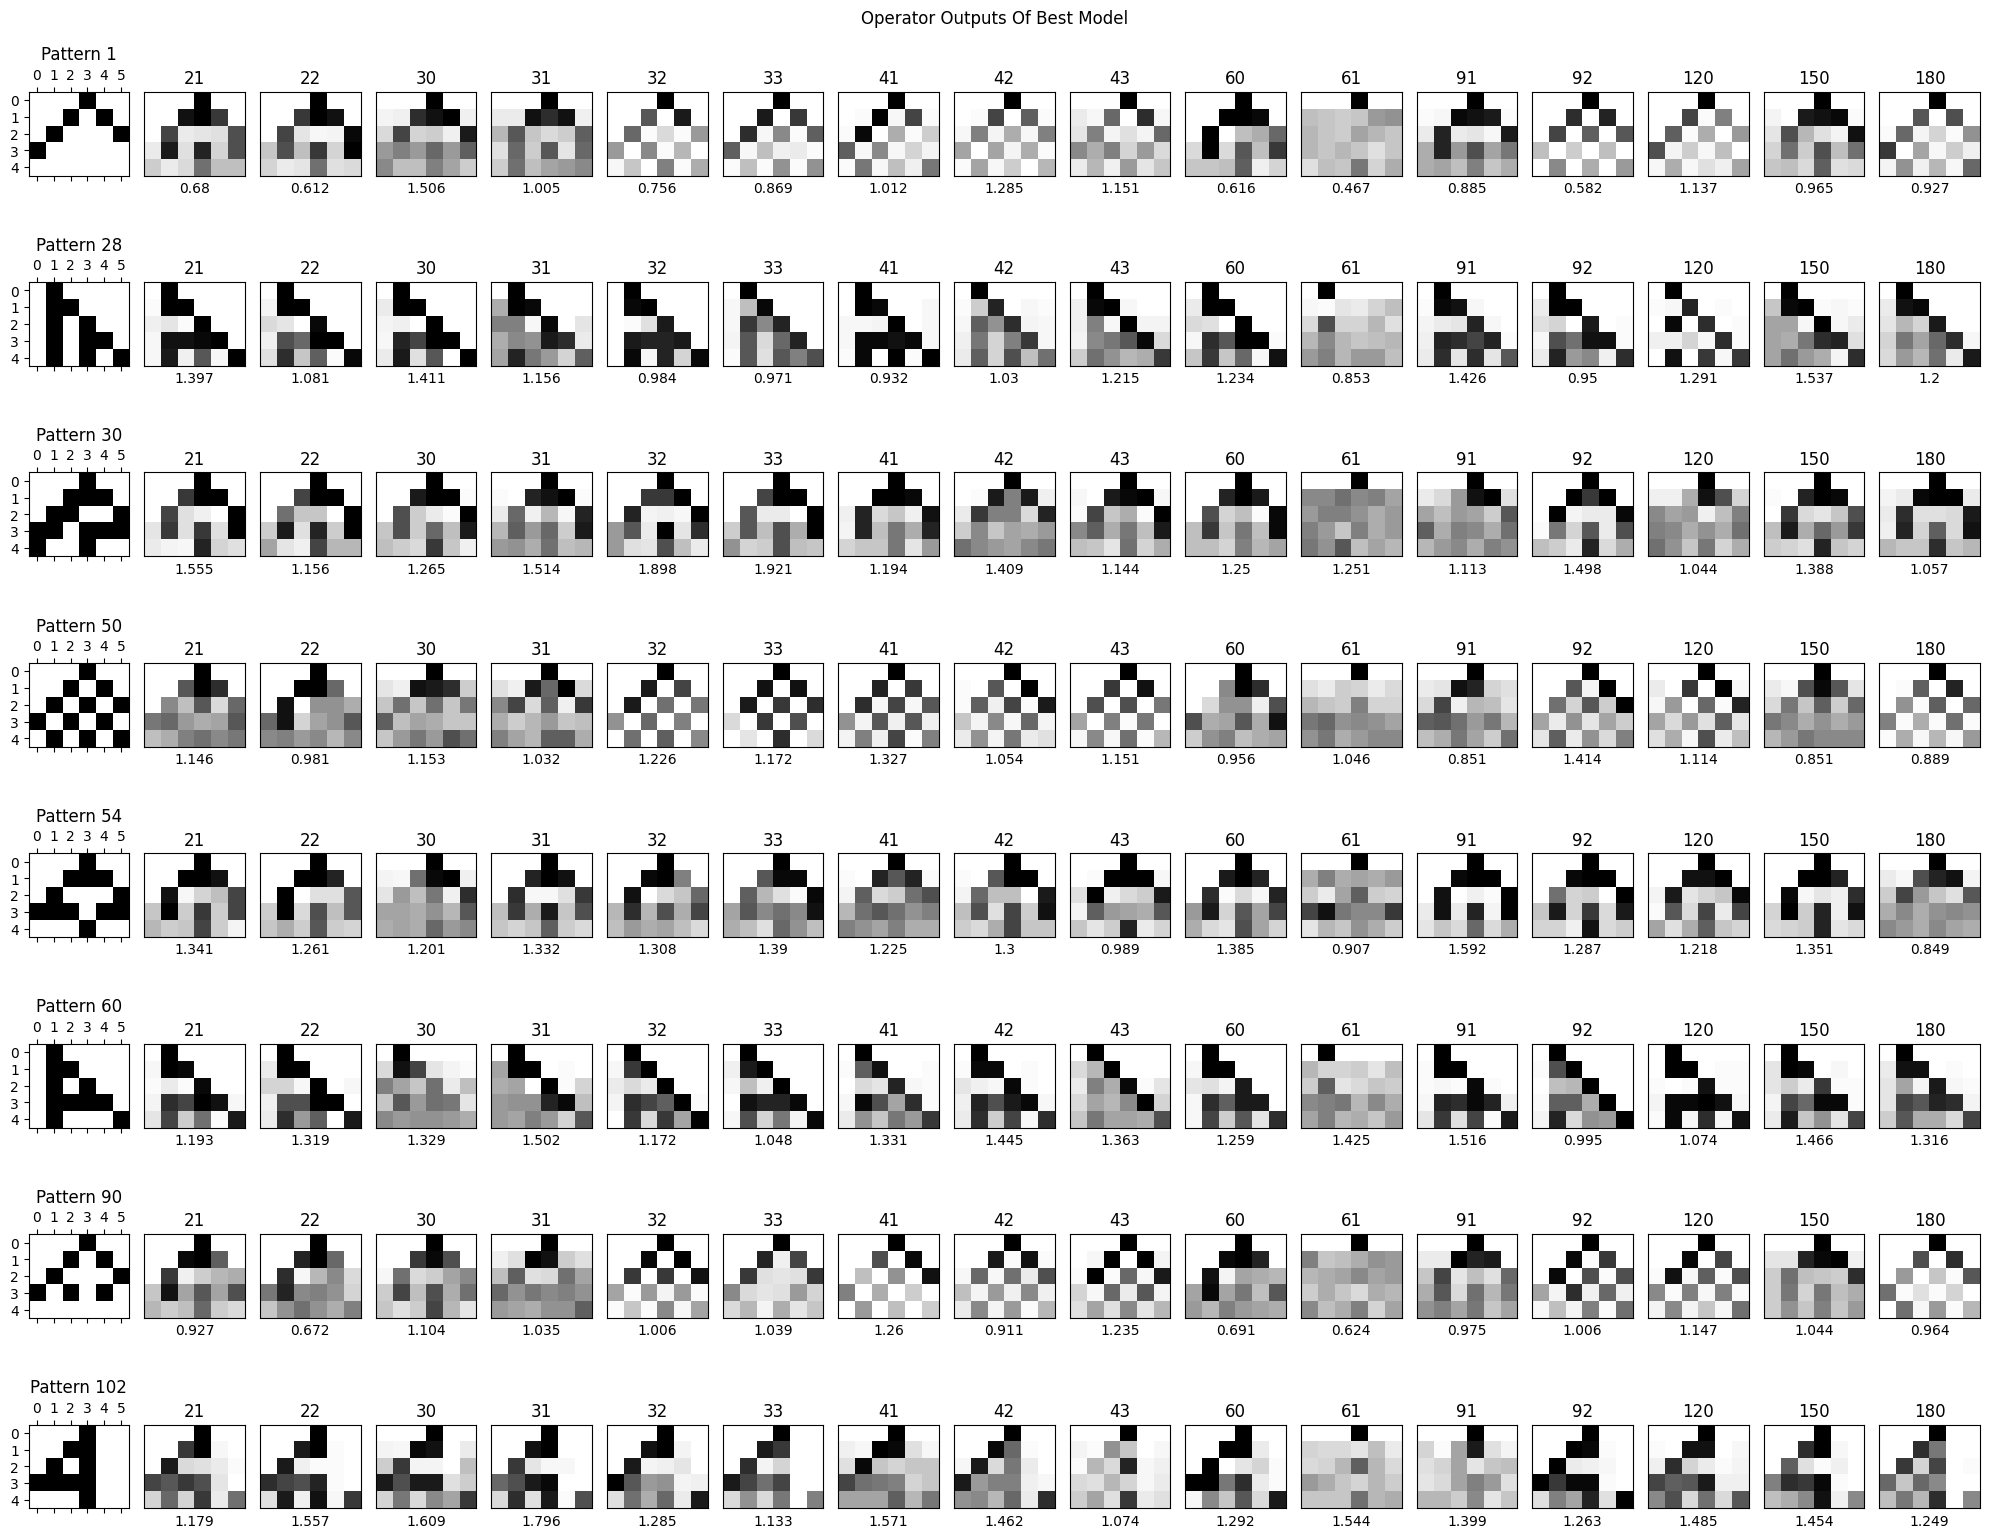

In [28]:
experiments.plot_outputs(finetunning=True)

## Irreversible (With Reset)

#### Ideal

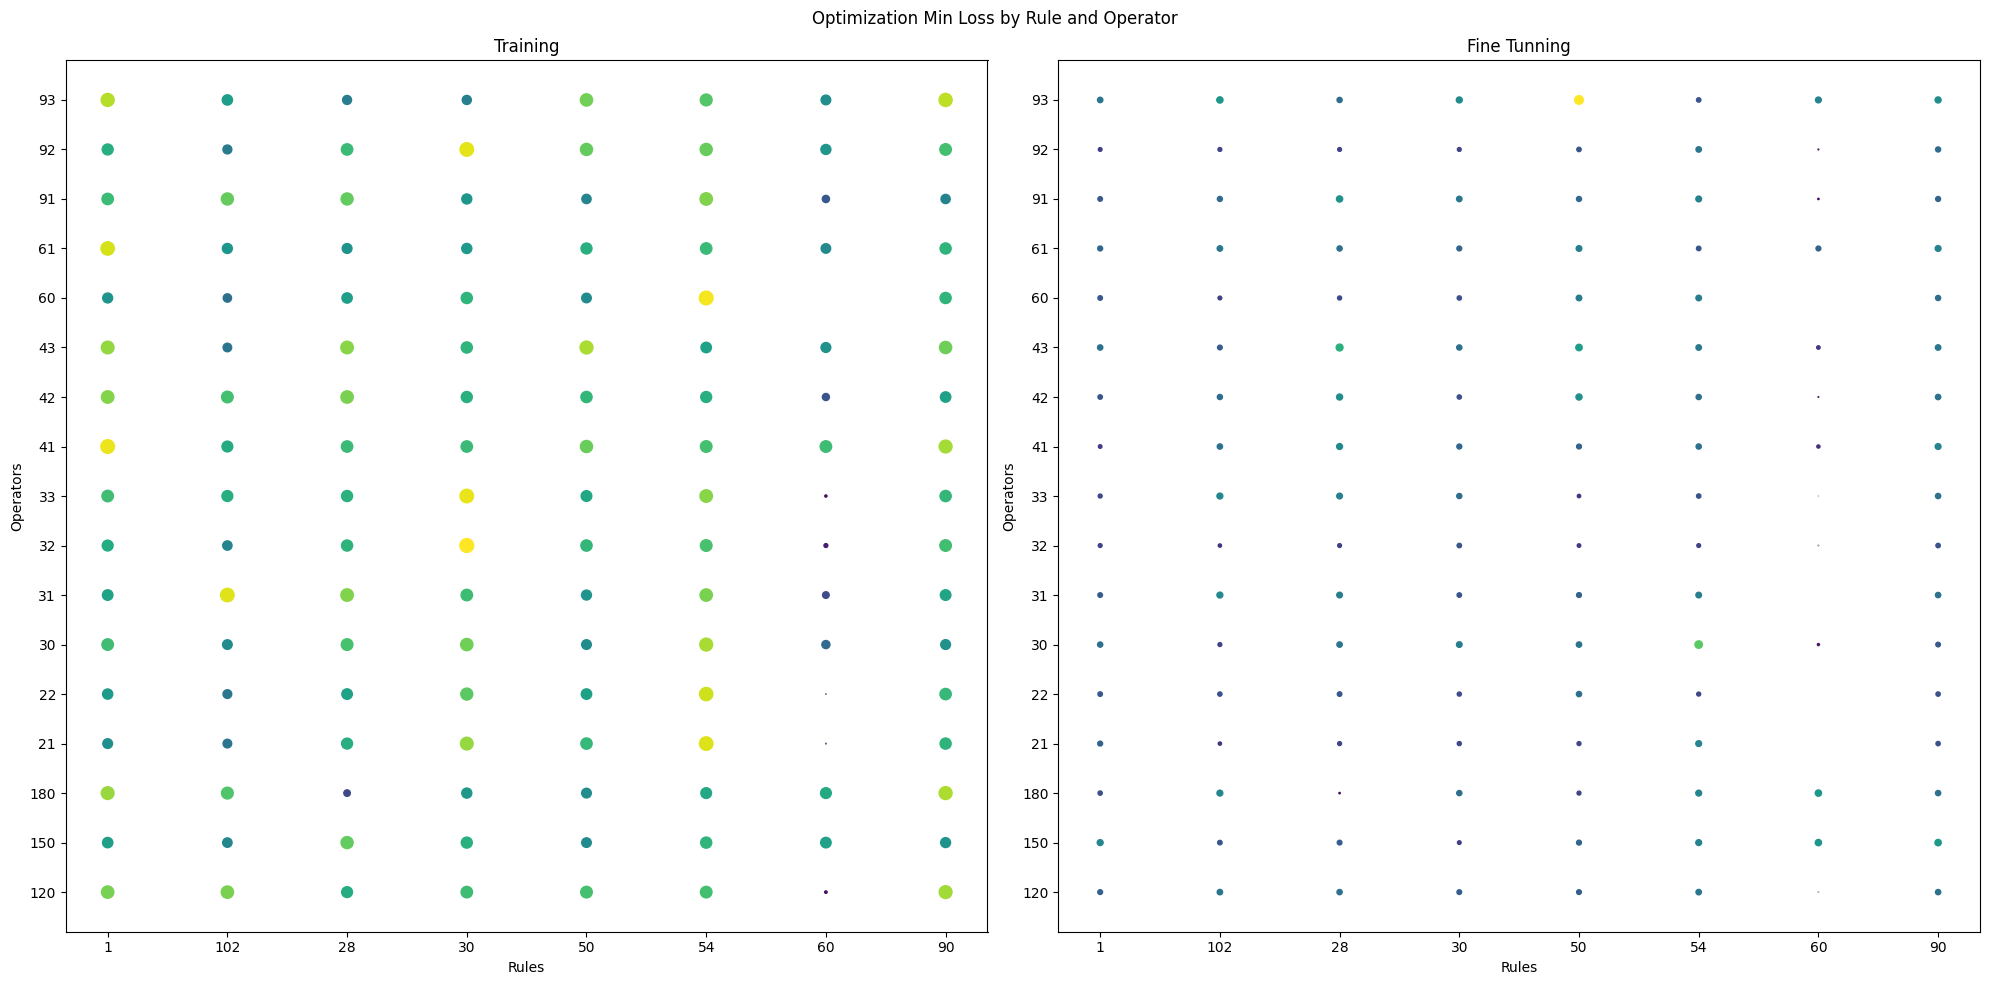

In [29]:
experiments = base.VQCAGlobalOptimizer(ca_patterns.rules, ga.VQCAOptimizerGA, path = DIRETORIO_PADRAO, reset = True)
experiments.plot_results()

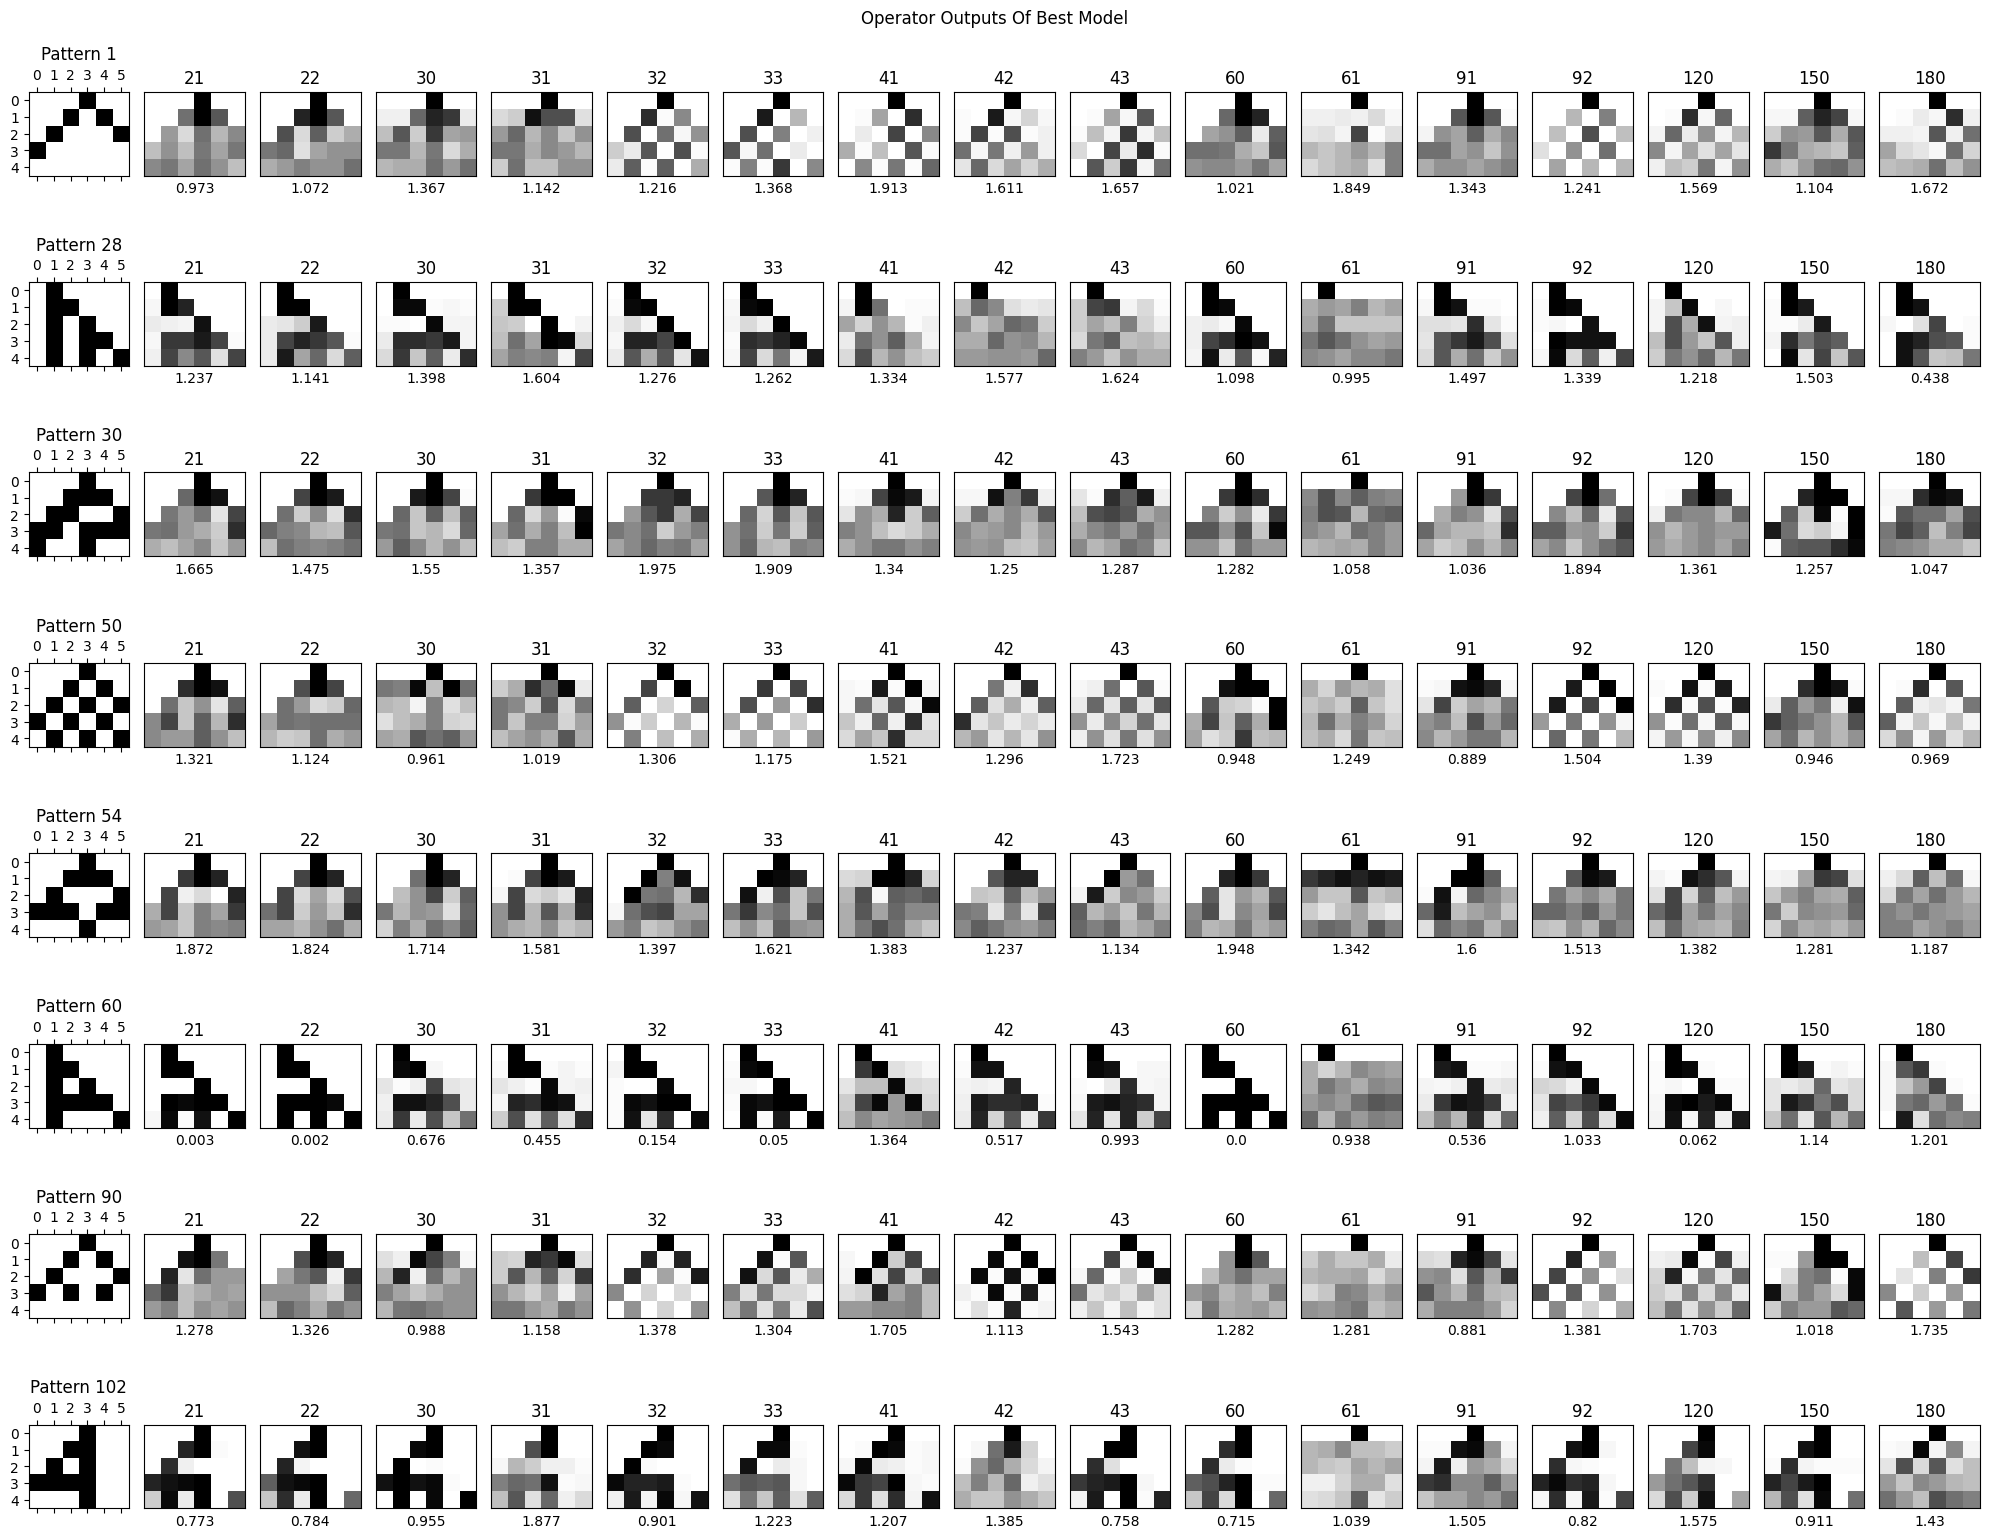

In [30]:
experiments.plot_outputs()

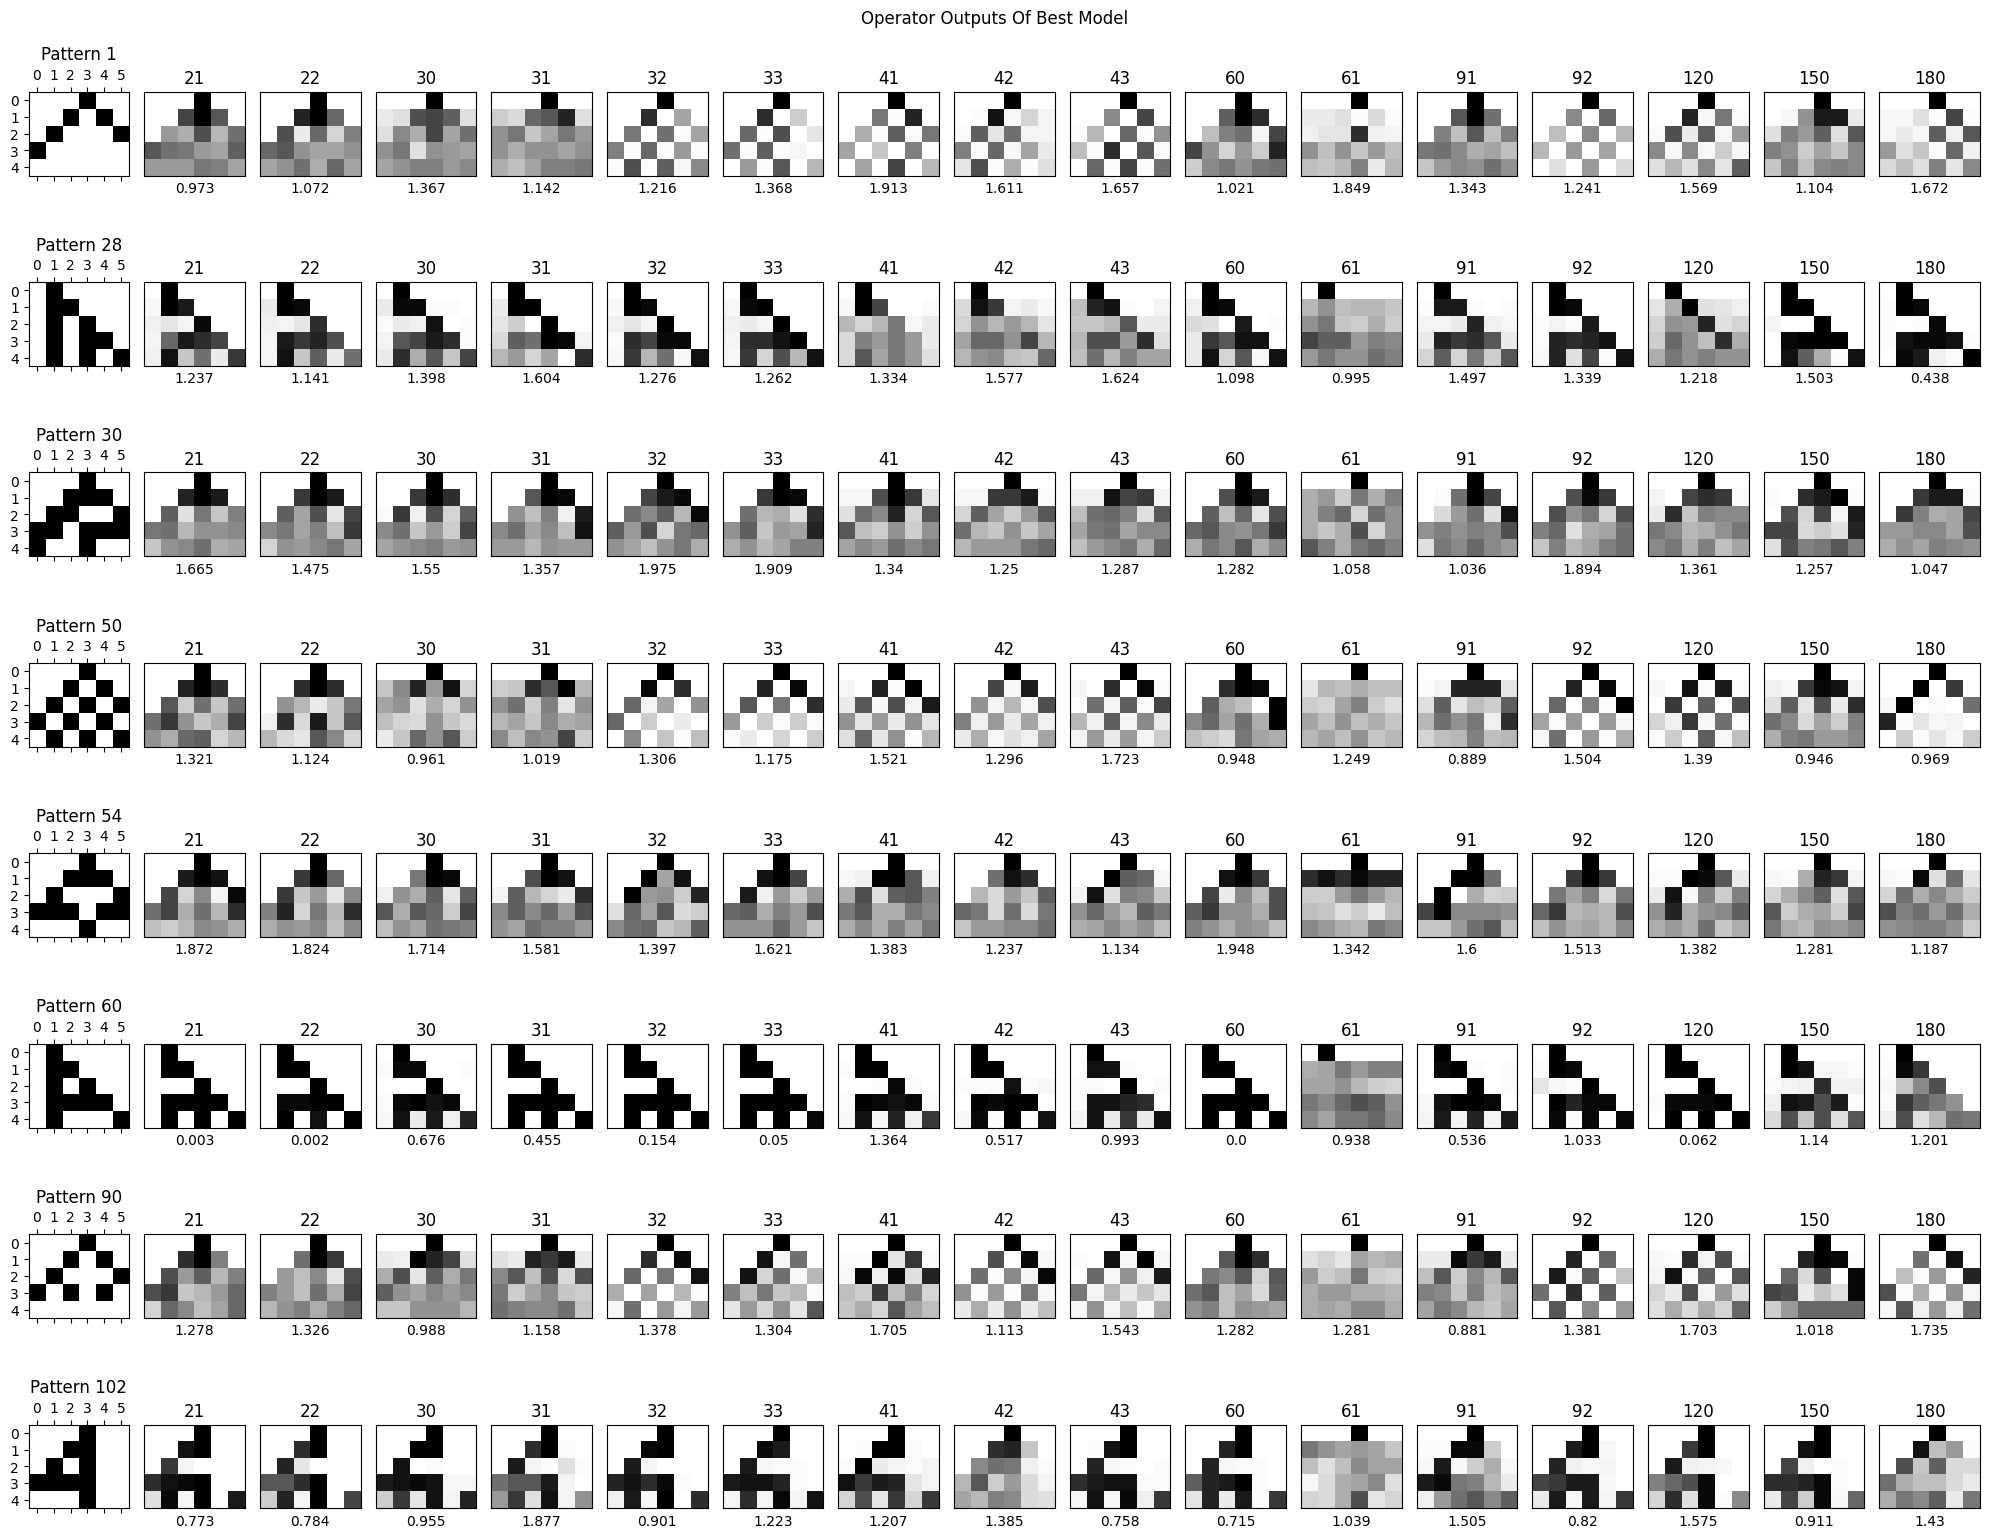

In [31]:
experiments.plot_outputs(finetunning=True)

#### Noisy

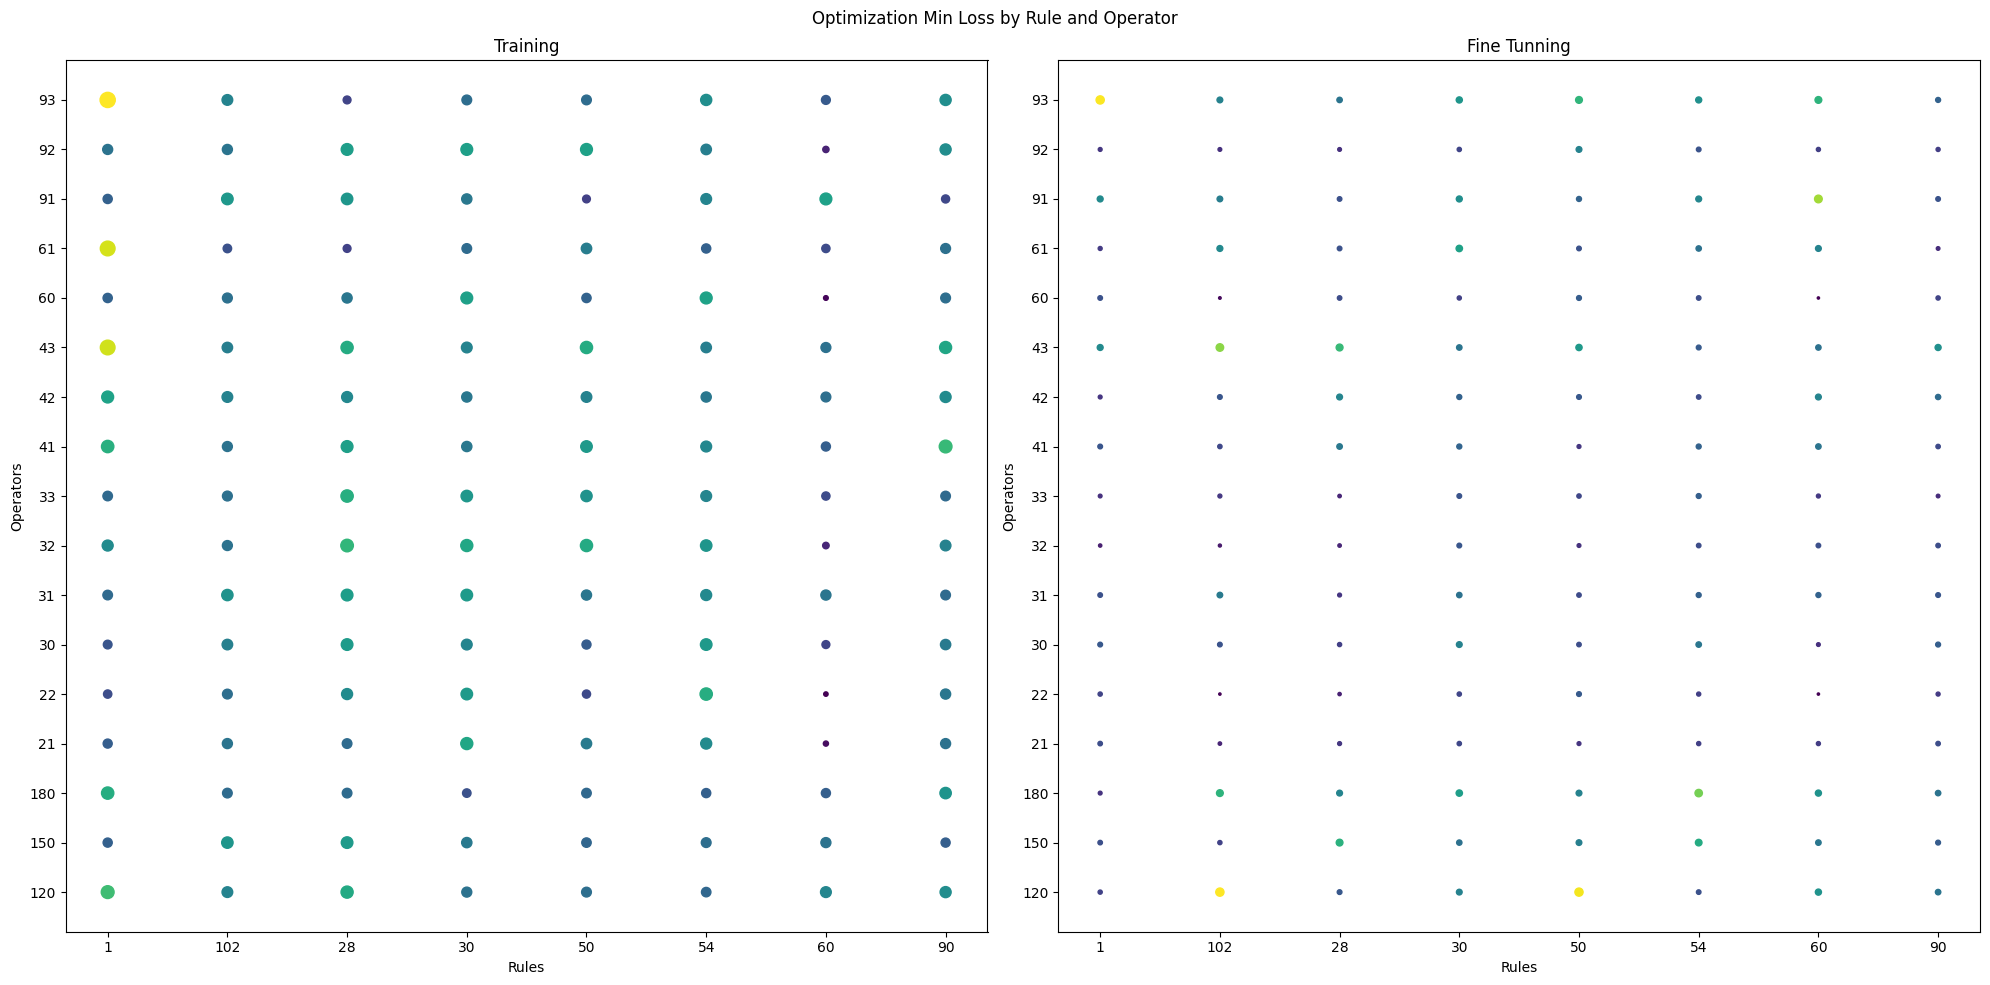

In [32]:
experiments = base.VQCAGlobalOptimizer(ca_patterns.rules, ga.VQCAOptimizerGA, path = DIRETORIO_PADRAO, reset = True, noise = True)
experiments.plot_results()

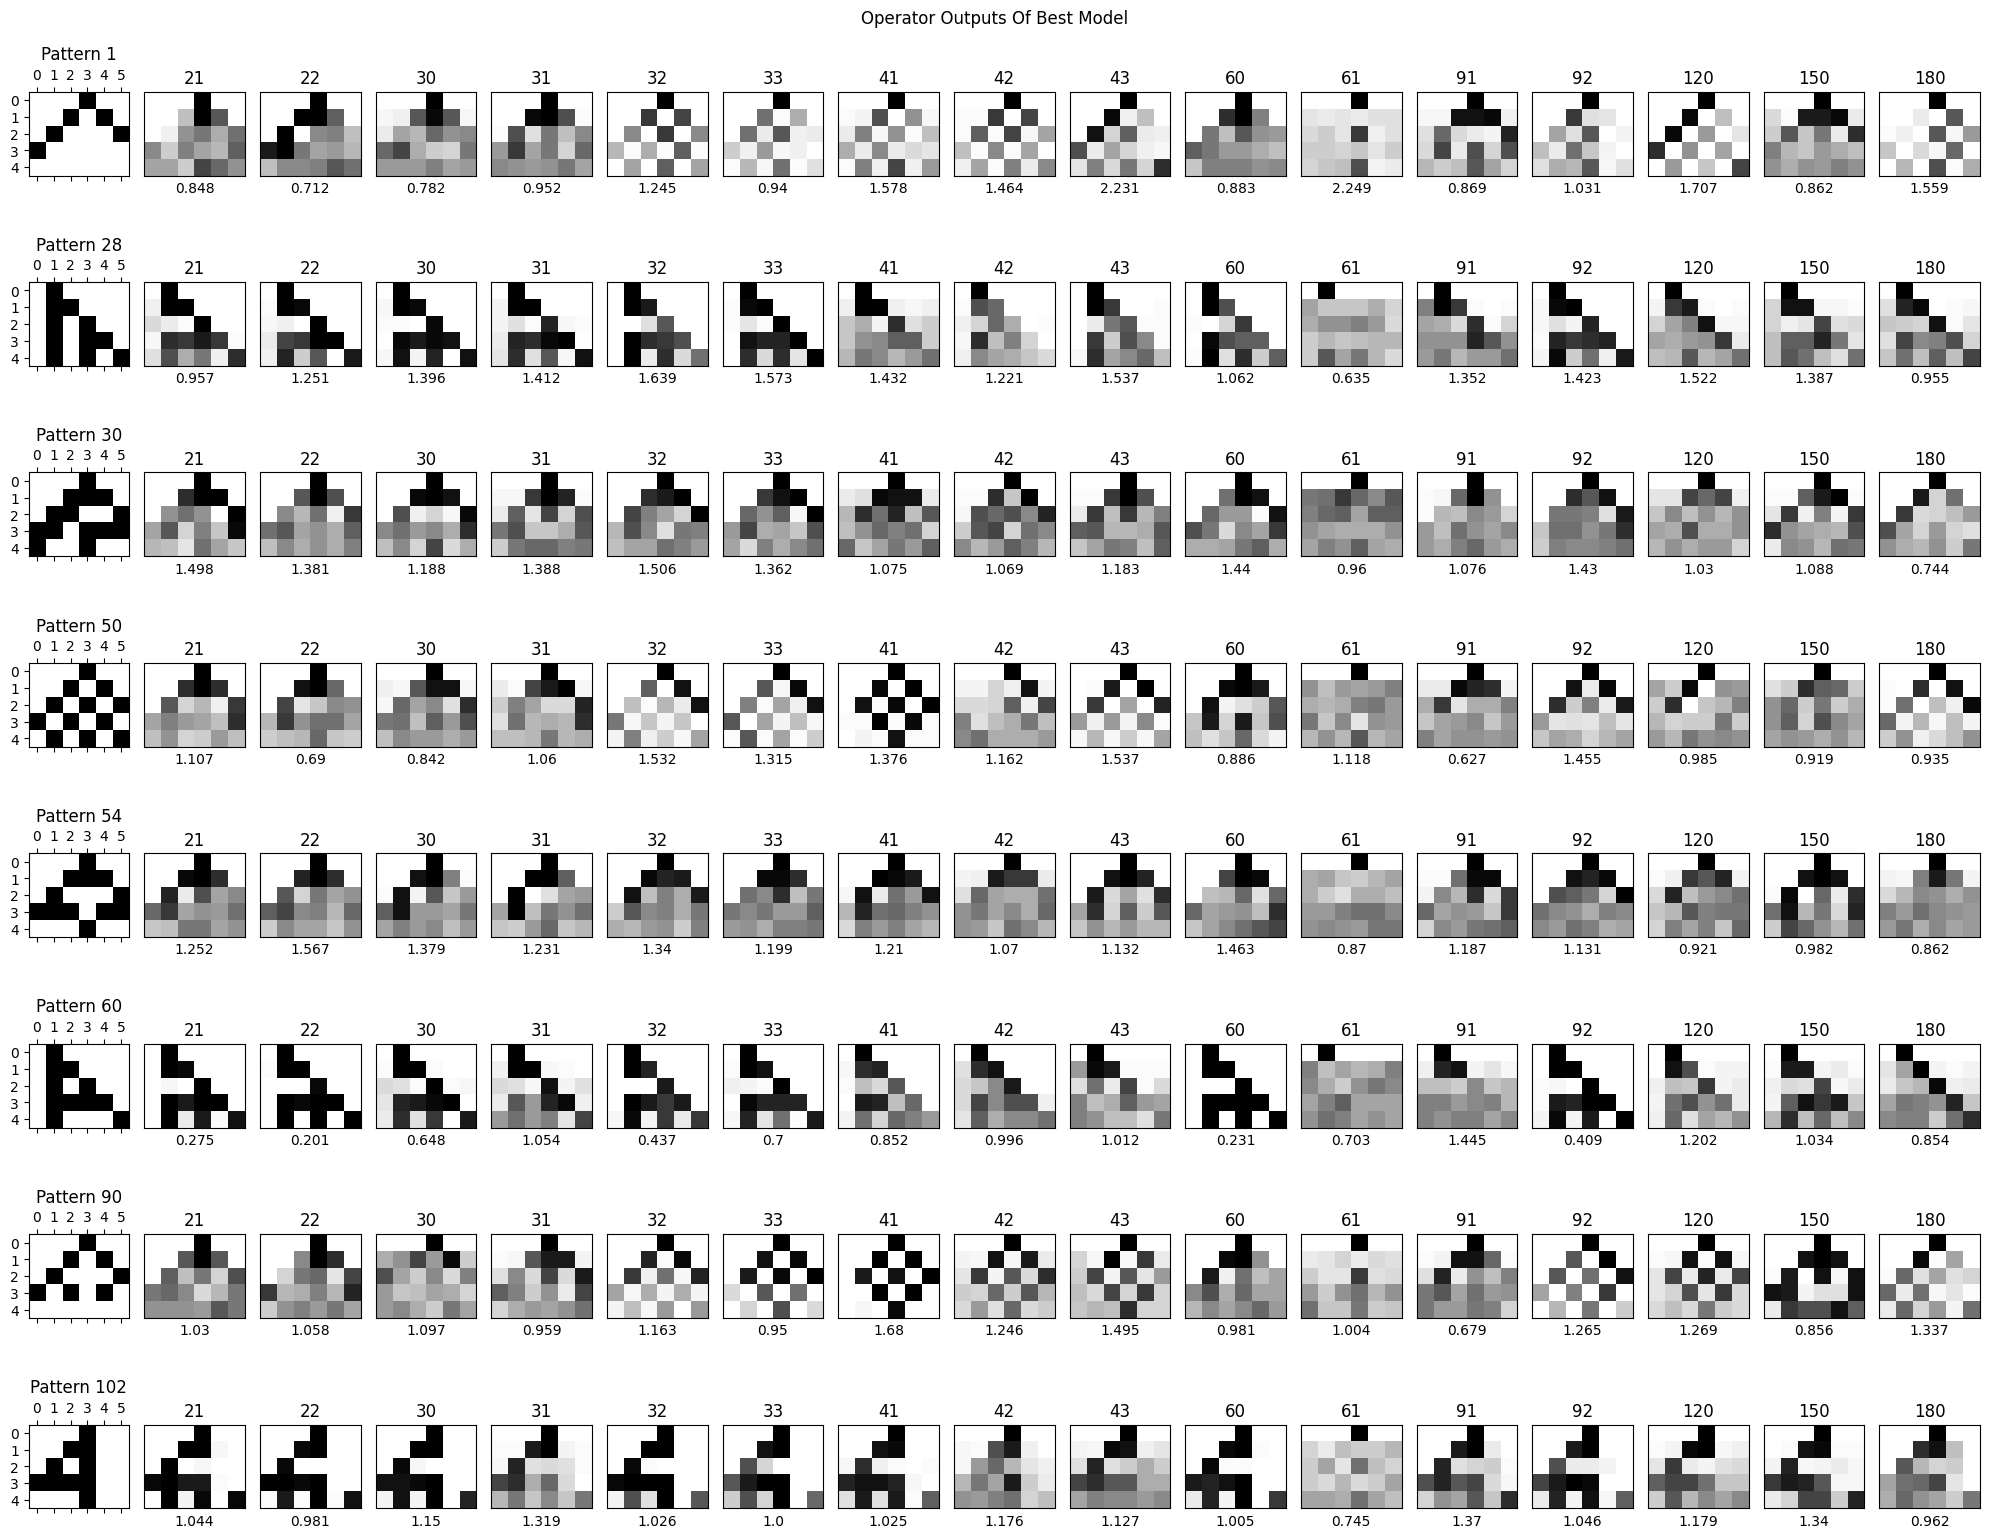

In [33]:
experiments.plot_outputs()

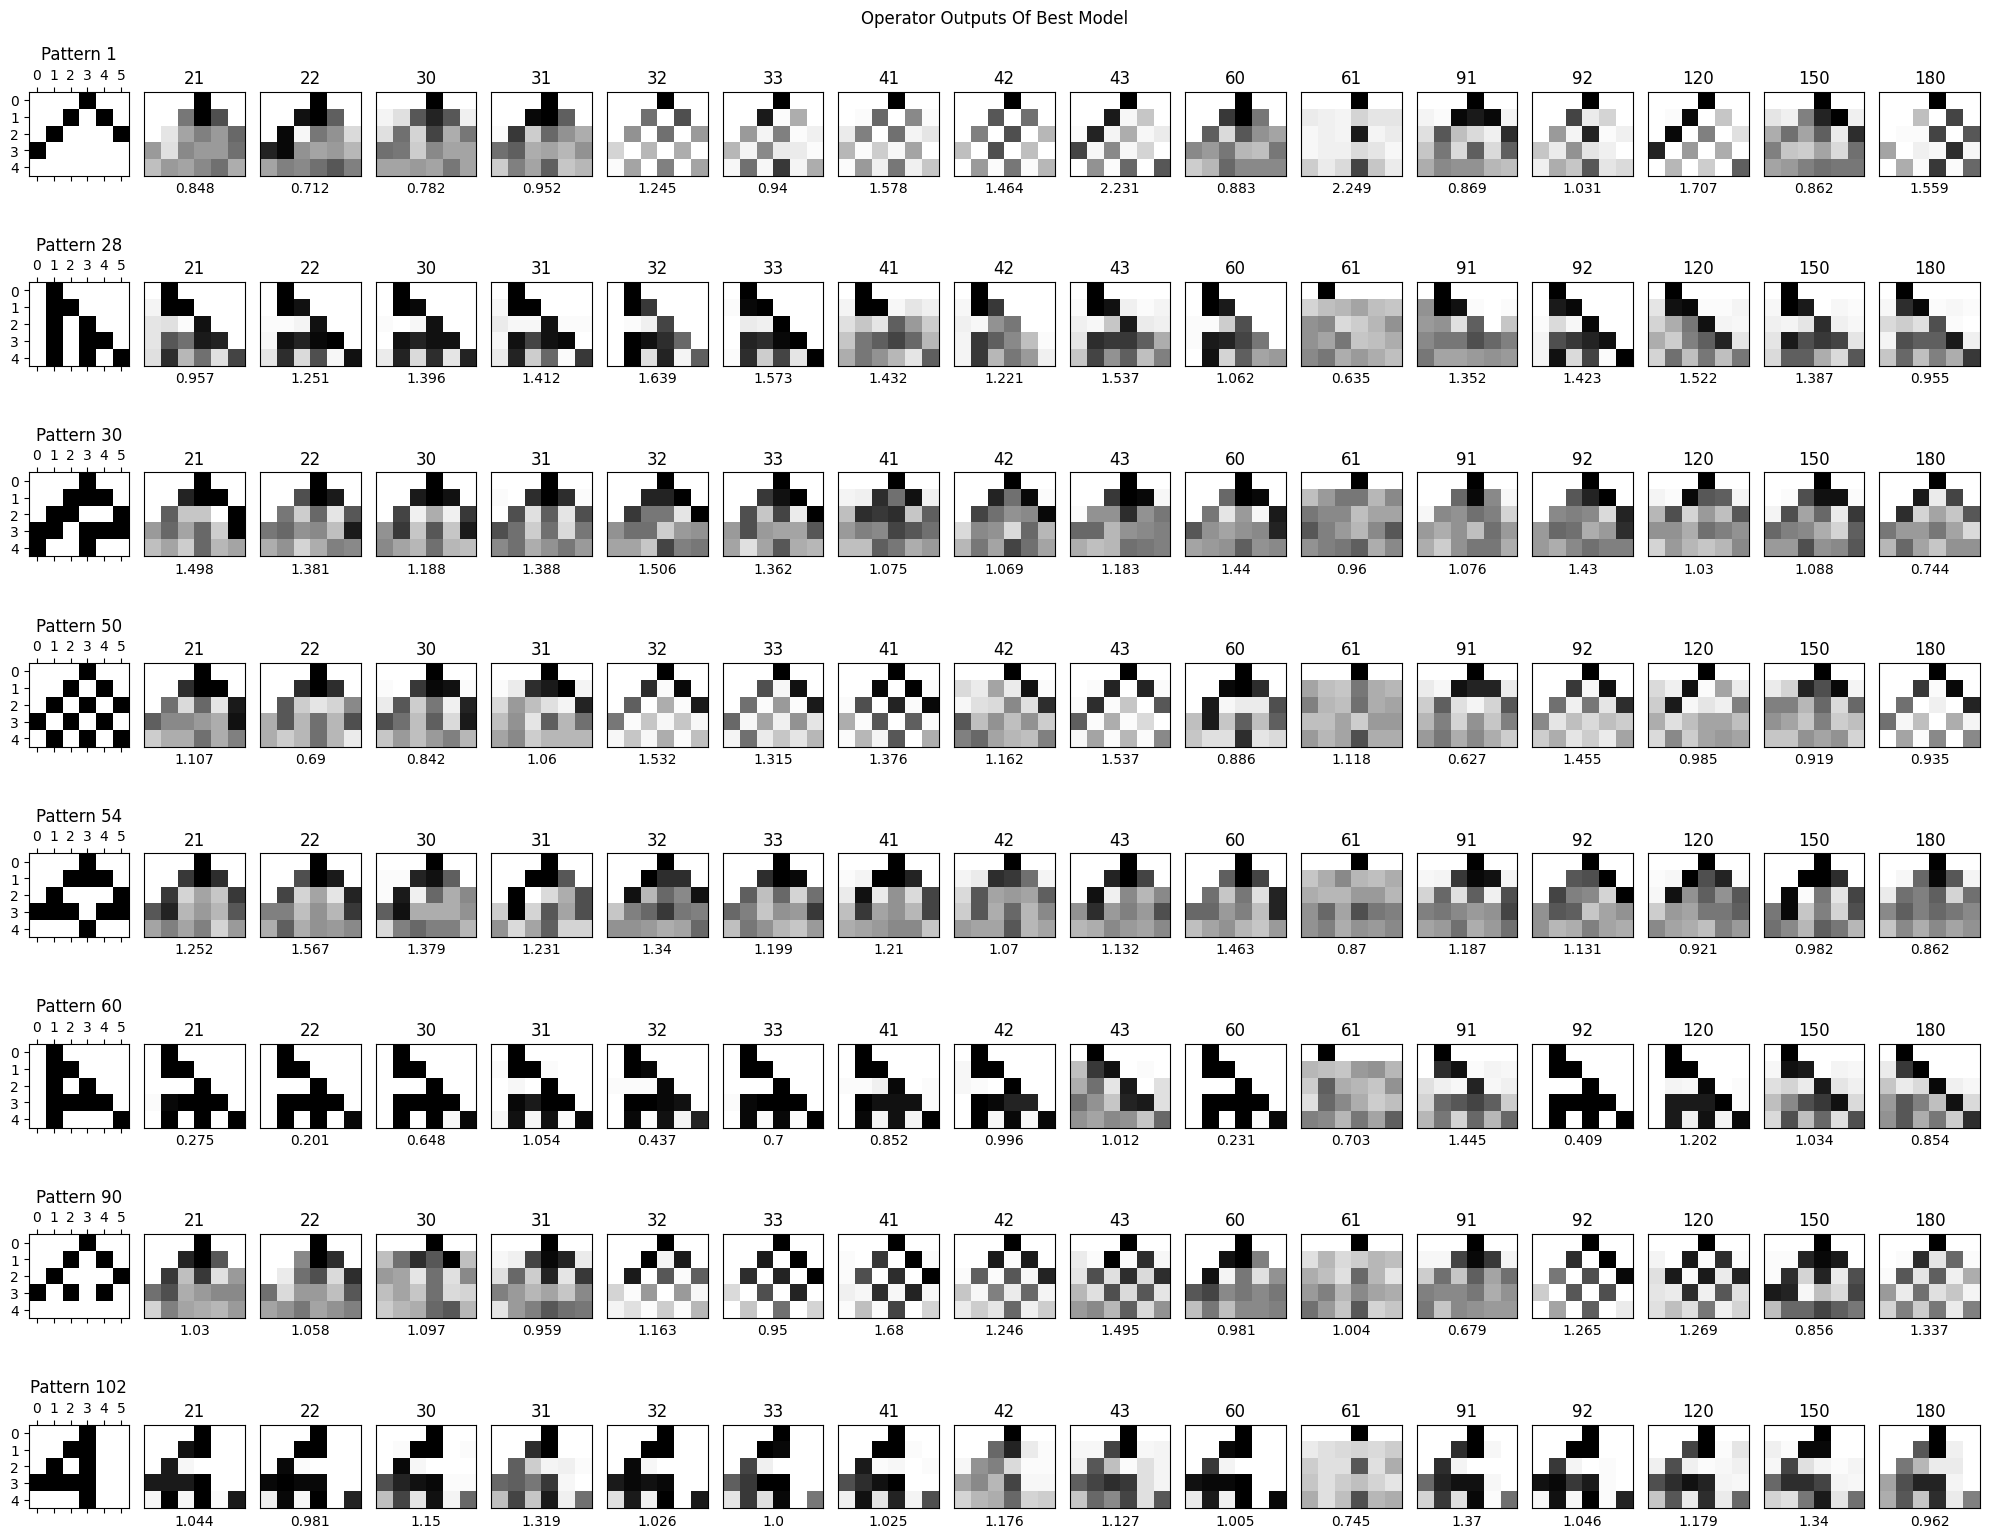

In [34]:
experiments.plot_outputs(finetunning=True)